In [1]:
import os
import glob
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from tqdm import tqdm
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from concurrent.futures.process import BrokenProcessPool
import glob
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sys
import torch
from torch.utils.data import DataLoader
import re
import yaml
from types import SimpleNamespace
import json
import gc

### load config

In [2]:
try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)

from data.dataloader_phased import StreamingParquetBuffer, PhasedReplayDataloaders
from data.normalizer import Normalizer
from visualization.plot_styling import PlotStyle

# Add paths to imports
current_dir = os.getcwd()
if 'src' not in current_dir:
    sys.path.insert(0, os.path.join(current_dir, 'src'))
else:
    sys.path.insert(0, os.path.dirname(os.path.dirname(current_dir)))

print("Python path setup complete")
print(f"Current directory: {current_dir}")


def _to_namespace(obj):
    """Convert nested dicts to SimpleNamespace recursively."""
    if isinstance(obj, dict):
        return SimpleNamespace(**{k: _to_namespace(v) for k, v in obj.items()})
    if isinstance(obj, list):
        return [_to_namespace(v) for v in obj]
    return obj


def _load_config(config_path: str = None):
    """Load YAML config and convert to SimpleNamespace."""
    if config_path is None:
        config_path = os.path.join(current_dir, "config", "config.yaml")
    
    with open(config_path, "r") as f:
        raw = yaml.safe_load(f) or {}
    
    return _to_namespace(raw)

config_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/config/config.yaml"
config = _load_config(config_path)

Python path setup complete
Current directory: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/src/data/usable


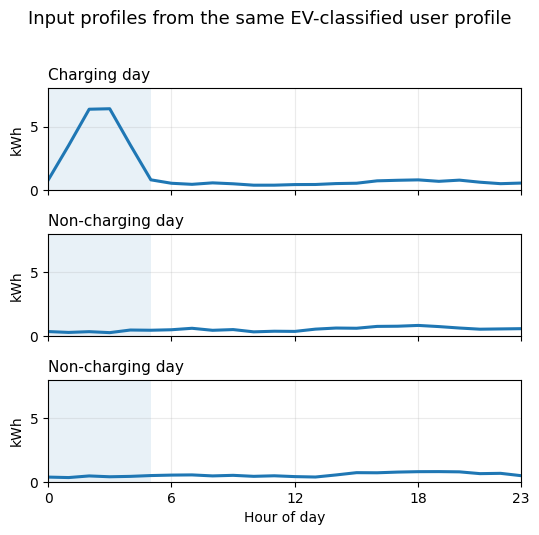

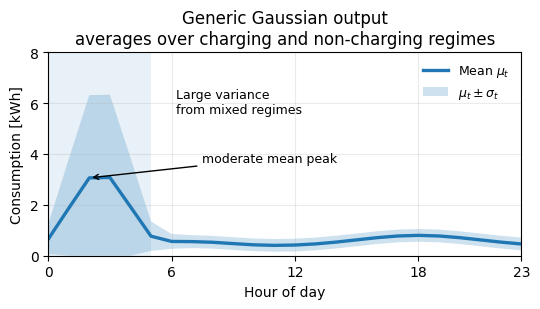

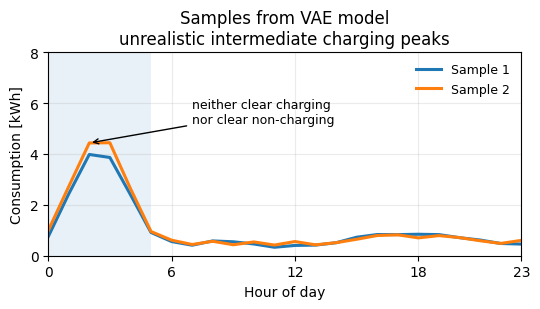

In [17]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

hours = np.arange(24)

# ------------------------------------------------------------
# Helper: flat-top EV charging profile
# ------------------------------------------------------------

def flat_top_ev_peak(hours, start=1, end=4, level=6.0, ramp=0.35):
    """
    Creates an EV charging profile with smooth ramp-up,
    approximately flat top, and smooth ramp-down.
    """

    rise = 1 / (1 + np.exp(-(hours - start) / ramp))
    fall = 1 / (1 + np.exp((hours - end) / ramp))

    peak = level * rise * fall
    peak = peak / peak.max() * level

    return peak


# ------------------------------------------------------------
# Base household profile
# ------------------------------------------------------------

base = (
    0.35
    + 0.20 * np.exp(-0.5 * ((hours - 7) / 2.0) ** 2)
    + 0.45 * np.exp(-0.5 * ((hours - 18) / 3.0) ** 2)
)


# ------------------------------------------------------------
# Create three input profiles
# ------------------------------------------------------------

charging_profile = (
    base
    + flat_top_ev_peak(hours, start=1, end=4, level=6.0, ramp=0.35)
    + np.random.normal(0, 0.05, size=24)
)

non_charging_profile_1 = (
    base
    + np.random.normal(0, 0.05, size=24)
)

non_charging_profile_2 = (
    base
    + 0.08 * np.exp(-0.5 * ((hours - 20) / 2.0) ** 2)
    + np.random.normal(0, 0.05, size=24)
)

charging_profile = np.maximum(charging_profile, 0)
non_charging_profile_1 = np.maximum(non_charging_profile_1, 0)
non_charging_profile_2 = np.maximum(non_charging_profile_2, 0)


# ------------------------------------------------------------
# Generic Gaussian model output
# ------------------------------------------------------------

model_ev_shape = flat_top_ev_peak(
    hours,
    start=1,
    end=4,
    level=1.0,
    ramp=0.45,
)

mu = base + 2.7 * model_ev_shape
sigma = 0.25 + 3.0 * model_ev_shape


# ------------------------------------------------------------
# Sampled synthetic profiles
# ------------------------------------------------------------

sample1 = (
    base
    + 3.5 * flat_top_ev_peak(hours, start=1, end=4, level=1.0, ramp=0.45)
    + np.random.normal(0, 0.08, size=24)
)

sample2 = (
    base
    + 4.1 * flat_top_ev_peak(hours, start=1, end=4, level=1.0, ramp=0.45)
    + np.random.normal(0, 0.08, size=24)
)

sample1 = np.maximum(sample1, 0)
sample2 = np.maximum(sample2, 0)


# ------------------------------------------------------------
# Shared plot settings
# ------------------------------------------------------------

charging_window_start = 0
charging_window_end = 5
ylim = (0, 8)
xticks = [0, 6, 12, 18, 23]


# ============================================================
# Figure 1: Input profiles stacked vertically
# ============================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(5.5, 5.2),
    sharex=True,
    sharey=True,
)

profiles = [
    charging_profile,
    non_charging_profile_1,
    non_charging_profile_2,
]

titles = [
    "Charging day",
    "Non-charging day",
    "Non-charging day",
]

for ax, profile, title in zip(axes, profiles, titles):
    ax.plot(hours, profile, linewidth=2.2)
    ax.axvspan(charging_window_start, charging_window_end, alpha=0.10)

    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xlim(0, 23)
    ax.set_ylim(*ylim)
    ax.grid(alpha=0.25)
    ax.set_ylabel("kWh")

axes[-1].set_xlabel("Hour of day")
axes[-1].set_xticks(xticks)

fig.suptitle(
    "Input profiles from the same EV-classified user profile",
    fontsize=13,
    y=1.02,
)

fig.tight_layout()

plt.savefig(
    "ev_problem_input_profiles_stacked.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Figure 2: Model mu and sigma output
# ============================================================

fig, ax = plt.subplots(figsize=(5.5, 3.2))

ax.plot(
    hours,
    mu,
    linewidth=2.4,
    label=r"Mean $\mu_t$",
)

ax.fill_between(
    hours,
    np.maximum(mu - sigma, 0),
    mu + sigma,
    alpha=0.22,
    label=r"$\mu_t \pm \sigma_t$",
)

ax.axvspan(charging_window_start, charging_window_end, alpha=0.10)

ax.set_title(
    "Generic Gaussian output\naverages over charging and non-charging regimes",
    fontsize=12,
)

ax.set_xlabel("Hour of day")
ax.set_ylabel("Consumption [kWh]")
ax.set_xlim(0, 23)
ax.set_ylim(*ylim)
ax.set_xticks(xticks)
ax.grid(alpha=0.25)

ax.text(
    6.2,
    5.6,
    "Large variance\nfrom mixed regimes",
    fontsize=9,
)

ax.annotate(
    "moderate mean peak",
    xy=(2, mu[2]),
    xytext=(7.5, 3.7),
    arrowprops=dict(arrowstyle="->", lw=1),
    fontsize=9,
)

ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.tight_layout()

plt.savefig(
    "ev_problem_model_mu_sigma.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Figure 3: Sampled output profiles
# ============================================================

fig, ax = plt.subplots(figsize=(5.5, 3.2))

ax.plot(
    hours,
    sample1,
    linewidth=2.2,
    label="Sample 1",
)

ax.plot(
    hours,
    sample2,
    linewidth=2.2,
    label="Sample 2",
)

ax.axvspan(charging_window_start, charging_window_end, alpha=0.10)

ax.set_title(
    "Samples from VAE model\nunrealistic intermediate charging peaks",
    fontsize=12,
)

ax.set_xlabel("Hour of day")
ax.set_ylabel("Consumption [kWh]")
ax.set_xlim(0, 23)
ax.set_ylim(*ylim)
ax.set_xticks(xticks)
ax.grid(alpha=0.25)

ax.annotate(
    "neither clear charging\nnor clear non-charging",
    xy=(2, sample2[2]),
    xytext=(7.0, 5.2),
    arrowprops=dict(arrowstyle="->", lw=1),
    fontsize=9,
)

ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.tight_layout()

plt.savefig(
    "ev_problem_sampled_profiles.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()

## Basic data analysis

### Load data

In [22]:
# Analysis data source configuration

# Options: "phased_parquet" or "hourly_csv"
analysis_data_mode = "phased_parquet"

# data_dir_parquet = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
data_dir_parquet = "/Volumes/USB/raw_profiles"
# data_dir_parquet = "/Volumes/USB/parq_hourly"

# Hourly single-phase data path (supports directory/file with parquet or csv)
# hourly_csv_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/parq_hourly"
hourly_csv_path = "/Volumes/USB/parq_hourly"
analysis_freq = "1h" if analysis_data_mode == "hourly_csv" else "15min"

output_dir_data_analysis = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis"
os.makedirs(output_dir_data_analysis, exist_ok=True)
# window_spec = WindowSpec(input_len=96, stride=96)  # used for phased loader only
plot_style = PlotStyle()

In [27]:
import glob
import os
import pandas as pd

parquet_files = sorted(glob.glob(os.path.join(data_dir_parquet, "sm_*.parquet")))
if not parquet_files:
    raise FileNotFoundError(f"No parquet files found in {data_dir_parquet}")

sample_file = parquet_files[0]
df_sample = pd.read_parquet(sample_file)
print(f"Sample file: {os.path.basename(sample_file)}")
df_sample.head()

# number of columns 
num_columns = len(df_sample.columns)
print(f"Number of columns in the sample file: {num_columns}")

Sample file: sm_100025.parquet
Number of columns in the sample file: 21


In [23]:
##############################################################################
# ----------------------------------------------------------------------------
##############################################################################
# Load data 

def save_df(df: pd.DataFrame, filename: str) -> str:
    path = os.path.join(output_dir_data_analysis, filename)
    df.to_csv(path, index=False)
    return path


def save_json(payload: dict, filename: str) -> str:
    path = os.path.join(output_dir_data_analysis, filename)
    with open(path, "w", encoding="utf-8") as f:
        import json
        json.dump(payload, f, indent=2, default=str)
    return path


if analysis_data_mode == "phased_parquet":
    parquet_files = sorted(glob.glob(os.path.join(data_dir_parquet, "*.parquet")))
    print(f"Found {len(parquet_files)} parquet files in {data_dir_parquet}")

    if not parquet_files:
        print(f"No parquet files found in {data_dir_parquet}")
        print(f"Available files: {glob.glob(os.path.join(data_dir_parquet, '*'))[:5]}")
        normalizer_3phase = None
        sm_phase_data = None
    else:
        normalizer_3phase = None
        sm_phase_data = None
        # # Fit normalizer on the same parquet files
        # normalizer_3phase = Normalizer(method="log1p_phase")
        # normalizer_3phase.fit(X=None, sm_files=parquet_files)

        # print(f"Normalizer fitted on {len(parquet_files)} files")
        # print(f"Normalizer mean: {normalizer_3phase.mean}")
        # print(f"Normalizer std: {normalizer_3phase.std}")

        # split_ratios = {
        #     "train_ratio": 0.8,
        #     "val_ratio": 0.1,
        #     "test_ratio": 0.1,
        # }

        # sm_phase_data = PhasedReplayDataloaders(
        #     sm_files=parquet_files,
        #     window_spec=window_spec,
        #     batch_size=32,
        #     replay_buffer_capacity=5000,

        #     # Important for small/analysis datasets:
        #     # if this is too high, the loader may yield nothing.
        #     min_buffer_size=0,

        #     normalizer=normalizer_3phase,
        #     num_workers=getattr(config.data.phased, "num_workers", 0),

        #     # Three-phase parquet files use active_power_p14_l1/l2/l3
        #     phased_mode=True,

        #     # Set this to True if you want hourly windows from 15-min data.
        #     hourly_aggregation=True,

        #     # Use 1000 if converting Wh/W to kWh/kW-like scale in your pipeline.
        #     # Use 1.0 if you want raw aggregated values.
        #     aggregation_divisor=1000.0,

        #     # Makes loader output tuple: (x, meter_id, timestamp, agg)
        #     output_aggregate_stream=True,

        #     # Deterministic order is usually better for analysis/preview.
        #     sample_random=False,

        #     # Usually useful for smart-meter data if missing periods should be zero.
        #     # Set False if you want to drop windows with NaNs.
        #     nan_as_zero=False,

        #     split_seed=42,
        #     split_ratios=split_ratios,

        #     # Optional filtering. Use None if you do not want to drop large windows.
        #     max_value=None,
        # )

        # print("Loaded 3-phase data from parquet files using PhasedReplayDataloaders")
        # print(f"Total files: {sm_phase_data.total_files}")

else:
    normalizer_3phase = None
    sm_phase_data = None

    if not os.path.exists(hourly_csv_path):
        raise FileNotFoundError(f"Hourly data path not found: {hourly_csv_path}")

    hourly_data_files = []
    hourly_data_format = None

    if os.path.isdir(hourly_csv_path):
        hourly_parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "hourly_measurements_*.parquet")))
        if not hourly_parquet_files:
            hourly_parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "*.parquet")))

        if hourly_parquet_files:
            hourly_data_files = hourly_parquet_files
            hourly_data_format = "parquet"
            print(f"Loaded hourly PARQUET mode from directory: {hourly_csv_path}")
            print(f"Found {len(hourly_data_files)} hourly parquet files")
        else:
            hourly_csv_files = sorted(glob.glob(os.path.join(hourly_csv_path, "hourly_measurements_*.csv")))
            if not hourly_csv_files:
                hourly_csv_files = sorted(glob.glob(os.path.join(hourly_csv_path, "*.csv")))
            if not hourly_csv_files:
                raise FileNotFoundError(f"No parquet or CSV files found in directory: {hourly_csv_path}")
            hourly_data_files = hourly_csv_files
            hourly_data_format = "csv"
            print(f"Loaded hourly CSV mode from directory: {hourly_csv_path}")
            print(f"Found {len(hourly_data_files)} hourly CSV files")
    else:
        ext = os.path.splitext(hourly_csv_path)[1].lower()
        if ext == ".parquet":
            hourly_data_files = [hourly_csv_path]
            hourly_data_format = "parquet"
            print(f"Loaded hourly PARQUET mode from file: {hourly_csv_path}")
        elif ext == ".csv":
            hourly_data_files = [hourly_csv_path]
            hourly_data_format = "csv"
            print(f"Loaded hourly CSV mode from file: {hourly_csv_path}")
        else:
            raise ValueError(f"Unsupported hourly file extension: {ext}. Use .parquet or .csv")

    hourly_parquet_files = hourly_data_files if hourly_data_format == "parquet" else []
    hourly_csv_files = hourly_data_files if hourly_data_format == "csv" else []

Found 61557 parquet files in /Volumes/USB/raw_profiles


In [46]:
# print a few rows of the first three phase parquet data file for verification

if sm_phase_data is not None:
    print("\nSample rows from the first three-phase parquet file:")
    first_file = sm_phase_data.file_list[0]
    df_sample = pq.read_table(first_file).to_pandas()
    display(df_sample.head())

In [20]:
# print a few rows of the first hourly file for verification
if hourly_data_files:
    sample_file = hourly_data_files[0]
    print(f"\nSample data from {sample_file}:")
    if hourly_data_format == "parquet":
        df_sample = pq.read_table(sample_file).to_pandas()
    else:
        df_sample = pd.read_csv(sample_file)
    display(df_sample.head())


Sample data from /Volumes/USB/parq_hourly/hourly_measurements_2023_10.parquet:


hourly_energy_consumption
meter_number timestamp_dst                                       
1000081      2023-10-01 00:00:00+00:00                       0.03
             2023-10-01 01:00:00+00:00                       0.04
             2023-10-01 02:00:00+00:00                       0.04
             2023-10-01 03:00:00+00:00                       0.03
             2023-10-01 04:00:00+00:00                       0.05

In [11]:
print(f'Number of zip codes in batch 2 (both 1-phased and 3-phased): {len({'2600': 588, '2625': 177, '2630': 513, '2640': 205, '2650': 551, '2660': 573, '2670': 375, '2750': 297, '2760': 972, '2765': 3832, '2800': 229, '2860': 431, '2970': 497, '3000': 74, '3060': 473, '3070': 257, '3080': 251, '3100': 4868, '3120': 2242, '3140': 1449, '3200': 1238, '3210': 5121, '3220': 2587, '3230': 2606, '3250': 8463, '3400': 79, '3460': 187, '3630': 5610, '3660': 1123, '3670': 556, '4000': 2204, '4040': 2440, '4050': 5092, '4070': 3634, '4305': 1502})}')

Number of zip codes in batch 2 (both 1-phased and 3-phased): 35


### Calculating distirbution of the data

#### 1-phase

In [7]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats

def load_hourly_consumption(files, file_format="parquet", value_col="hourly_energy_consumption"):
    values = []

    for f in files:
        if file_format == "parquet":
            df = pq.read_table(f).to_pandas()
        else:
            df = pd.read_csv(f)

        # Handles both normal columns and MultiIndex cases
        if value_col in df.columns:
            x = df[value_col]
        else:
            raise ValueError(f"Column {value_col} not found in {f}. Columns: {df.columns}")

        x = pd.to_numeric(x, errors="coerce")
        x = x[np.isfinite(x)]
        x = x[x >= 0]

        values.append(x)

    return pd.concat(values, ignore_index=True)

x = load_hourly_consumption(hourly_data_files, hourly_data_format)

print(f"Number of observations: {len(x):,}")
print(f"Mean μ: {x.mean():.6f}")
print(f"Std σ: {x.std(ddof=1):.6f}")
print(f"Variance σ²: {x.var(ddof=1):.6f}")
print(f"Median: {x.median():.6f}")
print(f"Min: {x.min():.6f}")
print(f"Max: {x.max():.6f}")
print(f"Skewness: {stats.skew(x):.6f}")
print(f"Kurtosis: {stats.kurtosis(x):.6f}")
print(f"Zero share: {(x == 0).mean() * 100:.2f}%")

Number of observations: 515,259,435
Mean μ: 0.892089
Std σ: 42.491837
Variance σ²: 1805.556030
Median: 0.230000
Min: 0.000000
Max: 18676.929688
Skewness: 261.560730
Kurtosis: 70831.890625
Zero share: 6.02%


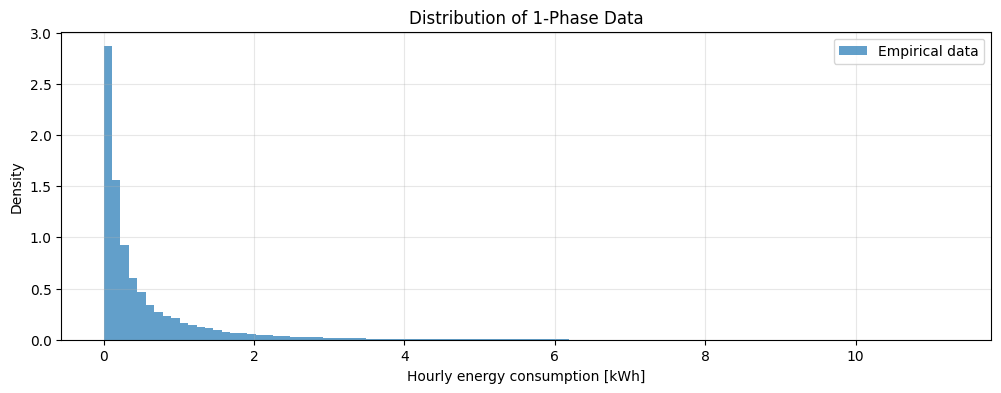

In [13]:
# make plot with normal distribution on top
mu = x.mean()
sigma = x.std(ddof=1)

grid = np.linspace(x.min(), x.quantile(0.995), 500)
# normal_pdf = stats.norm.pdf(grid, loc=mu, scale=sigma)

plt.figure(figsize=(12, 4))
plt.hist(x[x <= x.quantile(0.995)], bins=100, density=True, alpha=0.7, label="Empirical data")
# plt.plot(grid, normal_pdf, linewidth=2, label=f"Normal fit: μ={mu:.3f}, σ={sigma:.3f}")
plt.xlabel("Hourly energy consumption [kWh]")
plt.ylabel("Density")
plt.title("Distribution of 1-Phase Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Log-normalized mean μ_log: 0.366764
Log-normalized std σ_log: 0.443900


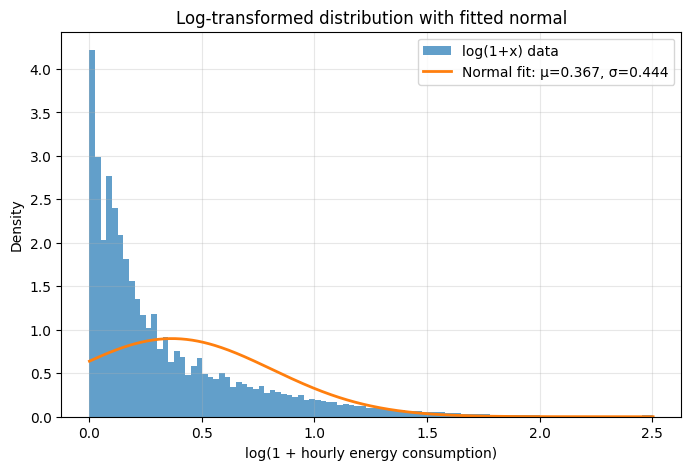

In [9]:
# make plot with log-transformed distirbution on top
y = np.log1p(x)

mu_log = y.mean()
sigma_log = y.std(ddof=1)

print(f"Log-normalized mean μ_log: {mu_log:.6f}")
print(f"Log-normalized std σ_log: {sigma_log:.6f}")

grid_log = np.linspace(y.min(), y.quantile(0.995), 500)
normal_log_pdf = stats.norm.pdf(grid_log, loc=mu_log, scale=sigma_log)

plt.figure(figsize=(8, 5))
plt.hist(y[y <= y.quantile(0.995)], bins=100, density=True, alpha=0.7, label="log(1+x) data")
plt.plot(grid_log, normal_log_pdf, linewidth=2, label=f"Normal fit: μ={mu_log:.3f}, σ={sigma_log:.3f}")
plt.xlabel("log(1 + hourly energy consumption)")
plt.ylabel("Density")
plt.title("Log-transformed distribution with fitted normal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 3-phase

In [ ]:
import glob
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats

three_phase_files = sorted(glob.glob("/Volumes/USB/raw_profiles/*.parquet"))
print(f"Found {len(three_phase_files)} 3-phase files")


def find_phase_cols(file_path):
    schema_cols = pq.ParquetFile(file_path).schema.names

    phase_cols = []
    for phase in ["l1", "l2", "l3"]:
        matches = [
            c for c in schema_cols
            if c.startswith(f"active_power_p14_{phase}")
        ]
        if not matches:
            raise ValueError(f"No active_power_p14_{phase} column found in {file_path}")
        phase_cols.append(matches[0])

    return phase_cols


def load_three_phase_hourly_aggregate(files, divisor=1000.0):
    values = []

    for f in files:
        phase_cols = find_phase_cols(f)
        cols = phase_cols + ["timestamp_dst"]

        df = pq.read_table(f, columns=cols).to_pandas()

        df["timestamp_dst"] = pd.to_datetime(df["timestamp_dst"], errors="coerce", utc=True)
        df = df.dropna(subset=["timestamp_dst"]).set_index("timestamp_dst")

        for col in phase_cols:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        # 15-min phase values -> hourly mean, then aggregate across phases
        hourly = df[phase_cols].resample("1h").mean().sum(axis=1, skipna=True)

        # scale to kWh/kW-like units if your raw values are Wh/W-like
        hourly = hourly / divisor

        hourly = hourly[np.isfinite(hourly)]
        hourly = hourly[hourly >= 0]

        values.append(hourly)

    return pd.concat(values, ignore_index=True)


x3_hourly_aggregate = load_three_phase_hourly_aggregate(three_phase_files)

print(f"Number of observations: {len(x3_hourly_aggregate):,}")
print(f"Mean μ: {x3_hourly_aggregate.mean():.6f}")
print(f"Std σ: {x3_hourly_aggregate.std(ddof=1):.6f}")
print(f"Variance σ²: {x3_hourly_aggregate.var(ddof=1):.6f}")
print(f"Median: {x3_hourly_aggregate.median():.6f}")
print(f"Min: {x3_hourly_aggregate.min():.6f}")
print(f"Max: {x3_hourly_aggregate.max():.6f}")
print(f"Skewness: {stats.skew(x3_hourly_aggregate):.6f}")
print(f"Kurtosis: {stats.kurtosis(x3_hourly_aggregate):.6f}")
print(f"Zero share: {(x3_hourly_aggregate == 0).mean() * 100:.2f}%")

plt.figure(figsize=(12, 4))
plt.hist(
    x3_hourly_aggregate[x3_hourly_aggregate <= x3_hourly_aggregate.quantile(0.995)],
    bins=100,
    density=True,
    alpha=0.7,
    label="Empirical data",
)
plt.xlabel("Hourly aggregated household consumption [kWh]")
plt.ylabel("Density")
plt.title("Distribution of 3-Phase Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Found 61557 3-phase files


Found 61557 3-phase files
Number of observations: 394,703,484
Mean μ: 0.653301
Std σ: 3.214176
Variance σ²: 10.330929
Median: 0.170000
Min: 0.000000
Max: 569.877991
Skewness: 52.185608
Kurtosis: 4140.359375
Zero share: 26.60%


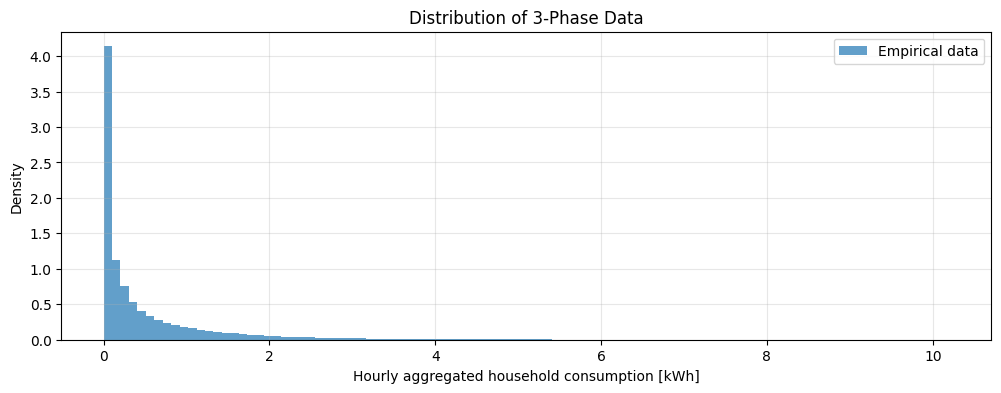

In [36]:
import glob
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats

three_phase_files = sorted(glob.glob("/Volumes/USB/raw_profiles/*.parquet"))
print(f"Found {len(three_phase_files)} 3-phase files")


def find_phase_cols(file_path):
    schema_cols = pq.ParquetFile(file_path).schema.names

    phase_cols = []
    for phase in ["l1", "l2", "l3"]:
        matches = [
            c for c in schema_cols
            if c.startswith(f"active_power_p14_{phase}")
        ]
        if not matches:
            raise ValueError(f"No active_power_p14_{phase} column found in {file_path}")
        phase_cols.append(matches[0])

    return phase_cols


def load_three_phase_hourly_aggregate(files, divisor=1000.0):
    values = []

    for f in files:
        phase_cols = find_phase_cols(f)
        cols = phase_cols + ["timestamp_dst"]

        df = pq.read_table(f, columns=cols).to_pandas()

        # Sometimes timestamp_dst is stored as index metadata, not as a normal column
        if "timestamp_dst" not in df.columns:
            df = df.reset_index()

        if "timestamp_dst" not in df.columns:
            raise KeyError(f"'timestamp_dst' not found in columns or index for {f}. Columns: {df.columns}")

        df["timestamp_dst"] = pd.to_datetime(df["timestamp_dst"], errors="coerce", utc=True)
        df = df.dropna(subset=["timestamp_dst"]).set_index("timestamp_dst")

        for col in phase_cols:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        # 15-min phase values -> hourly mean, then aggregate across phases
        hourly = df[phase_cols].resample("1h").mean().sum(axis=1, skipna=True)

        # scale to kWh/kW-like units if your raw values are Wh/W-like
        hourly = hourly / divisor

        hourly = hourly[np.isfinite(hourly)]
        hourly = hourly[hourly >= 0]

        values.append(hourly)

    return pd.concat(values, ignore_index=True)


x3_hourly_aggregate = load_three_phase_hourly_aggregate(three_phase_files)

print(f"Number of observations: {len(x3_hourly_aggregate):,}")
print(f"Mean μ: {x3_hourly_aggregate.mean():.6f}")
print(f"Std σ: {x3_hourly_aggregate.std(ddof=1):.6f}")
print(f"Variance σ²: {x3_hourly_aggregate.var(ddof=1):.6f}")
print(f"Median: {x3_hourly_aggregate.median():.6f}")
print(f"Min: {x3_hourly_aggregate.min():.6f}")
print(f"Max: {x3_hourly_aggregate.max():.6f}")
print(f"Skewness: {stats.skew(x3_hourly_aggregate):.6f}")
print(f"Kurtosis: {stats.kurtosis(x3_hourly_aggregate):.6f}")
print(f"Zero share: {(x3_hourly_aggregate == 0).mean() * 100:.2f}%")

plt.figure(figsize=(12, 4))
plt.hist(
    x3_hourly_aggregate[x3_hourly_aggregate <= x3_hourly_aggregate.quantile(0.995)],
    bins=100,
    density=True,
    alpha=0.7,
    label="Empirical data",
)
plt.xlabel("Hourly aggregated household consumption [kWh]")
plt.ylabel("Density")
plt.title("Distribution of 3-Phase Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

bad

In [27]:
def load_hourly_consumption(files, file_format="parquet", value_col="hourly_energy_consumption"):
    values = []

    for f in files:
        if file_format == "parquet":
            df = pq.read_table(f).to_pandas()
        else:
            df = pd.read_csv(f)

        # Handles both normal columns and MultiIndex cases
        if value_col in df.columns:
            x = df[value_col]
        else:
            raise ValueError(f"Column {value_col} not found in {f}. Columns: {df.columns}")

        x = pd.to_numeric(x, errors="coerce")
        x = x[np.isfinite(x)]
        x = x[x >= 0]

        values.append(x)

    return pd.concat(values, ignore_index=True)

x = load_hourly_consumption(hourly_data_files, hourly_data_format)

print(f"Number of observations: {len(x):,}")
print(f"Mean μ: {x.mean():.6f}")
print(f"Std σ: {x.std(ddof=1):.6f}")
print(f"Variance σ²: {x.var(ddof=1):.6f}")
print(f"Median: {x.median():.6f}")
print(f"Min: {x.min():.6f}")
print(f"Max: {x.max():.6f}")
print(f"Skewness: {stats.skew(x):.6f}")
print(f"Kurtosis: {stats.kurtosis(x):.6f}")
print(f"Zero share: {(x == 0).mean() * 100:.2f}%")

Number of observations: 515,259,435
Mean μ: 0.892089
Std σ: 42.491837
Variance σ²: 1805.556030
Median: 0.230000
Min: 0.000000
Max: 18676.929688
Skewness: 261.560730
Kurtosis: 70831.890625
Zero share: 6.02%


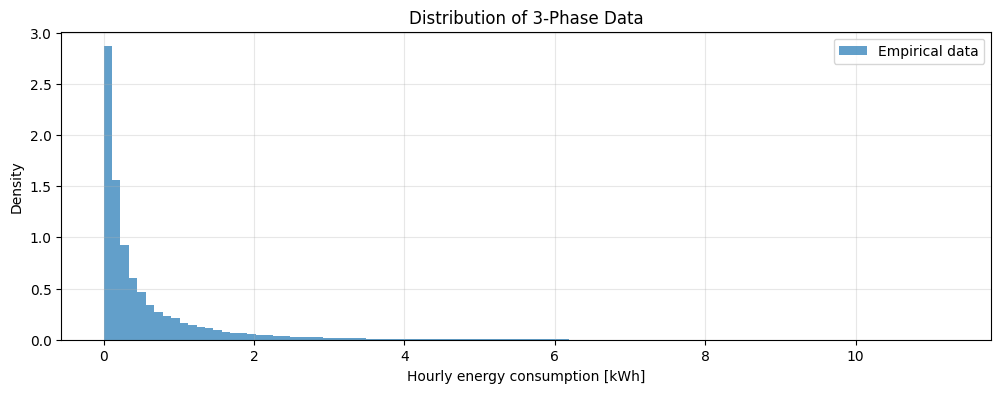

In [30]:
# make plot with normal distribution on top
mu = x.mean()
sigma = x.std(ddof=1)

grid = np.linspace(x.min(), x.quantile(0.995), 500)
# normal_pdf = stats.norm.pdf(grid, loc=mu, scale=sigma)

plt.figure(figsize=(12, 4))
plt.hist(x[x <= x.quantile(0.995)], bins=100, density=True, alpha=0.7, label="Empirical data")
# plt.plot(grid, normal_pdf, linewidth=2, label=f"Normal fit: μ={mu:.3f}, σ={sigma:.3f}")
plt.xlabel("Hourly energy consumption [kWh]")
plt.ylabel("Density")
plt.title("Distribution of 3-Phase Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# make plot with log-transformed distirbution on top
y = np.log1p(x)

mu_log = y.mean()
sigma_log = y.std(ddof=1)

print(f"Log-normalized mean μ_log: {mu_log:.6f}")
print(f"Log-normalized std σ_log: {sigma_log:.6f}")

grid_log = np.linspace(y.min(), y.quantile(0.995), 500)
normal_log_pdf = stats.norm.pdf(grid_log, loc=mu_log, scale=sigma_log)

plt.figure(figsize=(8, 5))
plt.hist(y[y <= y.quantile(0.995)], bins=100, density=True, alpha=0.7, label="log(1+x) data")
plt.plot(grid_log, normal_log_pdf, linewidth=2, label=f"Normal fit: μ={mu_log:.3f}, σ={sigma_log:.3f}")
plt.xlabel("log(1 + hourly energy consumption)")
plt.ylabel("Density")
plt.title("Log-transformed distribution with fitted normal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Plotting each phase & aggregated

Plotting: `selected_meter` and `selected_day` to plot a specific smart meter and exact day.

In [7]:
class SmartMeterDayPlotter:
    def __init__(
        self,
        data_dir_parquet: str,
        verbose: bool = False,
        data_mode: str = "phased_parquet",
        hourly_csv_path: str = None,
        hourly_data_path: str = None,
        interval_freq: str = "15min",
        hourly_energy_col: str = "hourly_energy_consumption",
    ):
        self.data_dir_parquet = data_dir_parquet
        self.verbose = verbose
        self.data_mode = data_mode
        self.hourly_data_path = hourly_data_path if hourly_data_path is not None else hourly_csv_path
        self.hourly_csv_path = self.hourly_data_path
        self.interval_freq = interval_freq
        self.hourly_energy_col = hourly_energy_col
        self.hourly_df = None
        self.meter_to_file = self._build_meter_file_map()

    def _log(self, msg: str):
        if self.verbose:
            print(msg)

    def _build_meter_file_map(self):
        if self.data_mode == "hourly_csv":
            if self.hourly_data_path is None or (not os.path.exists(self.hourly_data_path)):
                raise FileNotFoundError(f"Hourly data path not found: {self.hourly_data_path}")

            if os.path.isdir(self.hourly_data_path):
                hourly_files = sorted(glob.glob(os.path.join(self.hourly_data_path, "hourly_measurements_*.parquet")))
                if not hourly_files:
                    hourly_files = sorted(glob.glob(os.path.join(self.hourly_data_path, "*.parquet")))
                if not hourly_files:
                    hourly_files = sorted(glob.glob(os.path.join(self.hourly_data_path, "hourly_measurements_*.csv")))
                if not hourly_files:
                    hourly_files = sorted(glob.glob(os.path.join(self.hourly_data_path, "*.csv")))
                if not hourly_files:
                    raise FileNotFoundError(f"No parquet or CSV files found in directory: {self.hourly_data_path}")
            else:
                hourly_files = [self.hourly_data_path]

            frames = []
            for p in hourly_files:
                ext = os.path.splitext(p)[1].lower()
                if ext == ".parquet":
                    df_part = pd.read_parquet(p)
                    if isinstance(df_part.index, pd.MultiIndex) or (df_part.index.name in ["meter_number", "meter_id", "timestamp", "timestamp_dst", "timestamp_utc"]):
                        df_part = df_part.reset_index()
                else:
                    df_part = pd.read_csv(p)

                if "meter_number" not in df_part.columns:
                    alt_meter_col = next((c for c in ["meter_id", "smart_meter_id", "sm_id"] if c in df_part.columns), None)
                    if alt_meter_col is not None:
                        df_part = df_part.rename(columns={alt_meter_col: "meter_number"})

                df_part["__source_file"] = os.path.basename(p)
                frames.append(df_part)

            self.hourly_df = pd.concat(frames, ignore_index=True)
            if "meter_number" not in self.hourly_df.columns:
                raise ValueError("Hourly data files must contain meter_number (or meter_id/smart_meter_id/sm_id).")

            meters = sorted(pd.to_numeric(self.hourly_df["meter_number"], errors="coerce").dropna().astype(int).unique().tolist())
            return {meter: self.hourly_data_path for meter in meters}

        parquet_files = sorted(glob.glob(f"{self.data_dir_parquet}/*.parquet"))
        meter_to_file = {}
        for p in parquet_files:
            m = re.search(r"sm_(\d+)\.parquet$", os.path.basename(p))
            if m:
                meter_to_file[int(m.group(1))] = p
        return meter_to_file

    def available_meters(self):
        return sorted(self.meter_to_file.keys())

    @staticmethod
    def _pick_col(cols, base):
        matches = [c for c in cols if c.startswith(base)]
        return matches[0] if matches else None

    def _pick_time_column(self, df):
        cols = list(df.columns)

        for c in ["timestamp_utc", "timestamp_dst", "timestamp"]:
            if c in cols:
                return c

        pref = []
        for c in cols:
            lc = c.lower()
            if lc.startswith("timestamp_utc") or lc.startswith("timestamp_dst") or lc.startswith("timestamp"):
                pref.append(c)

        if "__index_level_0__" in cols:
            pref.append("__index_level_0__")

        broad = [c for c in cols if ("time" in c.lower() or "date" in c.lower()) and c not in pref]
        candidates = pref + broad

        best_col = None
        best_score = -1.0
        for c in candidates:
            parsed = pd.to_datetime(df[c], errors="coerce", utc=True)
            score = parsed.notna().mean()
            if score > best_score:
                best_score = score
                best_col = c

        if best_col is not None and best_score > 0:
            self._log(f"Detected time column: {best_col} (parse success={best_score:.1%})")
            return best_col

        idx_parsed = pd.to_datetime(df.index, errors="coerce", utc=True)
        idx_score = idx_parsed.notna().mean() if len(idx_parsed) > 0 else 0.0
        if idx_score > 0:
            self._log(f"Using dataframe index as timestamp (parse success={idx_score:.1%})")
            return "__index__"

        return None

    def _load_meter_dataframe(self, selected_meter: int):
        available_meters = self.available_meters()
        self._log(f"Found {len(available_meters)} meters in parquet files")
        self._log(f"Available meters: {available_meters}")

        if selected_meter not in self.meter_to_file:
            raise ValueError(f"Meter {selected_meter} not found. Choose one of: {available_meters}")

        if self.data_mode == "hourly_csv":
            if self.hourly_df is None:
                # Build once from one file or all files in directory.
                self.meter_to_file = self._build_meter_file_map()

            df_meter = self.hourly_df[pd.to_numeric(self.hourly_df["meter_number"], errors="coerce") == selected_meter].copy()
            if df_meter.empty:
                raise ValueError(f"No rows found for meter {selected_meter} in hourly data")

            time_col = self._pick_time_column(df_meter)
            if time_col is None:
                raise ValueError("No usable timestamp source found in hourly data")

            if self.hourly_energy_col not in df_meter.columns:
                raise ValueError(f"Hourly data missing required column: {self.hourly_energy_col}")

            timestamp_series = df_meter.index if time_col == "__index__" else df_meter[time_col]
            agg_kwh = pd.to_numeric(df_meter[self.hourly_energy_col], errors="coerce").fillna(0.0)
            agg_wh = agg_kwh * 1000.0

            df = pd.DataFrame({
                "timestamp": pd.to_datetime(timestamp_series, utc=True, errors="coerce"),
                "L1": agg_wh,
                "L2": 0.0,
                "L3": 0.0,
            }).dropna(subset=["timestamp"]).sort_values("timestamp")
        else:
            parquet_path = self.meter_to_file[selected_meter]
            self._log(f"Using file: {parquet_path}")

            df_raw = pd.read_parquet(parquet_path)
            self._log(f"Columns in file: {list(df_raw.columns)}")
            self._log(f"Index type: {type(df_raw.index).__name__}")

            time_col = self._pick_time_column(df_raw)
            if time_col is None:
                raise ValueError("No usable timestamp source found. " + f"Columns were: {list(df_raw.columns)}")

            l1_col = self._pick_col(df_raw.columns, "active_power_p14_l1")
            l2_col = self._pick_col(df_raw.columns, "active_power_p14_l2")
            l3_col = self._pick_col(df_raw.columns, "active_power_p14_l3")

            if l1_col is None and l2_col is None and l3_col is None:
                raise ValueError("No phase columns found (active_power_p14_l1/l2/l3). " + f"Columns were: {list(df_raw.columns)}")

            timestamp_series = df_raw.index if time_col == "__index__" else df_raw[time_col]

            df = pd.DataFrame({
                "timestamp": pd.to_datetime(timestamp_series, utc=True, errors="coerce"),
                "L1": pd.to_numeric(df_raw[l1_col], errors="coerce") if l1_col else np.nan,
                "L2": pd.to_numeric(df_raw[l2_col], errors="coerce") if l2_col else np.nan,
                "L3": pd.to_numeric(df_raw[l3_col], errors="coerce") if l3_col else np.nan,
            }).dropna(subset=["timestamp"]).sort_values("timestamp")

        df = df.set_index("timestamp")
        df[["L1", "L2", "L3"]] = df[["L1", "L2", "L3"]].fillna(0.0)
        df["Aggregated"] = df[["L1", "L2", "L3"]].sum(axis=1)

        self._log(f"Overall date range (UTC): {df.index.min()} -> {df.index.max()}")
        self._log(f"Non-zero rows (aggregated): {(df['Aggregated'] > 0).sum()} / {len(df)}")
        return df

    def _resolve_day(self, df, selected_day="auto", top_n_days=10):
        daily = df["Aggregated"].groupby(df.index.floor("D")).sum().sort_values(ascending=False)
        non_zero_daily = daily[daily > 0]

        if len(non_zero_daily) == 0:
            self._log("Warning: all daily totals are zero for this meter.")
        else:
            self._log(f"Top {top_n_days} non-zero days by aggregated daily energy (kWh):")
            self._log(str((non_zero_daily.head(top_n_days) / 1000.0).round(3)))

        if selected_day == "auto":
            selected_day_ts = non_zero_daily.index[0] if len(non_zero_daily) > 0 else daily.index[0]
            selected_day = selected_day_ts.strftime("%Y-%m-%d")
            self._log(f"Auto-selected day: {selected_day}")

        return selected_day

    def plot_day(self, selected_meter: int, selected_day="auto", show_distribution=True, top_n_days=10, show_plot_inline=True):
        df = self._load_meter_dataframe(selected_meter)
        selected_day = self._resolve_day(df, selected_day=selected_day, top_n_days=top_n_days)

        day_start = pd.Timestamp(selected_day, tz="UTC")
        day_end = day_start + pd.Timedelta(days=1)

        day_df = df[(df.index >= day_start) & (df.index < day_end)][["L1", "L2", "L3"]].copy()

        if day_df.empty:
            min_day = df.index.min().strftime("%Y-%m-%d")
            max_day = df.index.max().strftime("%Y-%m-%d")
            raise ValueError(f"No data for meter {selected_meter} on {selected_day}. Available date range: {min_day} to {max_day}")

        full_idx = pd.date_range(start=day_start, end=day_end, freq=self.interval_freq, tz="UTC", inclusive="left")
        day_df = day_df.reindex(full_idx).fillna(0.0)
        day_df["Aggregated"] = day_df[["L1", "L2", "L3"]].sum(axis=1)

        self._log(f"Selected meter: {selected_meter}")
        self._log(f"Selected day (UTC): {selected_day}")
        self._log(f"Rows in selected day (after reindex): {len(day_df)}")
        self._log(str(day_df.head()))
        self._log(f"Day total (aggregated): {day_df['Aggregated'].sum() / 1000.0:.3f} kWh")

        if self.data_mode == "hourly_csv":
            fig, ax = plt.subplots(1, 1, figsize=(18,6), sharex=True)
            ax.plot(
                day_df.index,
                day_df["Aggregated"].values,
                linewidth=plot_style.linewidth,
                alpha=0.9,
                marker=plot_style.marker,
                markersize=4,
                linestyle=plot_style.linestyle,
                color=plot_style.get_color_original(),
            )
            ax.set_title(f"Selected SM | {selected_day} | Aggregated")
            ax.set_ylabel("Energy (Wh)")
            ax.set_xlabel("Time (UTC)")
            ax.grid(True, alpha=0.3)
            ax.legend([f"Total: {day_df['Aggregated'].sum() / 1000.0:.2f} kWh"], loc="upper right")
            labels = ["Aggregated"]
            line_colors = [plot_style.get_color_original()]
        else:
            fig, axes = plt.subplots(4, 1, figsize=plot_style.get_figsize(height_multiplier=2.2), sharex=True)
            labels = ["L1", "L2", "L3", "Aggregated"]
            line_colors = [plot_style.get_color(0), plot_style.get_color(1), plot_style.get_color(2), plot_style.get_color_original()]

            for i, col in enumerate(labels):
                axes[i].plot(
                    day_df.index,
                    day_df[col].values,
                    linewidth=plot_style.linewidth,
                    alpha=0.9,
                    marker=plot_style.marker,
                    markersize=4,
                    linestyle=plot_style.linestyle,
                    color=line_colors[i],
                )
                axes[i].set_title(f"SM {selected_meter} | {selected_day} | {col}")
                axes[i].set_ylabel("Energy (Wh)")
                axes[i].grid(True, alpha=0.3)
                axes[i].legend([f"Total: {day_df[col].sum() / 1000.0:.2f} kWh"], loc="upper right")

            axes[-1].set_xlabel("Time (UTC)")

        plt.tight_layout()
        day_plot_path = os.path.join(output_dir_data_analysis, f"sm_{selected_meter}_{selected_day}_timeseries.png")
        fig.savefig(day_plot_path, dpi=200, bbox_inches="tight")
        print(f"Saved plot: {day_plot_path}")
        if show_plot_inline:
            plt.show()
        plt.close(fig)

        if show_distribution:
            if self.data_mode == "hourly_csv":
                fig, ax = plt.subplots(1, 1, figsize=(18,6))
                ax.hist(day_df["Aggregated"].values, bins=40, edgecolor="black", alpha=0.75, color=plot_style.get_color_original())
                ax.set_title("Aggregated distribution")
                ax.set_xlabel("Energy (Wh)")
                ax.set_ylabel("Frequency")
                ax.grid(True, alpha=0.3)
            else:
                fig, axes = plt.subplots(2, 2, figsize=plot_style.get_figsize(height_multiplier=1.5))
                for idx, (ax, col) in enumerate(zip(axes.flatten(), labels)):
                    hist_color = line_colors[idx]
                    ax.hist(day_df[col].values, bins=40, edgecolor="black", alpha=0.75, color=hist_color)
                    ax.set_title(f"{col} distribution")
                    ax.set_xlabel("Energy (Wh)")
                    ax.set_ylabel("Frequency")
                    ax.grid(True, alpha=0.3)
            plt.tight_layout()
            dist_plot_path = os.path.join(output_dir_data_analysis, f"sm_{selected_meter}_{selected_day}_distribution.png")
            fig.savefig(dist_plot_path, dpi=200, bbox_inches="tight")
            print(f"Saved plot: {dist_plot_path}")
            if show_plot_inline:
                plt.show()
            plt.close(fig)

        return day_df
    

def make_plotter(verbose: bool = False) -> SmartMeterDayPlotter:
    return SmartMeterDayPlotter(
        data_dir_parquet=data_dir_parquet,
        verbose=verbose,
        data_mode=analysis_data_mode,
        hourly_csv_path=hourly_csv_path,
        hourly_data_path=hourly_csv_path,
        interval_freq=analysis_freq,
        hourly_energy_col="hourly_energy_consumption",
    )


##### 3-phase

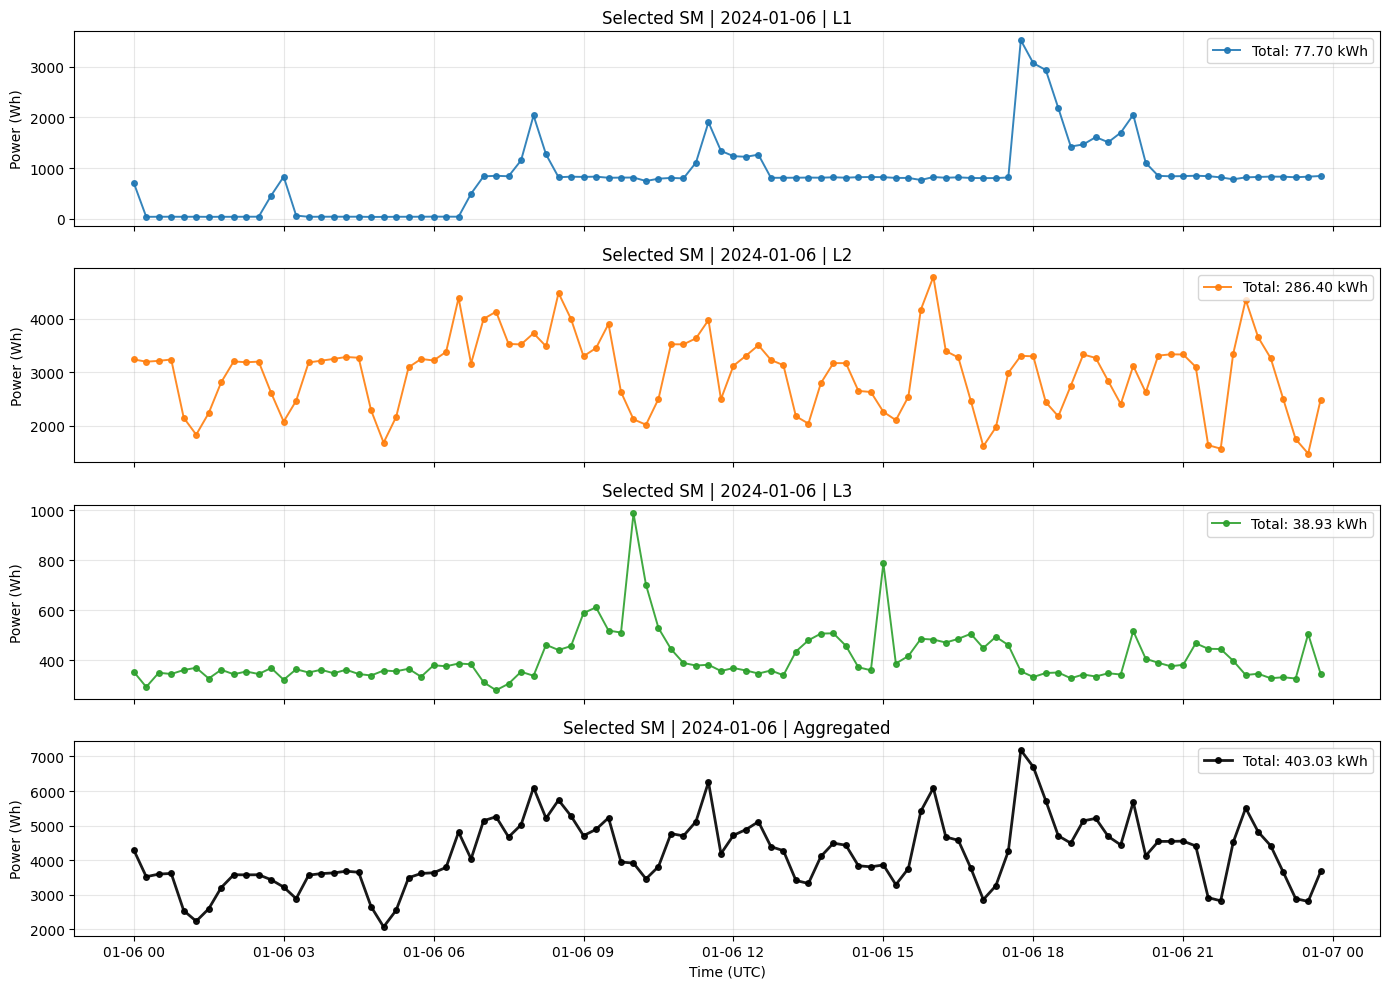

Saved selected day profile: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/selected_day_profile.csv


In [12]:
# Plot one day for one 3-phase meter using a column-only parquet read
import os
import pandas as pd
import matplotlib.pyplot as plt

selected_meter = 87
selected_day = "2024-01-06"
parquet_path = f"/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles/sm_{selected_meter}.parquet"

if not os.path.exists(parquet_path):
    raise FileNotFoundError(f"Missing parquet file: {parquet_path}")

phase_cols = [
    f"active_power_p14_l1_{selected_meter}",
    f"active_power_p14_l2_{selected_meter}",
    f"active_power_p14_l3_{selected_meter}",
]

day_df = pd.read_parquet(parquet_path, columns=phase_cols).rename(
    columns={
        phase_cols[0]: "L1",
        phase_cols[1]: "L2",
        phase_cols[2]: "L3",
    }
)

day_df = day_df.loc[day_df.index.strftime("%Y-%m-%d") == selected_day].copy()
if day_df.empty:
    raise ValueError(f"No data found for meter {selected_meter} on {selected_day}")

day_df = day_df.fillna(0.0)
day_df["Aggregated"] = day_df[["L1", "L2", "L3"]].sum(axis=1)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
series_info = [
    ("L1", "tab:blue"),
    ("L2", "tab:orange"),
    ("L3", "tab:green"),
    ("Aggregated", "black"),
]

for ax, (col, color) in zip(axes, series_info):
    ax.plot(day_df.index, day_df[col], linewidth=1.4 if col != "Aggregated" else 2.0, color=color, alpha=0.9, marker="o", markersize=4, linestyle="-")
    ax.set_title(f"Selected SM | {selected_day} | {col}")
    ax.set_ylabel("Power (Wh)")
    ax.legend([f"Total: {day_df[col].sum() / 1000.0:.2f} kWh"], loc="upper right")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (UTC)")
plt.tight_layout()
plt.show()

day_df_path = save_df(day_df.reset_index().rename(columns={day_df.index.name or "index": "timestamp_utc"}), "selected_day_profile.csv")
print(f"Saved selected day profile: {day_df_path}")

##### What this plot shows
This figure shows one selected day for one smart meter.
The first three subplots are the individual phase measurements, L1, L2, and L3.
The bottom subplot is the aggregated phase, which is the sum of those three phases at each timestamp.
The x-axis is time during the selected day, and the y-axis is power in Wh.

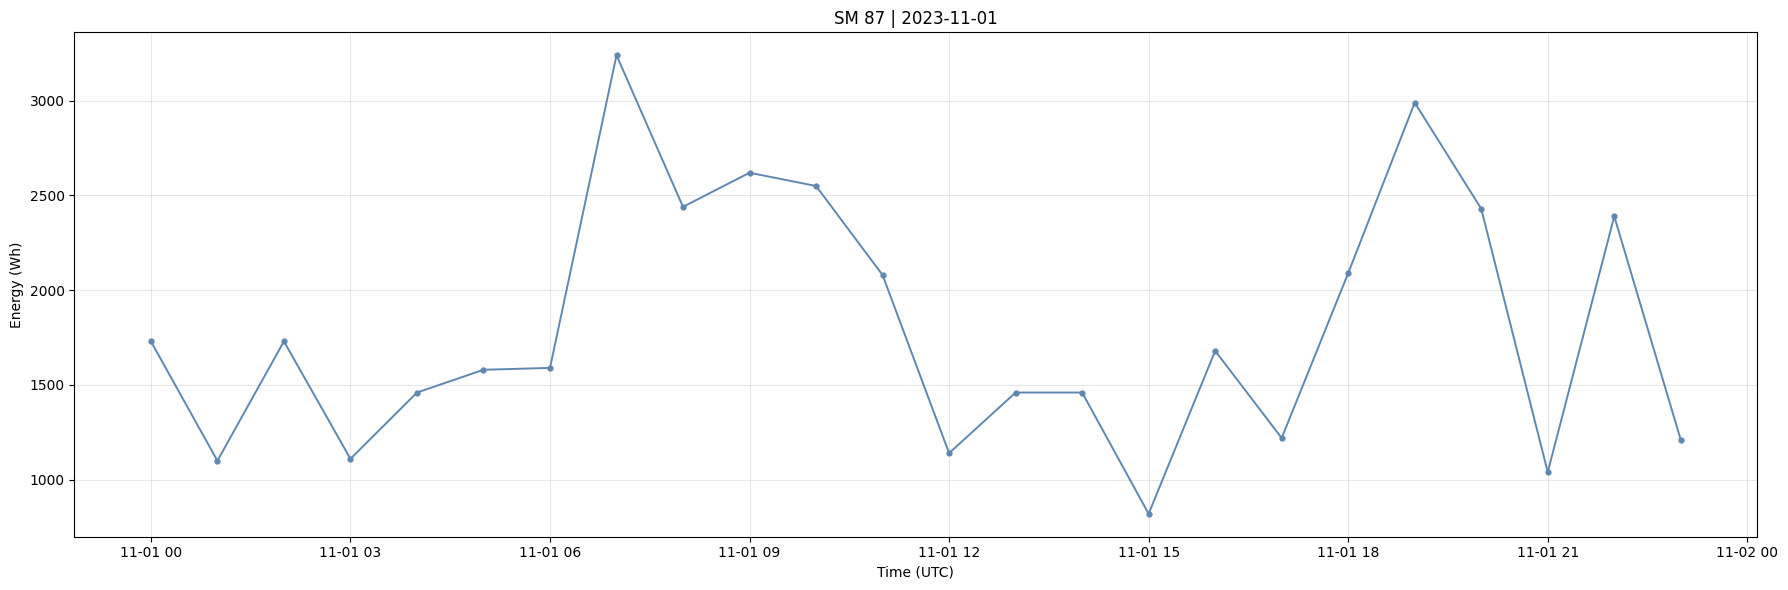

Saved selected day profile: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/selected_day_profile.csv
Source parquet file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/parq_hourly/hourly_measurements_2023_11.parquet


,timestamp_utc,meter_id,energy_kwh
0,2023-11-01 00:00:00+00:00,87,1.73
1,2023-11-01 01:00:00+00:00,87,1.10
2,2023-11-01 02:00:00+00:00,87,1.73
3,2023-11-01 03:00:00+00:00,87,1.11
4,2023-11-01 04:00:00+00:00,87,1.46
5,2023-11-01 05:00:00+00:00,87,1.58
6,2023-11-01 06:00:00+00:00,87,1.59
7,2023-11-01 07:00:00+00:00,87,3.24
8,2023-11-01 08:00:00+00:00,87,2.44
9,2023-11-01 09:00:00+00:00,87,2.62


In [8]:
# Plot one single day for one meter (1-phase hourly parquet, streaming + robust fallback)
import os
import glob
import random
import gc
import pyarrow.parquet as pq

# USER INPUTS
selected_meter = 87
selected_day = "auto"  # "auto" or e.g. "2023-10-03"
allow_random_fallback = True
random_seed = 42
batch_size = 250_000

if analysis_data_mode != "hourly_csv":
    raise ValueError("Set analysis_data_mode='hourly_csv' for 1-phase hourly parquet data.")
if not os.path.isdir(hourly_csv_path):
    raise ValueError(f"Expected hourly_csv_path to be a directory, got: {hourly_csv_path}")

random.seed(random_seed)
energy_col_preferred = globals().get("hourly_energy_col", "hourly_energy_consumption")

meter_candidates = ["meter_number", "meter_id", "smart_meter_id", "sm_id"]
time_candidates = ["timestamp_utc", "timestamp_dst", "timestamp", "datetime", "time"]
energy_candidates = [energy_col_preferred, "hourly_energy_consumption", "agg_wh"]

# Use discovered files when available, otherwise discover parquet files in directory
if "hourly_data_files" in globals() and len(hourly_data_files) > 0:
    parquet_files = [p for p in hourly_data_files if str(p).lower().endswith(".parquet")]
else:
    parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "hourly_measurements_*.parquet")))
    if not parquet_files:
        parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "*.parquet")))

if len(parquet_files) == 0:
    raise FileNotFoundError(f"No parquet files found in: {hourly_csv_path}")

def _pick_col(existing_cols, candidates):
    for c in candidates:
        if c in existing_cols:
            return c
    return None

def _batch_to_standard_df(batch_df: pd.DataFrame):
    """Map one batch DataFrame to standard columns: meter_id, timestamp_utc, energy_raw."""
    b = batch_df
    cols = list(b.columns)

    meter_col = _pick_col(cols, meter_candidates)
    time_col = _pick_col(cols, time_candidates)
    energy_col = _pick_col(cols, energy_candidates)

    # Some parquet files store meter/timestamp as index metadata; expose those columns.
    if meter_col is None or time_col is None:
        b = b.reset_index()
        cols = list(b.columns)
        meter_col = _pick_col(cols, meter_candidates)
        time_col = _pick_col(cols, time_candidates)
        if energy_col is None:
            energy_col = _pick_col(cols, energy_candidates)

    if meter_col is None or time_col is None or energy_col is None:
        return None, None

    out = pd.DataFrame({
        "meter_id": pd.to_numeric(b[meter_col], errors="coerce"),
        "timestamp_utc": pd.to_datetime(b[time_col], utc=True, errors="coerce"),
        "energy_raw": pd.to_numeric(b[energy_col], errors="coerce"),
    }).dropna(subset=["meter_id", "timestamp_utc", "energy_raw"])
    if out.empty:
        return None, None

    out["meter_id"] = out["meter_id"].astype(int)
    out["date"] = out["timestamp_utc"].dt.date
    return out, energy_col

def _stream_collect_meter_day(target_meter: int, target_day_in):
    """Collect one meter-day profile by scanning parquet files in batches."""
    target_meter = int(target_meter)
    target_day = None if target_day_in == "auto" else pd.to_datetime(target_day_in).date()
    chunks = []
    first_file_used = None

    for file_path in parquet_files:
        pf = pq.ParquetFile(file_path)
        schema_cols = pf.schema.names

        # Request the intersection of candidate columns and physical schema for efficiency.
        request_cols = []
        for c in meter_candidates + time_candidates + energy_candidates:
            if c in schema_cols and c not in request_cols:
                request_cols.append(c)
        if len(request_cols) == 0:
            continue

        for batch in pf.iter_batches(columns=request_cols, batch_size=batch_size):
            raw = batch.to_pandas()
            b, energy_col = _batch_to_standard_df(raw)
            if b is None or b.empty:
                continue

            meter_rows = b[b["meter_id"] == target_meter]
            if meter_rows.empty:
                continue

            if target_day is None:
                target_day = meter_rows["date"].iloc[0]

            day_rows = meter_rows[meter_rows["date"] == target_day]
            if day_rows.empty:
                continue

            if energy_col == "agg_wh":
                day_rows = day_rows.assign(energy_kwh=day_rows["energy_raw"] / 1000.0)
            else:
                day_rows = day_rows.assign(energy_kwh=day_rows["energy_raw"])

            chunks.append(day_rows[["timestamp_utc", "meter_id", "energy_kwh"]])
            if first_file_used is None:
                first_file_used = file_path

        gc.collect()

    if not chunks:
        return None, None, None

    out = pd.concat(chunks, ignore_index=True).sort_values("timestamp_utc").reset_index(drop=True)
    return out, target_day, first_file_used

def _find_random_meter_day_candidate():
    """Find a random (meter, day) candidate from any file using first non-empty batch."""
    for file_path in parquet_files:
        pf = pq.ParquetFile(file_path)
        schema_cols = pf.schema.names

        request_cols = []
        for c in meter_candidates + time_candidates:
            if c in schema_cols and c not in request_cols:
                request_cols.append(c)
        if len(request_cols) == 0:
            continue

        for batch in pf.iter_batches(columns=request_cols, batch_size=batch_size):
            raw = batch.to_pandas()
            b, _ = _batch_to_standard_df(raw)
            if b is None or b.empty:
                continue

            idx = random.randrange(len(b))
            return int(b.iloc[idx]["meter_id"]), b.iloc[idx]["date"], file_path

    return None, None, None

# 1) Try requested meter/day
result_df, day_used, source_file_used = _stream_collect_meter_day(int(selected_meter), selected_day)
meter_used = int(selected_meter)

# 2) Fallback to random meter/day if needed
if (result_df is None or result_df.empty) and allow_random_fallback:
    fallback_meter, fallback_day, fallback_from_file = _find_random_meter_day_candidate()
    if fallback_meter is not None and fallback_day is not None:
        result_df, day_used, source_file_used = _stream_collect_meter_day(fallback_meter, str(fallback_day))
        meter_used = int(fallback_meter)
        if result_df is not None and not result_df.empty:
            print(
                f"Requested meter/day not found. Falling back to random meter {meter_used} on {day_used} "
                f"(candidate from {os.path.basename(fallback_from_file)})."
            )

if result_df is None or result_df.empty:
    raise ValueError(
        f"Could not find meter {selected_meter} with requested day '{selected_day}' in available parquet files, "
        "and random fallback could not find a valid meter/day either."
    )

plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
plt.plot(result_df["timestamp_utc"], result_df["energy_kwh"]*1000, '-o', color=plot_style.get_color(0), linewidth=1.4, markersize=3.5)
plt.title(f"SM {meter_used} | {day_used}")
plt.xlabel("Time (UTC)")
plt.ylabel("Energy (Wh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

day_df_path = save_df(result_df, "selected_day_profile.csv")
print(f"Saved selected day profile: {day_df_path}")
print(f"Source parquet file: {source_file_used}")
display(result_df.head(20))

### Coverage/Completeness Analysis (Per Meter) 
<span style='color:red'> this analysis is also done later so disregard this one </span>

Computes per meter:
- missing-rate in 15-minute intervals
- number of full days (96/96 intervals observed)
- gap statistics in the 15-minute timeline

In [76]:
class CoverageAnalyzer:
    def __init__(self, plotter: SmartMeterDayPlotter, freq: str = '15min'):
        self.plotter = plotter
        self.freq = freq

    def _interval_label(self) -> str:
        return str(self.freq).replace(" ", "")

    def _intervals_per_day(self) -> int:
        delta = pd.to_timedelta(self.freq)
        return int(pd.Timedelta(days=1) / delta)

    def compute_meter_coverage_metrics(self, meter_id: int):
        source_path = self.plotter.meter_to_file[meter_id]
        df = self.plotter._load_meter_dataframe(meter_id)
        ts = pd.DatetimeIndex(df.index)
        if len(ts) == 0:
            return {
                'meter_id': meter_id,
                'file': os.path.basename(source_path),
                'error': 'No valid timestamps'
            }

        ts = pd.DatetimeIndex(ts).floor(self.freq).unique().sort_values()
        expected_idx = pd.date_range(start=ts.min(), end=ts.max(), freq=self.freq, tz='UTC')

        observed = pd.Series(1, index=ts, dtype='int8')
        observed_aligned = observed.reindex(expected_idx).fillna(0).astype('int8')

        expected_intervals = int(len(expected_idx))
        observed_intervals = int(observed_aligned.sum())
        missing_intervals = int(expected_intervals - observed_intervals)
        missing_rate = float(missing_intervals / expected_intervals) if expected_intervals > 0 else np.nan
        interval_label = self._interval_label()
        intervals_per_day = self._intervals_per_day()

        # Gaps: contiguous runs of missing intervals
        missing_mask = observed_aligned.eq(0)
        if missing_mask.any():
            groups = (missing_mask != missing_mask.shift(fill_value=False)).cumsum()
            run_lengths = missing_mask.groupby(groups).sum()
            gap_run_lengths = run_lengths[run_lengths > 0].astype(int)
            num_gap_runs = int(len(gap_run_lengths))
            max_gap_intervals = int(gap_run_lengths.max())
            avg_gap_intervals = float(gap_run_lengths.mean())
        else:
            num_gap_runs = 0
            max_gap_intervals = 0
            avg_gap_intervals = 0.0

        # Full days = expected intervals/day and all observed
        per_day_expected = observed_aligned.groupby(observed_aligned.index.floor('D')).size()
        per_day_observed = observed_aligned.groupby(observed_aligned.index.floor('D')).sum()
        full_days = int(((per_day_expected == intervals_per_day) & (per_day_observed == intervals_per_day)).sum())
        complete_days = int((per_day_expected == intervals_per_day).sum())

        metrics = {
            'meter_id': int(meter_id),
            'file': os.path.basename(source_path),
            'start_utc': ts.min(),
            'end_utc': ts.max(),
            f'expected_intervals_{interval_label}': expected_intervals,
            f'observed_intervals_{interval_label}': observed_intervals,
            f'missing_intervals_{interval_label}': missing_intervals,
            'missing_rate': missing_rate,
            'coverage_rate': float(1.0 - missing_rate) if pd.notna(missing_rate) else np.nan,
            f'num_gap_runs_{interval_label}': num_gap_runs,
            f'max_gap_intervals_{interval_label}': max_gap_intervals,
            f'avg_gap_intervals_{interval_label}': avg_gap_intervals,
            f'full_days_{intervals_per_day}_of_{intervals_per_day}': full_days,
            f'days_with_{intervals_per_day}_expected': complete_days,
        }
        return metrics

    def report_all_meters(self, sort_by='missing_rate', ascending=False, meter_ids=None, progress_every=25):
        available = self.plotter.available_meters()
        if meter_ids is None:
            meters = available
        else:
            meter_ids = [int(m) for m in meter_ids]
            meters = [m for m in meter_ids if m in set(available)]

        rows = []
        iterator = tqdm(
            meters,
            desc='Coverage analysis',
            unit='meter',
            miniters=max(1, int(progress_every)),
        )
        for meter in iterator:
            rows.append(self.compute_meter_coverage_metrics(meter_id=meter))

        report = pd.DataFrame(rows)
        if sort_by in report.columns:
            report = report.sort_values(sort_by, ascending=ascending).reset_index(drop=True)
        return report

In [77]:
# Coverage/completeness analysis
plotter = make_plotter(verbose=False)
coverage_analyzer = CoverageAnalyzer(plotter=plotter, freq=analysis_freq)

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run = None

coverage_df = coverage_analyzer.report_all_meters(
    meter_ids=meter_ids_to_run,
    sort_by='missing_rate',
    ascending=False,
    progress_every=25,
 )

interval_label = analysis_freq.replace(" ", "")
intervals_per_day = int(pd.Timedelta(days=1) / pd.to_timedelta(analysis_freq))
display_cols = [
    'meter_id', 'missing_rate',
    f'missing_intervals_{interval_label}',
    f'num_gap_runs_{interval_label}',
    f'max_gap_intervals_{interval_label}',
    f'full_days_{intervals_per_day}_of_{intervals_per_day}',
    f'days_with_{intervals_per_day}_expected',
    f'expected_intervals_{interval_label}',
    f'observed_intervals_{interval_label}',
]
coverage_display_df = coverage_df[[col for col in display_cols if col in coverage_df.columns]]

coverage_path = save_df(coverage_df, "coverage_all_meters.csv")
coverage_display_path = save_df(coverage_display_df, "coverage_display_subset.csv")

if 'missing_rate' in coverage_df.columns and not coverage_df.empty:
    coverage_summary_path = save_json(
        {
            "average_missing_rate": float(coverage_df['missing_rate'].mean()),
            "best_coverage_meter": int(coverage_df.loc[coverage_df['missing_rate'].idxmin(), 'meter_id']),
            "worst_coverage_meter": int(coverage_df.loc[coverage_df['missing_rate'].idxmax(), 'meter_id']),
        },
        "coverage_summary.json",
    )
else:
    coverage_summary_path = None

print("Coverage analysis completed.")
print(f"Saved full report: {coverage_path}")
print(f"Saved display subset: {coverage_display_path}")
print(f"Saved summary json: {coverage_summary_path}")

print("\nPreview:")
display(coverage_display_df)

Coverage analysis: 100%|██████████| 61557/61557 [57:14<00:00, 17.92meter/s]


Coverage analysis completed.
Saved full report: output/data_analysis/coverage_all_meters.csv
Saved display subset: output/data_analysis/coverage_display_subset.csv
Saved summary json: output/data_analysis/coverage_summary.json

Preview:


,meter_id,missing_rate,missing_intervals_15min,num_gap_runs_15min,max_gap_intervals_15min,full_days_96_of_96,days_with_96_expected,expected_intervals_15min,observed_intervals_15min
0,17,0.0,0,0,0,266,266,25645,25645
1,662140,0.0,0,0,0,266,266,25645,25645
2,665071,0.0,0,0,0,266,266,25645,25645
3,665074,0.0,0,0,0,266,266,25645,25645
4,665076,0.0,0,0,0,266,266,25645,25645
...,...,...,...,...,...,...,...,...,...
61552,332231,0.0,0,0,0,266,266,25645,25645
61553,332248,0.0,0,0,0,266,266,25645,25645
61554,332260,0.0,0,0,0,266,266,25645,25645
61555,332282,0.0,0,0,0,266,266,25645,25645


In [ ]:
# Load all coverage results 

loaded_coverage_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/coverage_all_meters.csv"
loaded_coverage_display_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/coverage_display_subset.csv"
loaded_coverage_summary_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/coverage_summary.json"

coverage_df = pd.read_csv(loaded_coverage_path)
coverage_display_df = pd.read_csv(loaded_coverage_display_path)

with open(loaded_coverage_summary_path, "r", encoding="utf-8") as f:
    coverage_summary = json.load(f)

print(f"Loaded coverage file: {loaded_coverage_path}")
print(f"Loaded display subset file: {loaded_coverage_display_path}")
print(f"Loaded summary file: {loaded_coverage_summary_path}")
print(f"coverage_df rows: {len(coverage_df)}")
print(f"coverage_display_df rows: {len(coverage_display_df)}")
print("coverage_summary:", coverage_summary)

# output
display(coverage_display_df)

Loaded coverage file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/coverage_all_meters.csv
Loaded display subset file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/coverage_display_subset.csv
Loaded summary file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/coverage_summary.json
coverage_df rows: 6
coverage_display_df rows: 6
coverage_summary: {'average_missing_rate': 0.0, 'best_coverage_meter': 17, 'worst_coverage_meter': 17}


,meter_id,missing_rate,missing_intervals_15min,num_gap_runs_15min,max_gap_intervals_15min,full_days_96_of_96,days_with_96_expected,expected_intervals_15min,observed_intervals_15min
0,17,0.0,0,0,0,266,266,25645,25645
1,40,0.0,0,0,0,266,266,25645,25645
2,87,0.0,0,0,0,266,266,25645,25645
3,116,0.0,0,0,0,266,266,25645,25645
4,146,0.0,0,0,0,266,266,25645,25645
5,170,0.0,0,0,0,266,266,25645,25645


### Daily profile stats per meter + seasonality

##### 1-phase

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import gc
from data.dataloader_phased import InMemoryPhasedDataset
import sys
from pathlib import Path
import torch

In [ ]:
analysis_data_mode = "balanced" # "balanced" or "phased"
balanced_data_dir = "/Volumes/USB/parq_hourly"
normalizer=None

In [ ]:

# ============================================================
# Repository setup
# ============================================================

def _find_repo_root() -> str:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists() or (candidate / "src").exists():
            return str(candidate)
    return str(current)


repo_root = _find_repo_root()
src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from data.dataloader_phased import InMemoryPhasedDataset, InMemoryCSVDataset


# ============================================================
# User-configurable settings
# ============================================================

# Choose:
#   "balanced" = aggregate/balanced-phase hourly data from /Volumes/USB/parq_hourly
#   "phased"   = three single phases from /Volumes/USB/raw_profiles
analysis_data_mode = globals().get("analysis_data_mode", "balanced")

balanced_data_dir = globals().get("balanced_data_dir", "/Volumes/USB/parq_hourly")
phased_data_dir = globals().get("phased_data_dir", "/Volumes/USB/raw_profiles")

meter_ids_to_run_daily = globals().get("meter_ids_to_run_daily", None)

save_df_fn = globals().get("save_df")

# CRITICAL: no normalizer is applied.
normalizer = None

# Dataloader preprocessing filters
max_hour_value = globals().get("max_hour_value", 20.0)
max_value = globals().get("max_value", None)
nan_as_zero = globals().get("nan_as_zero", False)

batch_size = globals().get("daily_profile_batch_size", 512)

# Balanced data is hourly.
balanced_freq = "1h"
balanced_window_len = 24
balanced_stride = 24

# Phased raw data is 15-min.
phased_freq = "15min"
phased_window_len = 96
phased_stride = 96

phased_feature_cols = globals().get(
    "phased_feature_cols",
    ["active_power_p14_l1", "active_power_p14_l2", "active_power_p14_l3"],
)

balanced_value_cols = globals().get(
    "balanced_value_cols",
    ["hourly_energy_consumption"],
)

meter_col = globals().get("meter_col", "meter_number")


def _save_df(df: pd.DataFrame, filename: str) -> str:
    if callable(save_df_fn):
        return save_df_fn(df, filename)

    output_dir = os.path.join(repo_root, "output", "data_analysis")
    os.makedirs(output_dir, exist_ok=True)
    path = os.path.join(output_dir, filename)
    df.to_csv(path, index=False)
    return path


def _discover_parquet_files(data_dir: str) -> list[str]:
    if not os.path.exists(data_dir):
        raise FileNotFoundError(f"Data directory does not exist: {data_dir}")

    files = sorted(glob.glob(os.path.join(data_dir, "*.parquet")))

    if meter_ids_to_run_daily is not None:
        target_meter_ids = set(int(m) for m in meter_ids_to_run_daily)

        def _meter_id_from_file(path: str) -> int:
            digits = "".join(c for c in os.path.basename(path) if c.isdigit())
            return int(digits) if digits else -1

        # For phased one-meter-per-file data this works directly.
        # For balanced multi-meter parquet files, do not filter by filename.
        filtered = [f for f in files if _meter_id_from_file(f) in target_meter_ids]
        if len(filtered) > 0:
            files = filtered

    if not files:
        raise FileNotFoundError(f"No parquet files found in: {data_dir}")

    return files


# ============================================================
# Build dataloader-backed dataset
# ============================================================

if analysis_data_mode == "phased":
    data_dir = phased_data_dir
    analysis_freq = phased_freq
    window_len = phased_window_len

    sm_files = _discover_parquet_files(data_dir)

    print("Mode: phased / three single phases")
    print(f"Data directory: {data_dir}")
    print(f"Files: {len(sm_files):,}")
    print("Using InMemoryPhasedDataset from src/data/dataloader_phased.py")
    print("Normalizer: None")

    daily_dataset = InMemoryPhasedDataset(
        sm_files=sm_files,
        split="train",
        feature_cols=phased_feature_cols,
        split_ratios={
            "train_ratio": 1.0,
            "val_ratio": 0.0,
            "test_ratio": 0.0,
        },
        split_seed=0,
        window_len=phased_window_len,
        stride=phased_stride,
        aggregation=False,
        base_frequency=phased_freq,
        aggregation_divisor=1.0,
        max_hour_value=max_hour_value,
        max_value=max_value,
        nan_as_zero=nan_as_zero,
        normalizer=None,
        output_aggregate_stream=True,
    )

elif analysis_data_mode == "balanced":
    data_dir = balanced_data_dir
    analysis_freq = balanced_freq
    window_len = balanced_window_len

    sm_files = _discover_parquet_files(data_dir)

    print("Mode: balanced-phase / aggregate hourly")
    print(f"Data directory: {data_dir}")
    print(f"Files: {len(sm_files):,}")
    print("Using InMemoryCSVDataset from src/data/dataloader_phased.py")
    print("Normalizer: None")

    daily_dataset = InMemoryCSVDataset(
        sm_files=sm_files,
        split="train",
        split_ratios={
            "train_ratio": 1.0,
            "val_ratio": 0.0,
            "test_ratio": 0.0,
        },
        split_seed=0,
        max_hour_value=max_hour_value,
        max_value=max_value,
        nan_as_zero=nan_as_zero,
        normalizer=None,
        output_aggregate_stream=True,
        meter_col=meter_col,
        value_cols=balanced_value_cols,
        window_len=balanced_window_len,
        stride=balanced_stride,
    )

else:
    raise ValueError(
        f"Unknown analysis_data_mode={analysis_data_mode!r}. "
        "Use 'balanced' or 'phased'."
    )


daily_loader = DataLoader(
    daily_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

print(f"Valid daily windows after dataloader preprocessing: {len(daily_dataset):,}")


# ============================================================
# Optional meter filtering for balanced multi-meter files
# ============================================================

def _filter_batch_by_meter(x, meter_ids, timestamps, agg):
    if meter_ids_to_run_daily is None:
        return x, meter_ids, timestamps, agg

    target = torch.tensor(
        [int(m) for m in meter_ids_to_run_daily],
        dtype=meter_ids.dtype,
        device=meter_ids.device,
    )

    keep = torch.isin(meter_ids, target)

    return x[keep], meter_ids[keep], timestamps[keep], agg[keep]


# ============================================================
# Compute daily profile metrics
# ============================================================

def compute_daily_profile_from_loader(
    loader: DataLoader,
    freq: str,
    mode: str,
) -> pd.DataFrame:
    """
    Computes daily profile metrics from dataloader output.

    phased:
        x   [B, 3, 96]
        agg [B, 1, 96], aggregate of the three phases

    balanced:
        x   [B, 1, 24]
        agg [B, 1, 24], same aggregate hourly series

    Units:
        phased raw values are treated as kW at 15-min resolution.
        balanced values are treated as kWh per hour from hourly_energy_consumption.
    """

    interval_hours = pd.to_timedelta(freq).total_seconds() / 3600.0
    rows = []

    for batch in tqdm(loader, desc="Daily profile analysis", unit="batch"):
        x, meter_ids, timestamps, agg = batch
        x, meter_ids, timestamps, agg = _filter_batch_by_meter(x, meter_ids, timestamps, agg)

        if x.shape[0] == 0:
            continue

        if agg is not None and agg.ndim == 3 and agg.shape[1] == 1:
            series = agg[:, 0, :].float()
        else:
            series = x.float().sum(dim=1)

        meter_ids_np = meter_ids.cpu().numpy().astype(int)
        timestamps_np = timestamps.cpu().numpy().astype(np.int64)
        series_np = series.cpu().numpy()

        if mode == "balanced":
            # hourly_energy_consumption is already energy per hour in kWh.
            daily_total_kwh = series_np.sum(axis=1)
            daily_mean_kw = daily_total_kwh / 24.0
            peak_load_kw = series_np.max(axis=1)
        else:
            # phased values are power in kW at 15-min resolution.
            daily_total_kwh = series_np.sum(axis=1) * interval_hours
            daily_mean_kw = daily_total_kwh / 24.0
            peak_load_kw = series_np.max(axis=1)

        peak_pos = series_np.argmax(axis=1)
        peak_offset_minutes = peak_pos * int(pd.Timedelta(freq).total_seconds() / 60)

        start_times = pd.to_datetime(timestamps_np, unit="s", utc=True)
        peak_times = start_times + pd.to_timedelta(peak_offset_minutes, unit="m")

        load_factor = np.divide(
            daily_mean_kw,
            peak_load_kw,
            out=np.full_like(daily_mean_kw, np.nan, dtype=float),
            where=peak_load_kw != 0,
        )

        part = pd.DataFrame(
            {
                "meter_id": meter_ids_np,
                "date_utc": start_times.floor("D"),
                "daily_total_wh": daily_total_kwh * 1000.0,
                "daily_total_kwh": daily_total_kwh,
                "daily_mean_kw": daily_mean_kw,
                "peak_load_kw": peak_load_kw,
                "load_factor": load_factor,
                "time_of_peak_utc": peak_times.strftime("%H:%M"),
                "data_mode": mode,
            }
        )

        rows.append(part)

    if not rows:
        return pd.DataFrame(
            columns=[
                "meter_id",
                "date_utc",
                "daily_total_wh",
                "daily_total_kwh",
                "daily_mean_kw",
                "peak_load_kw",
                "load_factor",
                "time_of_peak_utc",
                "data_mode",
            ]
        )

    out = pd.concat(rows, ignore_index=True)
    out = out.sort_values(["meter_id", "date_utc"]).reset_index(drop=True)
    return out


all_daily_stats_df = compute_daily_profile_from_loader(
    daily_loader,
    freq=analysis_freq,
    mode=analysis_data_mode,
)

daily_all_path = _save_df(
    all_daily_stats_df,
    f"daily_profile_all_meter_days_{analysis_data_mode}.csv",
)

print("\nDaily profile analysis completed.")
print(f"Saved all meter-day rows: {daily_all_path}")
print(f"Total rows saved: {len(all_daily_stats_df):,}")
print("\nPreview: meter-day rows")
display(all_daily_stats_df.head(20))

gc.collect()

In [ ]:
# ============================================================
# Basic descriptive stats for daily smart-meter consumption
# ============================================================

# 1) Remove zero/invalid days
# 2) Remove outliers above 200 kWh/day before stats

if "daily_total_wh" not in all_daily_stats_df.columns:
    raise ValueError("Expected a 'daily_total_wh' column in all_daily_stats_df.")

daily_wh = pd.to_numeric(all_daily_stats_df["daily_total_wh"], errors="coerce")
daily_kwh = daily_wh / 1000.0

daily_kwh_nonzero = daily_kwh[daily_kwh > 0].dropna()

if daily_kwh_nonzero.empty:
    print("No positive daily consumption values found.")
else:
    high_cutoff_kwh = 200.0
    daily_kwh_trimmed = daily_kwh_nonzero[daily_kwh_nonzero <= high_cutoff_kwh]
    daily_kwh_excluded_high = daily_kwh_nonzero[daily_kwh_nonzero > high_cutoff_kwh]

    if daily_kwh_trimmed.empty:
        print("No values left after removing daily consumption above 200 kWh/day.")
    else:
        stats_payload = {
            "original_positive_meter_days": int(daily_kwh_nonzero.shape[0]),
            "trimmed_meter_days": int(daily_kwh_trimmed.shape[0]),
            "removed_above_200kwh_meter_days": int(
                daily_kwh_nonzero.shape[0] - daily_kwh_trimmed.shape[0]
            ),
            "high_cutoff_kwh": high_cutoff_kwh,
            "mean_kwh_per_meter_day": float(daily_kwh_trimmed.mean()),
            "median_kwh_per_meter_day": float(daily_kwh_trimmed.median()),
            "std_kwh_per_meter_day": float(daily_kwh_trimmed.std()),
            "min_kwh_per_meter_day": float(daily_kwh_trimmed.min()),
            "p25_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.25)),
            "p75_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.75)),
            "p95_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.95)),
            "max_kwh_per_meter_day": float(daily_kwh_trimmed.max()),
        }

        valid_idx = daily_kwh_trimmed.index
        filtered_df = all_daily_stats_df.loc[valid_idx].copy()
        filtered_df["_daily_kwh"] = daily_kwh_trimmed

        if "meter_id" in filtered_df.columns:
            per_meter_mean = (
                filtered_df
                .groupby("meter_id", as_index=False)["_daily_kwh"]
                .mean()
                .rename(columns={"_daily_kwh": "avg_daily_kwh"})
                .sort_values("avg_daily_kwh", ascending=False)
                .reset_index(drop=True)
            )

            highest_avg_meter = per_meter_mean.iloc[0]
            lowest_avg_meter = per_meter_mean.iloc[-1]

            stats_payload["highest_avg_meter_id"] = int(highest_avg_meter["meter_id"])
            stats_payload["highest_avg_meter_avg_kwh"] = float(highest_avg_meter["avg_daily_kwh"])
            stats_payload["lowest_avg_meter_id"] = int(lowest_avg_meter["meter_id"])
            stats_payload["lowest_avg_meter_avg_kwh"] = float(lowest_avg_meter["avg_daily_kwh"])
        else:
            per_meter_mean = pd.DataFrame()

        max_idx = daily_kwh_trimmed.idxmax()
        max_row = all_daily_stats_df.loc[max_idx]

        peak_row_info = {
            "max_daily_kwh_after_filtering": float(daily_kwh_trimmed.max())
        }

        if "meter_id" in all_daily_stats_df.columns:
            peak_row_info["meter_id"] = int(max_row["meter_id"])

        for date_col in ["date", "day", "day_utc", "day_local", "timestamp_utc", "date_utc"]:
            if date_col in all_daily_stats_df.columns:
                peak_row_info[date_col] = str(max_row[date_col])
                break

        print("Daily consumption summary, zeros removed and outliers above 200 kWh/day removed:")
        display(pd.DataFrame([stats_payload]).round(3))

        if not daily_kwh_excluded_high.empty:
            print(
                f"Excluded >200 kWh/day group: n={len(daily_kwh_excluded_high)}, "
                f"mean={daily_kwh_excluded_high.mean():.3f} kWh/day, "
                f"min={daily_kwh_excluded_high.min():.3f}, "
                f"max={daily_kwh_excluded_high.max():.3f}"
            )
        else:
            print("Excluded >200 kWh/day group: n=0")

        print("\nHighest daily consumption AFTER filtering:")
        display(pd.DataFrame([peak_row_info]))

        if not per_meter_mean.empty:
            print("\nTop 10 smart meters by average daily consumption after filtering:")
            display(per_meter_mean.head(10).round(3))

In [ ]:
# ============================================================
# Ordered histogram of time of peak
# ============================================================

from visualization.plot_styling import PlotStyle
plot_style = PlotStyle()

if "time_of_peak_utc" not in all_daily_stats_df.columns:
    raise ValueError("Expected a 'time_of_peak_utc' column in all_daily_stats_df.")

peak_time_labels = (
    all_daily_stats_df["time_of_peak_utc"]
    .astype("string")
    .str.slice(0, 5)
    .dropna()
)

peak_time_labels = peak_time_labels[
    peak_time_labels.str.match(r"^\d{2}:\d{2}$", na=False)
]

peak_counts = peak_time_labels.value_counts().sort_index()

if peak_counts.empty:
    print("No valid time_of_peak_utc values to plot.")
else:
    plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
    plt.bar(
        peak_counts.index,
        peak_counts.values,
        edgecolor="black",
        alpha=0.75,
        color=plot_style.get_color_original(),
    )
    plt.title("Distribution of time of peak load, UTC")
    plt.xlabel("Time of day, UTC")
    plt.ylabel("Frequency")

    tick_step = max(1, len(peak_counts) // 12)
    plt.xticks(peak_counts.index[::tick_step], rotation=45, ha="right")

    plt.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Seasonality analysis from daily-profile artifact
# ============================================================

# Uses:
#   all_daily_stats_df
#
# Expected columns:
#   meter_id
#   date_utc
#   daily_total_wh
#   daily_total_kwh
#   daily_mean_kw
#   data_mode, optional


if "all_daily_stats_df" not in globals():
    raise RuntimeError(
        "all_daily_stats_df is not available. "
        "Run the daily-profile loading cell first."
    )

required_cols = ["date_utc", "daily_total_wh"]
missing_cols = [c for c in required_cols if c not in all_daily_stats_df.columns]
if missing_cols:
    raise ValueError(f"all_daily_stats_df is missing required columns: {missing_cols}")

meter_ids_to_run_daily = globals().get("meter_ids_to_run_daily", None)


class SeasonalityAnalyzer:
    def __init__(self, daily_df: pd.DataFrame):
        self.daily_df = daily_df.copy()

    @staticmethod
    def _stats_from_series(series: pd.Series):
        values = pd.to_numeric(series, errors="coerce").dropna()

        if values.empty:
            return {
                "mean_kwh_per_day": np.nan,
                "median_kwh_per_day": np.nan,
                "std_kwh_per_day": np.nan,
                "count_meter_days": 0,
            }

        return {
            "mean_kwh_per_day": float(values.mean()),
            "median_kwh_per_day": float(values.median()),
            "std_kwh_per_day": float(values.std(ddof=1)) if len(values) > 1 else 0.0,
            "count_meter_days": int(len(values)),
        }

    def _prepare_daily_frame(self, meter_ids=None) -> pd.DataFrame:
        df = self.daily_df.copy()

        df["date_utc"] = pd.to_datetime(df["date_utc"], utc=True, errors="coerce")
        df["daily_total_wh"] = pd.to_numeric(df["daily_total_wh"], errors="coerce")
        df["daily_total_kwh"] = df["daily_total_wh"] / 1000.0

        df = df.dropna(subset=["date_utc", "daily_total_kwh"])
        df = df[df["daily_total_kwh"] > 0]

        # Same high-end filter as the descriptive statistics.
        df = df[df["daily_total_kwh"] <= 200.0]

        if meter_ids is not None and "meter_id" in df.columns:
            target_meters = {int(m) for m in meter_ids}
            df["meter_id"] = pd.to_numeric(df["meter_id"], errors="coerce")
            df = df.dropna(subset=["meter_id"])
            df["meter_id"] = df["meter_id"].astype(int)
            df = df[df["meter_id"].isin(target_meters)]

        df["month"] = df["date_utc"].dt.month
        df["weekday"] = df["date_utc"].dt.dayofweek
        df["is_weekend"] = df["weekday"] >= 5

        return df

    def compute_stats(self, meter_ids=None):
        df = self._prepare_daily_frame(meter_ids=meter_ids)

        if df.empty:
            empty_month = pd.DataFrame(
                columns=[
                    "month",
                    "month_name",
                    "mean_kwh_per_day",
                    "median_kwh_per_day",
                    "std_kwh_per_day",
                    "count_meter_days",
                ]
            )
            empty_wdwe = pd.DataFrame(
                columns=[
                    "day_type",
                    "mean_kwh_per_day",
                    "median_kwh_per_day",
                    "std_kwh_per_day",
                    "count_meter_days",
                ]
            )
            empty_weekday = pd.DataFrame(
                columns=[
                    "weekday",
                    "weekday_name",
                    "mean_kwh_per_day",
                    "median_kwh_per_day",
                    "std_kwh_per_day",
                    "count_meter_days",
                ]
            )
            return empty_month, empty_wdwe, empty_weekday

        month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

        month_rows = []
        for month in range(1, 13):
            vals = df.loc[df["month"] == month, "daily_total_kwh"]
            stats = self._stats_from_series(vals)
            month_rows.append(
                {
                    "month": month,
                    "month_name": month_names[month - 1],
                    **stats,
                }
            )

        month_stats = pd.DataFrame(month_rows)

        wdwe_rows = []
        for is_weekend, day_type in [(False, "Weekday"), (True, "Weekend")]:
            vals = df.loc[df["is_weekend"] == is_weekend, "daily_total_kwh"]
            stats = self._stats_from_series(vals)
            wdwe_rows.append(
                {
                    "day_type": day_type,
                    **stats,
                }
            )

        wd_we_stats = pd.DataFrame(wdwe_rows)

        weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

        weekday_rows = []
        for weekday in range(7):
            vals = df.loc[df["weekday"] == weekday, "daily_total_kwh"]
            stats = self._stats_from_series(vals)
            weekday_rows.append(
                {
                    "weekday": weekday,
                    "weekday_name": weekday_names[weekday],
                    **stats,
                }
            )

        weekday_stats = pd.DataFrame(weekday_rows)

        return (
            month_stats.round(4),
            wd_we_stats.round(4),
            weekday_stats.round(4),
        )


seasonality_analyzer = SeasonalityAnalyzer(all_daily_stats_df)

month_stats, wd_we_stats, weekday_stats = seasonality_analyzer.compute_stats(
    meter_ids=meter_ids_to_run_daily,
)

print("Seasonality analysis completed.")
print("\nMonthly stats:")
display(month_stats)

print("\nWeekday vs weekend stats:")
display(wd_we_stats)

print("\nWeekday stats:")
display(weekday_stats)

##### 3-phase

In [1]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import gc
from data.dataloader_phased import InMemoryPhasedDataset
import sys
from pathlib import Path
import torch

import os
import sys
import glob
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

In [2]:
import os
import sys
import glob
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
from tqdm import tqdm
import pyarrow.parquet as pq


# ============================================================
# Repository setup
# ============================================================

def _find_repo_root() -> str:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists() or (candidate / "src").exists():
            return str(candidate)
    return str(current)


repo_root = _find_repo_root()
src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from data.dataloader_phased import _extract_meter_id_from_filename


# ============================================================
# Settings
# ============================================================

analysis_data_mode = "phased"
phased_data_dir = "/Volumes/USB/raw_profiles"
analysis_freq = "15min"

# Raw phased active_power values are in W.
max_hour_value_w = 20_000.0       # 20 kW
high_cutoff_kwh = 200.0           # daily filter used in stats

normalizer = None                 # CRITICAL: no normalizer
meter_ids_to_run_daily = globals().get("meter_ids_to_run_daily", None)

# Tune this.
# On a USB drive, too many workers can be slower. Try 4, 6, or 8.
MAX_WORKERS = 8

phase_base_cols = [
    "active_power_p14_l1",
    "active_power_p14_l2",
    "active_power_p14_l3",
]

time_col_candidates = [
    "timestamp_dst",
    "timestamp_utc",
    "timestamp",
    "datetime",
    "time",
]


# ============================================================
# Helpers
# ============================================================

def _save_df(df: pd.DataFrame, filename: str) -> str:
    save_df_fn = globals().get("save_df")
    if callable(save_df_fn):
        return save_df_fn(df, filename)

    output_dir = os.path.join(repo_root, "output", "data_analysis")
    os.makedirs(output_dir, exist_ok=True)
    path = os.path.join(output_dir, filename)
    df.to_csv(path, index=False)
    return path


def _match_phase_columns(file_cols: list[str]) -> dict[str, str]:
    rename_map = {}

    for base_col in phase_base_cols:
        match = next((c for c in file_cols if c == base_col), None)
        if match is None:
            match = next((c for c in file_cols if c.startswith(base_col)), None)
        if match is not None:
            rename_map[match] = base_col

    return rename_map


def _find_time_column(file_cols: list[str]) -> str | None:
    lower_to_actual = {c.lower(): c for c in file_cols}
    for candidate in time_col_candidates:
        if candidate.lower() in lower_to_actual:
            return lower_to_actual[candidate.lower()]
    return None


def _process_one_phased_file(file_path: str) -> tuple[list[dict], str]:
    """
    Process one raw phased parquet file.

    Returns:
        rows, status

    status in:
        "ok"
        "no_columns"
        "no_rows"
        "read_error"
    """
    try:
        parquet_file = pq.ParquetFile(file_path)
        file_cols = parquet_file.schema.names

        rename_map = _match_phase_columns(file_cols)
        if len(rename_map) == 0:
            return [], "no_columns"

        time_col = _find_time_column(file_cols)

        # If timestamp is already the parquet index, it may not be in columns.
        cols_to_read = list(rename_map.keys())
        if time_col is not None and time_col not in cols_to_read:
            cols_to_read.append(time_col)

        # Read only needed columns.
        df = pd.read_parquet(file_path, columns=cols_to_read)
        df = df.rename(columns=rename_map)

    except Exception:
        return [], "read_error"

    # Timestamp handling
    try:
        if time_col is not None and time_col in df.columns:
            idx = pd.to_datetime(df[time_col], utc=True, errors="coerce")
            df = df.drop(columns=[time_col])
        else:
            idx = pd.to_datetime(df.index, utc=True, errors="coerce")

        df.index = idx
        df = df[~df.index.isna()]
        df = df[~df.index.duplicated(keep="last")]
        df = df.sort_index()

        for col in phase_base_cols:
            if col not in df.columns:
                df[col] = np.nan

        phase_df = df[phase_base_cols].apply(pd.to_numeric, errors="coerce")

        if phase_df.empty:
            return [], "no_rows"

    except Exception:
        return [], "read_error"

    # Reindex to 15-min base frequency, same basic effect as _impute_to_base_frequency
    try:
        start = phase_df.index.min()
        end = phase_df.index.max()
        full_index = pd.date_range(start=start, end=end, freq=analysis_freq, tz=phase_df.index.tz)
        phase_df = phase_df.reindex(full_index)
    except Exception:
        return [], "read_error"

    meter_id = _extract_meter_id_from_filename(os.path.basename(file_path))

    # Aggregate W. min_count=1 prevents all-NaN rows becoming zero.
    phase_df["agg_w"] = phase_df[phase_base_cols].sum(axis=1, min_count=1)

    # Add date
    phase_df["date_utc"] = phase_df.index.floor("D")

    rows = []
    interval_hours = 0.25

    # Much faster than full groupby object iteration on this small per-file data.
    for date_utc, day in phase_df.groupby("date_utc", sort=True):
        if len(day) != 96:
            continue

        # Require complete phase data.
        if day[phase_base_cols].isna().to_numpy().any():
            continue

        agg_w = day["agg_w"].to_numpy(dtype=np.float32)

        if np.isnan(agg_w).any():
            continue

        if agg_w.sum() <= 0:
            continue

        if agg_w.max() > max_hour_value_w:
            continue

        daily_total_kwh = float(agg_w.sum() * interval_hours / 1000.0)
        daily_mean_kw = daily_total_kwh / 24.0
        peak_load_kw = float(agg_w.max() / 1000.0)

        load_factor = daily_mean_kw / peak_load_kw if peak_load_kw > 0 else np.nan

        peak_pos = int(agg_w.argmax())
        peak_time = date_utc + pd.to_timedelta(peak_pos * 15, unit="m")

        rows.append(
            {
                "meter_id": int(meter_id),
                "date_utc": date_utc,
                "daily_total_wh": daily_total_kwh * 1000.0,
                "daily_total_kwh": daily_total_kwh,
                "daily_mean_kw": daily_mean_kw,
                "peak_load_kw": peak_load_kw,
                "load_factor": load_factor,
                "time_of_peak_utc": peak_time.strftime("%H:%M"),
                "data_mode": "phased",
            }
        )

    if len(rows) == 0:
        return [], "no_rows"

    return rows, "ok"


# ============================================================
# Discover files
# ============================================================

if not os.path.exists(phased_data_dir):
    raise FileNotFoundError(f"Directory does not exist: {phased_data_dir}")

sm_files = sorted(glob.glob(os.path.join(phased_data_dir, "*.parquet")))

# sm_files = sm_files[:1000]

if meter_ids_to_run_daily is not None:
    target_meter_ids = {int(m) for m in meter_ids_to_run_daily}
    sm_files = [
        f for f in sm_files
        if _extract_meter_id_from_filename(os.path.basename(f)) in target_meter_ids
    ]



if not sm_files:
    raise FileNotFoundError(f"No parquet files found in {phased_data_dir}")

print("Mode: phased / three single phases")
print(f"Data directory: {phased_data_dir}")
print(f"Files: {len(sm_files):,}")
print("Raw phased values treated as W")
print("Normalizer: None")
print(f"Workers: {MAX_WORKERS}")


# ============================================================
# Compute daily profile metrics in parallel
# ============================================================

all_rows = []
status_counts = {
    "ok": 0,
    "no_columns": 0,
    "no_rows": 0,
    "read_error": 0,
}
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(_process_one_phased_file, f) for f in sm_files]

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Daily phased profile analysis",
        unit="file",
    ):
        rows, status = future.result()
        status_counts[status] = status_counts.get(status, 0) + 1

        if rows:
            all_rows.extend(rows)

all_daily_stats_df = pd.DataFrame(all_rows)

if not all_daily_stats_df.empty:
    all_daily_stats_df = (
        all_daily_stats_df
        .sort_values(["meter_id", "date_utc"])
        .reset_index(drop=True)
    )

daily_all_path = _save_df(
    all_daily_stats_df,
    "daily_profile_all_meter_days_phased.csv",
)

print("\nDaily phased profile analysis completed.")
print(f"Saved all meter-day rows: {daily_all_path}")
print(f"Total rows saved: {len(all_daily_stats_df):,}")
print(f"Files with valid rows: {status_counts.get('ok', 0):,}")
print(f"Files without valid rows: {status_counts.get('no_rows', 0):,}")
print(f"Files skipped due to missing/unmatched columns: {status_counts.get('no_columns', 0):,}")
print(f"Files skipped due to read/processing errors: {status_counts.get('read_error', 0):,}")

print("\nPreview:")
display(all_daily_stats_df.head(20))

if not all_daily_stats_df.empty:
    print("\nDaily kWh summary before 200 kWh/day filter:")
    display(all_daily_stats_df["daily_total_kwh"].describe())


# ============================================================
# Basic descriptive stats for daily smart-meter consumption
# ============================================================

if "daily_total_wh" not in all_daily_stats_df.columns:
    raise ValueError("Expected a 'daily_total_wh' column in all_daily_stats_df.")

daily_wh = pd.to_numeric(all_daily_stats_df["daily_total_wh"], errors="coerce")
daily_kwh = daily_wh / 1000.0

daily_kwh_nonzero = daily_kwh[daily_kwh > 0].dropna()

if daily_kwh_nonzero.empty:
    print("No positive daily consumption values found.")
else:
    daily_kwh_trimmed = daily_kwh_nonzero[daily_kwh_nonzero <= high_cutoff_kwh]
    daily_kwh_excluded_high = daily_kwh_nonzero[daily_kwh_nonzero > high_cutoff_kwh]

    if daily_kwh_trimmed.empty:
        print("No values left after removing daily consumption above 200 kWh/day.")
    else:
        stats_payload = {
            "original_positive_meter_days": int(daily_kwh_nonzero.shape[0]),
            "trimmed_meter_days": int(daily_kwh_trimmed.shape[0]),
            "removed_above_200kwh_meter_days": int(
                daily_kwh_nonzero.shape[0] - daily_kwh_trimmed.shape[0]
            ),
            "high_cutoff_kwh": high_cutoff_kwh,
            "mean_kwh_per_meter_day": float(daily_kwh_trimmed.mean()),
            "median_kwh_per_meter_day": float(daily_kwh_trimmed.median()),
            "std_kwh_per_meter_day": float(daily_kwh_trimmed.std()),
            "min_kwh_per_meter_day": float(daily_kwh_trimmed.min()),
            "p25_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.25)),
            "p75_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.75)),
            "p95_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.95)),
            "max_kwh_per_meter_day": float(daily_kwh_trimmed.max()),
        }

        valid_idx = daily_kwh_trimmed.index
        filtered_df = all_daily_stats_df.loc[valid_idx].copy()
        filtered_df["_daily_kwh"] = daily_kwh_trimmed

        if "meter_id" in filtered_df.columns:
            per_meter_mean = (
                filtered_df
                .groupby("meter_id", as_index=False)["_daily_kwh"]
                .mean()
                .rename(columns={"_daily_kwh": "avg_daily_kwh"})
                .sort_values("avg_daily_kwh", ascending=False)
                .reset_index(drop=True)
            )

            highest_avg_meter = per_meter_mean.iloc[0]
            lowest_avg_meter = per_meter_mean.iloc[-1]

            stats_payload["highest_avg_meter_id"] = int(highest_avg_meter["meter_id"])
            stats_payload["highest_avg_meter_avg_kwh"] = float(highest_avg_meter["avg_daily_kwh"])
            stats_payload["lowest_avg_meter_id"] = int(lowest_avg_meter["meter_id"])
            stats_payload["lowest_avg_meter_avg_kwh"] = float(lowest_avg_meter["avg_daily_kwh"])
        else:
            per_meter_mean = pd.DataFrame()

        max_idx = daily_kwh_trimmed.idxmax()
        max_row = all_daily_stats_df.loc[max_idx]

        peak_row_info = {
            "max_daily_kwh_after_filtering": float(daily_kwh_trimmed.max())
        }

        if "meter_id" in all_daily_stats_df.columns:
            peak_row_info["meter_id"] = int(max_row["meter_id"])

        for date_col in ["date", "day", "day_utc", "day_local", "timestamp_utc", "date_utc"]:
            if date_col in all_daily_stats_df.columns:
                peak_row_info[date_col] = str(max_row[date_col])
                break

        print("Daily consumption summary, zeros removed and outliers above 200 kWh/day removed:")
        display(pd.DataFrame([stats_payload]).round(3))

        if not daily_kwh_excluded_high.empty:
            print(
                f"Excluded >200 kWh/day group: n={len(daily_kwh_excluded_high)}, "
                f"mean={daily_kwh_excluded_high.mean():.3f} kWh/day, "
                f"min={daily_kwh_excluded_high.min():.3f}, "
                f"max={daily_kwh_excluded_high.max():.3f}"
            )
        else:
            print("Excluded >200 kWh/day group: n=0")

        print("\nHighest daily consumption AFTER filtering:")
        display(pd.DataFrame([peak_row_info]))

        if not per_meter_mean.empty:
            print("\nTop 10 smart meters by average daily consumption after filtering:")
            display(per_meter_mean.head(10).round(3))

Mode: phased / three single phases
Data directory: /Volumes/USB/raw_profiles
Files: 61,557
Raw phased values treated as W
Normalizer: None
Workers: 8


Daily phased profile analysis: 100%|██████████| 61557/61557 [4:34:19<00:00,  3.74file/s]     



Daily phased profile analysis completed.
Saved all meter-day rows: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/daily_profile_all_meter_days_phased.csv
Total rows saved: 11,932,417
Files with valid rows: 60,977
Files without valid rows: 580
Files skipped due to missing/unmatched columns: 0
Files skipped due to read/processing errors: 0

Preview:


,meter_id,date_utc,daily_total_wh,daily_total_kwh,daily_mean_kw,peak_load_kw,load_factor,time_of_peak_utc,data_mode
0,17,2023-11-07 00:00:00+00:00,8909.999847,8.91000,0.371250,4.386,0.084644,17:30,phased
1,17,2023-11-08 00:00:00+00:00,8658.499718,8.65850,0.360771,3.766,0.095797,18:00,phased
2,17,2023-11-09 00:00:00+00:00,11367.750168,11.36775,0.473656,4.018,0.117884,18:15,phased
3,17,2023-11-10 00:00:00+00:00,5476.749897,5.47675,0.228198,3.268,0.069828,05:45,phased
4,17,2023-11-11 00:00:00+00:00,11094.750404,11.09475,0.462281,3.469,0.133261,16:00,phased
5,17,2023-11-12 00:00:00+00:00,14573.499680,14.57350,0.607229,3.527,0.172166,16:00,phased
6,17,2023-11-13 00:00:00+00:00,8560.250282,8.56025,0.356677,3.650,0.097720,17:45,phased
7,17,2023-11-14 00:00:00+00:00,8959.750175,8.95975,0.373323,3.286,0.113610,06:15,phased
8,17,2023-11-15 00:00:00+00:00,5945.000172,5.94500,0.247708,2.910,0.085123,19:15,phased
9,17,2023-11-16 00:00:00+00:00,8966.500282,8.96650,0.373604,3.915,0.095429,17:30,phased



Daily kWh summary before 200 kWh/day filter:


...

,original_positive_meter_days,trimmed_meter_days,removed_above_200kwh_meter_days,high_cutoff_kwh,mean_kwh_per_meter_day,median_kwh_per_meter_day,std_kwh_per_meter_day,min_kwh_per_meter_day,p25_kwh_per_meter_day,p75_kwh_per_meter_day,p95_kwh_per_meter_day,max_kwh_per_meter_day,highest_avg_meter_id,highest_avg_meter_avg_kwh,lowest_avg_meter_id,lowest_avg_meter_avg_kwh
0,11932417,11914520,17897,200.0,17.454,9.972,21.142,0.0,4.464,22.425,58.659,200.0,430464,199.745,629601,0.0


Excluded >200 kWh/day group: n=17897, mean=251.508 kWh/day, min=200.001, max=477.109

Highest daily consumption AFTER filtering:


,max_daily_kwh_after_filtering,meter_id,date_utc
0,200.0,49744,2024-01-04 00:00:00+00:00



Top 10 smart meters by average daily consumption after filtering:


,meter_id,avg_daily_kwh
0,430464,199.745
1,225098,199.247
2,306485,198.387
3,59210,195.521
4,461840,195.247
5,900062,193.233
6,390018,192.030
7,843699,191.998
8,927865,190.935
9,110002,190.166


In [3]:
# ============================================================
# Basic descriptive stats for daily smart-meter consumption
# ============================================================

# 1) Remove zero/invalid days
# 2) Remove outliers above 200 kWh/day before stats

if "daily_total_wh" not in all_daily_stats_df.columns:
    raise ValueError("Expected a 'daily_total_wh' column in all_daily_stats_df.")

daily_wh = pd.to_numeric(all_daily_stats_df["daily_total_wh"], errors="coerce")
daily_kwh = daily_wh / 1000.0

daily_kwh_nonzero = daily_kwh[daily_kwh > 0].dropna()

if daily_kwh_nonzero.empty:
    print("No positive daily consumption values found.")
else:
    high_cutoff_kwh = 200.0
    daily_kwh_trimmed = daily_kwh_nonzero[daily_kwh_nonzero <= high_cutoff_kwh]
    daily_kwh_excluded_high = daily_kwh_nonzero[daily_kwh_nonzero > high_cutoff_kwh]

    if daily_kwh_trimmed.empty:
        print("No values left after removing daily consumption above 200 kWh/day.")
    else:
        stats_payload = {
            "original_positive_meter_days": int(daily_kwh_nonzero.shape[0]),
            "trimmed_meter_days": int(daily_kwh_trimmed.shape[0]),
            "removed_above_200kwh_meter_days": int(
                daily_kwh_nonzero.shape[0] - daily_kwh_trimmed.shape[0]
            ),
            "high_cutoff_kwh": high_cutoff_kwh,
            "mean_kwh_per_meter_day": float(daily_kwh_trimmed.mean()),
            "median_kwh_per_meter_day": float(daily_kwh_trimmed.median()),
            "std_kwh_per_meter_day": float(daily_kwh_trimmed.std()),
            "min_kwh_per_meter_day": float(daily_kwh_trimmed.min()),
            "p25_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.25)),
            "p75_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.75)),
            "p95_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.95)),
            "max_kwh_per_meter_day": float(daily_kwh_trimmed.max()),
        }

        valid_idx = daily_kwh_trimmed.index
        filtered_df = all_daily_stats_df.loc[valid_idx].copy()
        filtered_df["_daily_kwh"] = daily_kwh_trimmed

        if "meter_id" in filtered_df.columns:
            per_meter_mean = (
                filtered_df
                .groupby("meter_id", as_index=False)["_daily_kwh"]
                .mean()
                .rename(columns={"_daily_kwh": "avg_daily_kwh"})
                .sort_values("avg_daily_kwh", ascending=False)
                .reset_index(drop=True)
            )

            highest_avg_meter = per_meter_mean.iloc[0]
            lowest_avg_meter = per_meter_mean.iloc[-1]

            stats_payload["highest_avg_meter_id"] = int(highest_avg_meter["meter_id"])
            stats_payload["highest_avg_meter_avg_kwh"] = float(highest_avg_meter["avg_daily_kwh"])
            stats_payload["lowest_avg_meter_id"] = int(lowest_avg_meter["meter_id"])
            stats_payload["lowest_avg_meter_avg_kwh"] = float(lowest_avg_meter["avg_daily_kwh"])
        else:
            per_meter_mean = pd.DataFrame()

        max_idx = daily_kwh_trimmed.idxmax()
        max_row = all_daily_stats_df.loc[max_idx]

        peak_row_info = {
            "max_daily_kwh_after_filtering": float(daily_kwh_trimmed.max())
        }

        if "meter_id" in all_daily_stats_df.columns:
            peak_row_info["meter_id"] = int(max_row["meter_id"])

        for date_col in ["date", "day", "day_utc", "day_local", "timestamp_utc", "date_utc"]:
            if date_col in all_daily_stats_df.columns:
                peak_row_info[date_col] = str(max_row[date_col])
                break

        print("Daily consumption summary, zeros removed and outliers above 200 kWh/day removed:")
        display(pd.DataFrame([stats_payload]).round(3))

        if not daily_kwh_excluded_high.empty:
            print(
                f"Excluded >200 kWh/day group: n={len(daily_kwh_excluded_high)}, "
                f"mean={daily_kwh_excluded_high.mean():.3f} kWh/day, "
                f"min={daily_kwh_excluded_high.min():.3f}, "
                f"max={daily_kwh_excluded_high.max():.3f}"
            )
        else:
            print("Excluded >200 kWh/day group: n=0")

        print("\nHighest daily consumption AFTER filtering:")
        display(pd.DataFrame([peak_row_info]))

        if not per_meter_mean.empty:
            print("\nTop 10 smart meters by average daily consumption after filtering:")
            display(per_meter_mean.head(10).round(3))

Daily consumption summary, zeros removed and outliers above 200 kWh/day removed:


,original_positive_meter_days,trimmed_meter_days,removed_above_200kwh_meter_days,high_cutoff_kwh,mean_kwh_per_meter_day,median_kwh_per_meter_day,std_kwh_per_meter_day,min_kwh_per_meter_day,p25_kwh_per_meter_day,p75_kwh_per_meter_day,p95_kwh_per_meter_day,max_kwh_per_meter_day,highest_avg_meter_id,highest_avg_meter_avg_kwh,lowest_avg_meter_id,lowest_avg_meter_avg_kwh
0,11932417,11914520,17897,200.0,17.454,9.972,21.142,0.0,4.464,22.425,58.659,200.0,430464,199.745,629601,0.0


Excluded >200 kWh/day group: n=17897, mean=251.508 kWh/day, min=200.001, max=477.109

Highest daily consumption AFTER filtering:


,max_daily_kwh_after_filtering,meter_id,date_utc
0,200.0,49744,2024-01-04 00:00:00+00:00



Top 10 smart meters by average daily consumption after filtering:


,meter_id,avg_daily_kwh
0,430464,199.745
1,225098,199.247
2,306485,198.387
3,59210,195.521
4,461840,195.247
5,900062,193.233
6,390018,192.030
7,843699,191.998
8,927865,190.935
9,110002,190.166


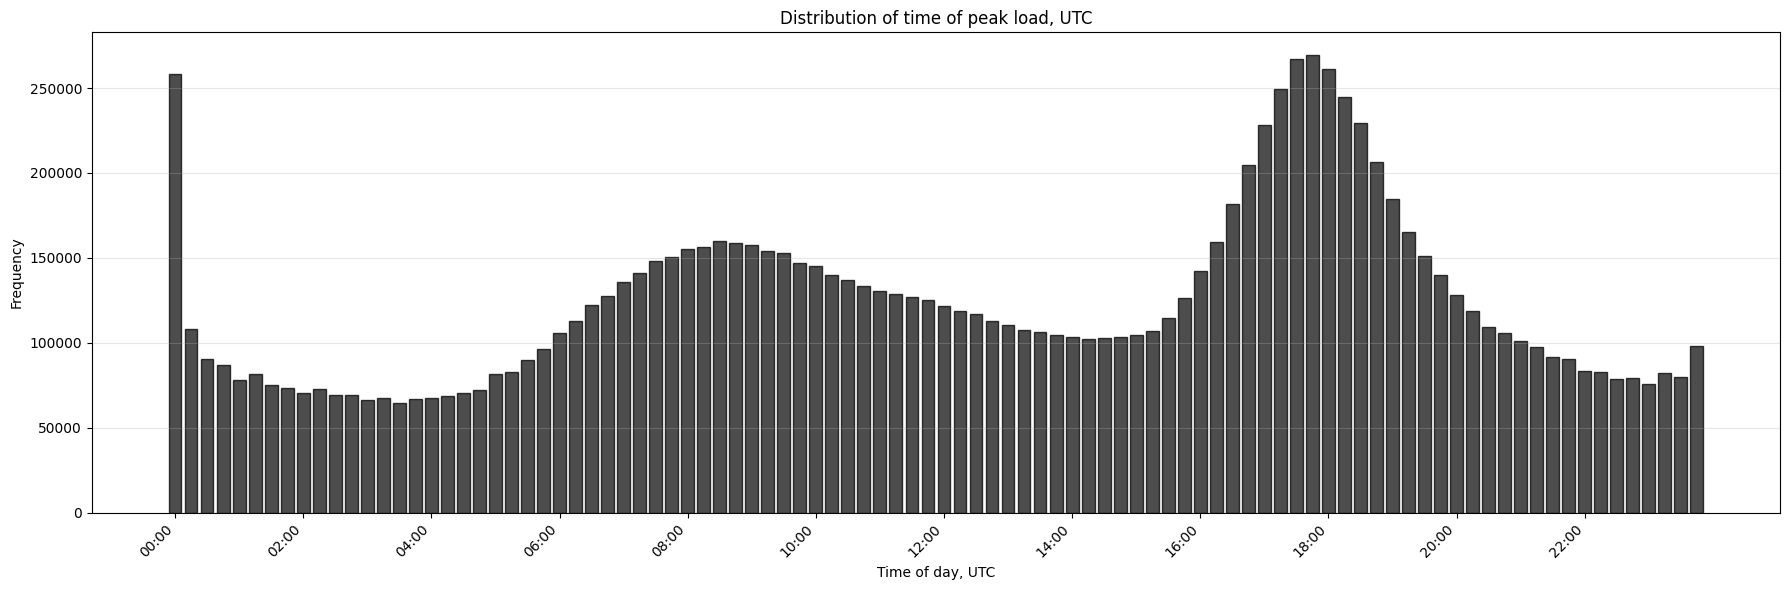

In [ ]:
# ============================================================
# Ordered histogram of time of peak
# ============================================================

from visualization.plot_styling import PlotStyle
plot_style = PlotStyle()

if "time_of_peak_utc" not in all_daily_stats_df.columns:
    raise ValueError("Expected a 'time_of_peak_utc' column in all_daily_stats_df.")

peak_time_labels = (
    all_daily_stats_df["time_of_peak_utc"]
    .astype("string")
    .str.slice(0, 5)
    .dropna()
)

peak_time_labels = peak_time_labels[
    peak_time_labels.str.match(r"^\d{2}:\d{2}$", na=False)
]

peak_counts = peak_time_labels.value_counts().sort_index()

if peak_counts.empty:
    print("No valid time_of_peak_utc values to plot.")
else:
    plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
    plt.bar(
        peak_counts.index,
        peak_counts.values,
        edgecolor="black",
        alpha=0.75,
        color=plot_style.get_color_original(),
    )
    plt.title("Distribution of time of peak load, UTC")
    plt.xlabel("Time of day, UTC")
    plt.ylabel("Frequency")

    tick_step = max(1, len(peak_counts) // 12)
    plt.xticks(peak_counts.index[::tick_step], rotation=45, ha="right")

    plt.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

In [6]:
# ============================================================
# Seasonality analysis from daily-profile artifact
# ============================================================

# Uses:
#   all_daily_stats_df
#
# Expected columns:
#   meter_id
#   date_utc
#   daily_total_wh
#   daily_total_kwh
#   daily_mean_kw
#   data_mode, optional


if "all_daily_stats_df" not in globals():
    raise RuntimeError(
        "all_daily_stats_df is not available. "
        "Run the daily-profile loading cell first."
    )

required_cols = ["date_utc", "daily_total_wh"]
missing_cols = [c for c in required_cols if c not in all_daily_stats_df.columns]
if missing_cols:
    raise ValueError(f"all_daily_stats_df is missing required columns: {missing_cols}")

meter_ids_to_run_daily = globals().get("meter_ids_to_run_daily", None)


class SeasonalityAnalyzer:
    def __init__(self, daily_df: pd.DataFrame):
        self.daily_df = daily_df.copy()

    @staticmethod
    def _stats_from_series(series: pd.Series):
        values = pd.to_numeric(series, errors="coerce").dropna()

        if values.empty:
            return {
                "mean_kwh_per_day": np.nan,
                "median_kwh_per_day": np.nan,
                "std_kwh_per_day": np.nan,
                "count_meter_days": 0,
            }

        return {
            "mean_kwh_per_day": float(values.mean()),
            "median_kwh_per_day": float(values.median()),
            "std_kwh_per_day": float(values.std(ddof=1)) if len(values) > 1 else 0.0,
            "count_meter_days": int(len(values)),
        }

    def _prepare_daily_frame(self, meter_ids=None) -> pd.DataFrame:
        df = self.daily_df.copy()

        df["date_utc"] = pd.to_datetime(df["date_utc"], utc=True, errors="coerce")
        df["daily_total_wh"] = pd.to_numeric(df["daily_total_wh"], errors="coerce")
        df["daily_total_kwh"] = df["daily_total_wh"] / 1000.0

        df = df.dropna(subset=["date_utc", "daily_total_kwh"])
        df = df[df["daily_total_kwh"] > 0]

        # Same high-end filter as the descriptive statistics.
        df = df[df["daily_total_kwh"] <= 200.0]

        if meter_ids is not None and "meter_id" in df.columns:
            target_meters = {int(m) for m in meter_ids}
            df["meter_id"] = pd.to_numeric(df["meter_id"], errors="coerce")
            df = df.dropna(subset=["meter_id"])
            df["meter_id"] = df["meter_id"].astype(int)
            df = df[df["meter_id"].isin(target_meters)]

        df["month"] = df["date_utc"].dt.month
        df["weekday"] = df["date_utc"].dt.dayofweek
        df["is_weekend"] = df["weekday"] >= 5

        return df

    def compute_stats(self, meter_ids=None):
        df = self._prepare_daily_frame(meter_ids=meter_ids)

        if df.empty:
            empty_month = pd.DataFrame(
                columns=[
                    "month",
                    "month_name",
                    "mean_kwh_per_day",
                    "median_kwh_per_day",
                    "std_kwh_per_day",
                    "count_meter_days",
                ]
            )
            empty_wdwe = pd.DataFrame(
                columns=[
                    "day_type",
                    "mean_kwh_per_day",
                    "median_kwh_per_day",
                    "std_kwh_per_day",
                    "count_meter_days",
                ]
            )
            empty_weekday = pd.DataFrame(
                columns=[
                    "weekday",
                    "weekday_name",
                    "mean_kwh_per_day",
                    "median_kwh_per_day",
                    "std_kwh_per_day",
                    "count_meter_days",
                ]
            )
            return empty_month, empty_wdwe, empty_weekday

        month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

        month_rows = []
        for month in range(1, 13):
            vals = df.loc[df["month"] == month, "daily_total_kwh"]
            stats = self._stats_from_series(vals)
            month_rows.append(
                {
                    "month": month,
                    "month_name": month_names[month - 1],
                    **stats,
                }
            )

        month_stats = pd.DataFrame(month_rows)

        wdwe_rows = []
        for is_weekend, day_type in [(False, "Weekday"), (True, "Weekend")]:
            vals = df.loc[df["is_weekend"] == is_weekend, "daily_total_kwh"]
            stats = self._stats_from_series(vals)
            wdwe_rows.append(
                {
                    "day_type": day_type,
                    **stats,
                }
            )

        wd_we_stats = pd.DataFrame(wdwe_rows)

        weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

        weekday_rows = []
        for weekday in range(7):
            vals = df.loc[df["weekday"] == weekday, "daily_total_kwh"]
            stats = self._stats_from_series(vals)
            weekday_rows.append(
                {
                    "weekday": weekday,
                    "weekday_name": weekday_names[weekday],
                    **stats,
                }
            )

        weekday_stats = pd.DataFrame(weekday_rows)

        return (
            month_stats.round(4),
            wd_we_stats.round(4),
            weekday_stats.round(4),
        )


seasonality_analyzer = SeasonalityAnalyzer(all_daily_stats_df)

month_stats, wd_we_stats, weekday_stats = seasonality_analyzer.compute_stats(
    meter_ids=meter_ids_to_run_daily,
)

print("Seasonality analysis completed.")
print("\nMonthly stats:")
display(month_stats)

print("\nWeekday vs weekend stats:")
display(wd_we_stats)

print("\nWeekday stats:")
display(weekday_stats)

Seasonality analysis completed.

Monthly stats:


,month,month_name,mean_kwh_per_day,median_kwh_per_day,std_kwh_per_day,count_meter_days
0,1,Jan,22.8047,13.3752,25.5684,1771393
1,2,Feb,18.7900,11.0395,21.6589,1647706
2,3,Mar,17.4308,10.5290,20.1013,1795575
3,4,Apr,14.2803,8.5526,17.5573,1746724
4,5,May,10.7597,6.7642,14.2122,891674
5,6,Jun,NaN,NaN,NaN,0
6,7,Jul,NaN,NaN,NaN,0
7,8,Aug,NaN,NaN,NaN,0
8,9,Sep,7.9727,4.7905,11.7148,356986
9,10,Oct,12.8241,7.6198,16.6888,756656



Weekday vs weekend stats:


,day_type,mean_kwh_per_day,median_kwh_per_day,std_kwh_per_day,count_meter_days
0,Weekday,17.2011,9.6628,21.0622,8546736
1,Weekend,18.0967,10.7690,21.3287,3367784



Weekday stats:


,weekday,weekday_name,mean_kwh_per_day,median_kwh_per_day,std_kwh_per_day,count_meter_days
0,0,Mon,16.8085,9.4885,20.6882,1705279
1,1,Tue,16.8232,9.3352,20.8369,1734934
2,2,Wed,17.1115,9.4505,21.1530,1739049
3,3,Thu,17.3364,9.7758,21.1108,1676676
4,4,Fri,17.9429,10.3240,21.4985,1690798
5,5,Sat,18.2012,10.8173,21.4500,1691254
6,6,Sun,17.9913,10.7235,21.2051,1676530


### Daily profile stats per meter

Computes daily profile metrics from aggregated 15-minute load (Wh per interval):
- per-day total energy (reported in kWh)
- peak load and time-of-peak (Wh per 15-min interval)
- load factor (mean / peak)

In [7]:
class DailyProfileAnalyzer:
    def __init__(self, plotter: SmartMeterDayPlotter, freq: str = '15min'):
        self.plotter = plotter
        self.freq = freq

    def compute_daily_profile_stats(self, meter_id: int):
        df = self.plotter._load_meter_dataframe(meter_id)
        df = df.sort_index()

        # Use aggregated profile in Wh per interval
        p_agg = df['Aggregated'].copy() # W
        e_agg = p_agg * (15/60) # Wh (e=p*t, t=15min=0.25h)
        day_key = e_agg.index.floor('D') 

        # Daily total energy and peak load
        daily_total_wh = e_agg.groupby(day_key).sum() # Wh
        daily_peak_w = p_agg.groupby(day_key).max() # W 

        # Time of peak within each day (UTC)
        peak_timestamp = p_agg.groupby(day_key).idxmax()
        peak_time_utc = peak_timestamp.dt.strftime('%H:%M')

        daily_stats = pd.DataFrame({
            'meter_id': int(meter_id),
            'date_utc': daily_total_wh.index,
            'daily_total_wh': daily_total_wh.values,
            'peak_load_w_15min': daily_peak_w.values,
            'time_of_peak_utc': peak_time_utc.values,
        })

        return daily_stats.sort_values('date_utc').reset_index(drop=True)

    def report_all_meters(self, meter_ids=None, progress_every=25):
        available = self.plotter.available_meters()
        if meter_ids is None:
            meters = available
        else:
            meter_ids = [int(m) for m in meter_ids]
            meters = [m for m in meter_ids if m in set(available)]

        all_daily = []
        iterator = tqdm(
            meters,
            desc='Daily profile analysis',
            unit='meter',
            miniters=max(1, int(progress_every)),
        )
        for meter_id in iterator:
            meter_daily = self.compute_daily_profile_stats(meter_id=meter_id)
            all_daily.append(meter_daily)

        if len(all_daily) == 0:
            return pd.DataFrame(), pd.DataFrame()

        all_daily_df = pd.concat(all_daily, ignore_index=True)

        return all_daily_df

##### 3-phase

In [ ]:
# Daily profile stats
plotter = make_plotter(verbose=False)
daily_profile_analyzer = DailyProfileAnalyzer(plotter=plotter, freq=analysis_freq)

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run_daily = None

all_daily_stats_df = daily_profile_analyzer.report_all_meters(
    meter_ids=meter_ids_to_run_daily,
    progress_every=25,
)

daily_all_path = save_df(all_daily_stats_df, "daily_profile_all_meter_days.csv")

print("Daily profile analysis completed.")
print(f"Saved all meter-day rows: {daily_all_path}")

print("\nPreview: meter-day rows")
display(all_daily_stats_df.head(20))

Daily profile analysis: 100%|██████████| 61557/61557 [55:57<00:00, 18.33meter/s] 


Daily profile analysis completed.
Saved all meter-day rows: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/daily_profile_all_meter_days.csv

Preview: meter-day rows


,meter_id,date_utc,daily_total_wh,peak_load_w_15min,time_of_peak_utc
0,17,2023-09-04 00:00:00+00:00,0.0,0.0,08:45
1,17,2023-09-05 00:00:00+00:00,0.0,0.0,00:00
2,17,2023-09-06 00:00:00+00:00,0.0,0.0,00:00
3,17,2023-09-07 00:00:00+00:00,0.0,0.0,00:00
4,17,2023-09-08 00:00:00+00:00,0.0,0.0,00:00
5,17,2023-09-09 00:00:00+00:00,0.0,0.0,00:00
6,17,2023-09-10 00:00:00+00:00,0.0,0.0,00:00
7,17,2023-09-11 00:00:00+00:00,0.0,0.0,00:00
8,17,2023-09-12 00:00:00+00:00,0.0,0.0,00:00
9,17,2023-09-13 00:00:00+00:00,0.0,0.0,00:00


In [9]:
# Load daily profile artifacts 

loaded_daily_all_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/daily_profile_all_meter_days_3phase.csv"
all_daily_stats_df = pd.read_csv(loaded_daily_all_path)

print(f"Loaded all meter-day rows file: {loaded_daily_all_path}")
print(f"all_daily_stats_df rows: {len(all_daily_stats_df)}")

print("\nMeter-day rows preview:")
display(all_daily_stats_df)

Loaded all meter-day rows file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/daily_profile_all_meter_days_3phase.csv
all_daily_stats_df rows: 16497276

Meter-day rows preview:


,meter_id,date_utc,daily_total_wh,peak_load_w_15min,time_of_peak_utc
0,17,2023-09-04 00:00:00+00:00,0.0,0.0,08:45
1,17,2023-09-05 00:00:00+00:00,0.0,0.0,00:00
2,17,2023-09-06 00:00:00+00:00,0.0,0.0,00:00
3,17,2023-09-07 00:00:00+00:00,0.0,0.0,00:00
4,17,2023-09-08 00:00:00+00:00,0.0,0.0,00:00
...,...,...,...,...,...
16497271,999970,2024-05-24 00:00:00+00:00,0.0,0.0,00:00
16497272,999970,2024-05-25 00:00:00+00:00,0.0,0.0,00:00
16497273,999970,2024-05-26 00:00:00+00:00,0.0,0.0,00:00
16497274,999970,2024-05-27 00:00:00+00:00,0.0,0.0,00:00


In [10]:
# Basic descriptive stats for daily smart-meter consumption

# 1) Remove zero/invalid days, 2) remove outliers above 200 kWh/day before stats

daily_wh = pd.to_numeric(all_daily_stats_df.get('daily_total_wh'), errors='coerce')
daily_kwh = daily_wh / 1000.0

daily_kwh_nonzero = daily_kwh[daily_kwh > 0].dropna()

if daily_kwh_nonzero.empty:
    print("No positive daily consumption values found.")
else:
    # Fixed high-end threshold
    high_cutoff_kwh = 200.0
    daily_kwh_trimmed = daily_kwh_nonzero[daily_kwh_nonzero <= high_cutoff_kwh]
    daily_kwh_excluded_high = daily_kwh_nonzero[daily_kwh_nonzero > high_cutoff_kwh]

    if daily_kwh_trimmed.empty:
        print("No values left after removing daily consumption above 200 kWh/day.")
    else:
        # Core distribution stats across filtered meter-days
        stats_payload = {
            "original_positive_meter_days": int(daily_kwh_nonzero.shape[0]),
            "trimmed_meter_days": int(daily_kwh_trimmed.shape[0]),
            "removed_above_200kwh_meter_days": int(daily_kwh_nonzero.shape[0] - daily_kwh_trimmed.shape[0]),
            "high_cutoff_kwh": high_cutoff_kwh,
            "mean_kwh_per_meter_day": float(daily_kwh_trimmed.mean()),
            "median_kwh_per_meter_day": float(daily_kwh_trimmed.median()),
            "std_kwh_per_meter_day": float(daily_kwh_trimmed.std()),
            "min_kwh_per_meter_day": float(daily_kwh_trimmed.min()),
            "p25_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.25)),
            "p75_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.75)),
            "p95_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.95)),
            "max_kwh_per_meter_day": float(daily_kwh_trimmed.max()),
        }

        # Keep only rows surviving the filtering for any row-level/per-meter stats
        valid_idx = daily_kwh_trimmed.index
        filtered_df = all_daily_stats_df.loc[valid_idx].copy()
        filtered_df['_daily_kwh'] = daily_kwh_trimmed

        # Per-meter average daily consumption on filtered data
        if 'meter_id' in filtered_df.columns:
            per_meter_mean = (
                filtered_df
                .groupby('meter_id', as_index=False)['_daily_kwh']
                .mean()
                .rename(columns={'_daily_kwh': 'avg_daily_kwh'})
                .sort_values('avg_daily_kwh', ascending=False)
                .reset_index(drop=True)
            )

            highest_avg_meter = per_meter_mean.iloc[0]
            lowest_avg_meter = per_meter_mean.iloc[-1]

            stats_payload["highest_avg_meter_id"] = int(highest_avg_meter['meter_id'])
            stats_payload["highest_avg_meter_avg_kwh"] = float(highest_avg_meter['avg_daily_kwh'])
            stats_payload["lowest_avg_meter_id"] = int(lowest_avg_meter['meter_id'])
            stats_payload["lowest_avg_meter_avg_kwh"] = float(lowest_avg_meter['avg_daily_kwh'])
        else:
            per_meter_mean = pd.DataFrame()

        # Row with highest daily consumption after filtering
        max_idx = daily_kwh_trimmed.idxmax()
        max_row = all_daily_stats_df.loc[max_idx]
        peak_row_info = {
            'max_daily_kwh_after_filtering': float(daily_kwh_trimmed.max())
        }
        if 'meter_id' in all_daily_stats_df.columns:
            peak_row_info['meter_id'] = int(max_row['meter_id'])
        for date_col in ['date', 'day', 'day_utc', 'day_local', 'timestamp_utc']:
            if date_col in all_daily_stats_df.columns:
                peak_row_info[date_col] = str(max_row[date_col])
                break

        print("Daily consumption summary (zeros removed + outliers above 200 kWh/day removed):")
        display(pd.DataFrame([stats_payload]).round(3))

        if not daily_kwh_excluded_high.empty:
            print(
                f"Excluded >200 kWh/day group: n={len(daily_kwh_excluded_high)}, "
                f"mean={daily_kwh_excluded_high.mean():.3f} kWh/day, "
                f"min={daily_kwh_excluded_high.min():.3f}, max={daily_kwh_excluded_high.max():.3f}"
            )
        else:
            print("Excluded >200 kWh/day group: n=0")

        print("\nHighest daily consumption AFTER filtering:")
        display(pd.DataFrame([peak_row_info]))

        if not per_meter_mean.empty:
            print("\nTop 10 smart meters by average daily consumption (after filtering):")
            display(per_meter_mean.head(10).round(3))

Daily consumption summary (zeros removed + outliers above 200 kWh/day removed):


,original_positive_meter_days,trimmed_meter_days,removed_above_200kwh_meter_days,high_cutoff_kwh,mean_kwh_per_meter_day,median_kwh_per_meter_day,std_kwh_per_meter_day,min_kwh_per_meter_day,p25_kwh_per_meter_day,p75_kwh_per_meter_day,p95_kwh_per_meter_day,max_kwh_per_meter_day,highest_avg_meter_id,highest_avg_meter_avg_kwh,lowest_avg_meter_id,lowest_avg_meter_avg_kwh
0,12312218,12242101,70117,200.0,17.392,9.818,21.465,0.0,4.338,22.242,58.824,200.0,237523,185.822,617317,0.0


Excluded >200 kWh/day group: n=70117, mean=639.109 kWh/day, min=200.001, max=8906.240

Highest daily consumption AFTER filtering:


,max_daily_kwh_after_filtering,meter_id
0,200.0,13454



Top 10 smart meters by average daily consumption (after filtering):


,meter_id,avg_daily_kwh
0,237523,185.822
1,390018,181.688
2,790108,180.196
3,204127,179.266
4,201281,177.977
5,843699,177.601
6,208171,177.471
7,490239,177.226
8,447993,176.618
9,851115,175.011


/var/folders/04/6kgcrr756y5_8bzn5gnryl_m0000gn/T/ipykernel_9068/721771598.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  peak_times = pd.to_datetime(all_daily_stats_df['time_of_peak_utc'], errors='coerce', utc=True).dropna()


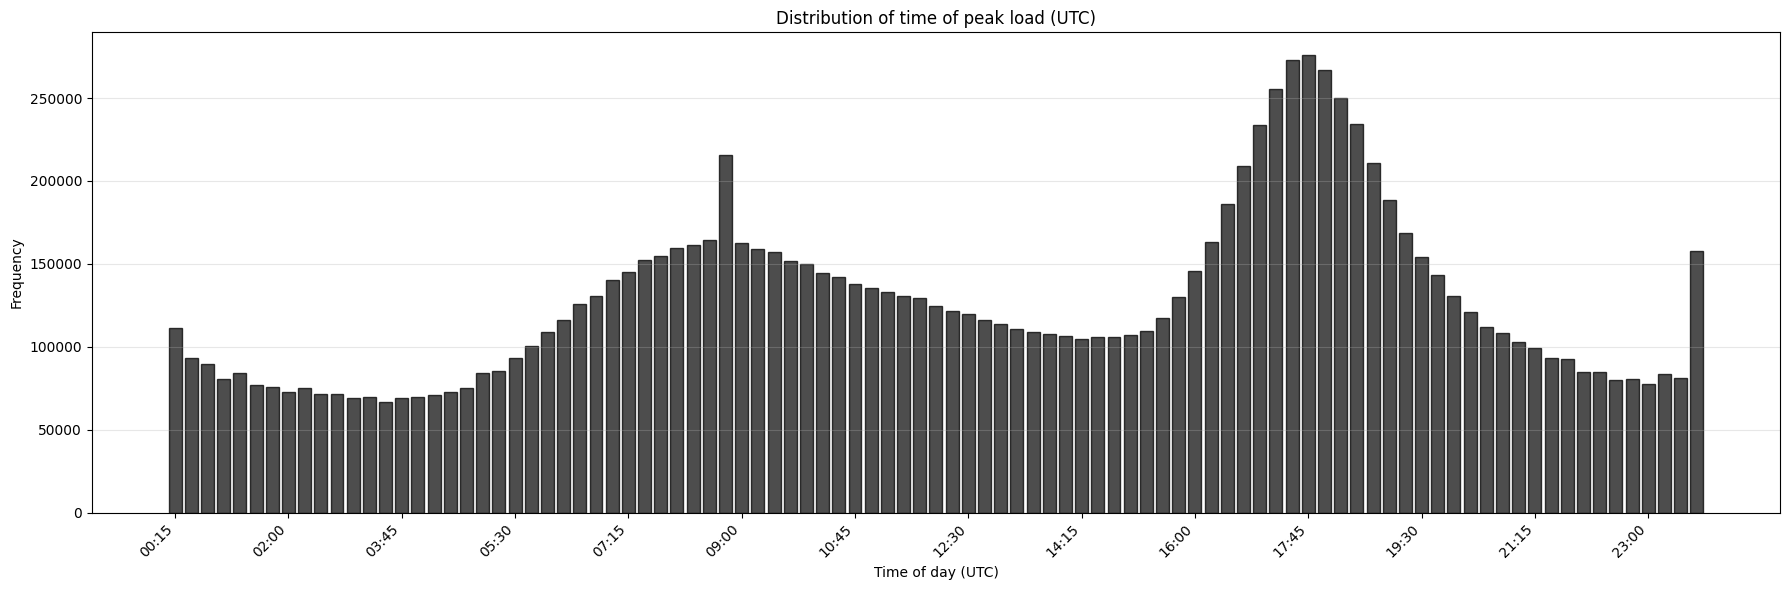

In [11]:
# ordered histogram of when time_of_peak_utc occurs across all meters and days (excluding 00:00)
peak_times = pd.to_datetime(all_daily_stats_df['time_of_peak_utc'], errors='coerce', utc=True).dropna()
peak_time_labels = peak_times.dt.strftime('%H:%M')
peak_time_labels = peak_time_labels[peak_time_labels != '00:00']
peak_counts = peak_time_labels.value_counts().sort_index()

plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
plt.bar(peak_counts.index, peak_counts.values, edgecolor='black', alpha=0.75, color=plot_style.get_color_original())
plt.title('Distribution of time of peak load (UTC)')
plt.xlabel('Time of day (UTC)')
plt.ylabel('Frequency')
tick_step = max(1, len(peak_counts) // 12)
plt.xticks(peak_counts.index[::tick_step], rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [12]:
# average of column 'avg_daily_total_kwh' in daily_summary_df
print(f'The highest daily consumption of all SMs: {round(all_daily_stats_df['daily_total_wh'].max()/1000)} kWh')
print(f'The lowest daily consumption of all SMs: {all_daily_stats_df['daily_total_wh'].min()/1000} kWh')
print(f'The mean daily consumption of all SMs: {round(all_daily_stats_df['daily_total_wh'].mean()/1000)} kWh')
print(f'The median daily consumption of all SMs: {round(all_daily_stats_df['daily_total_wh'].median()/1000)} kWh')
print(f'The 25th percentile of daily consumption of all SMs: {round(all_daily_stats_df['daily_total_wh'].quantile(0.25)/1000)} kWh')
print(f'The 75th percentile of daily consumption of all SMs: {round(all_daily_stats_df['daily_total_wh'].quantile(0.75)/1000)} kWh')

The highest daily consumption of all SMs: 8906 kWh
The lowest daily consumption of all SMs: 0.0 kWh
The mean daily consumption of all SMs: 16 kWh
The median daily consumption of all SMs: 6 kWh
The 25th percentile of daily consumption of all SMs: 0 kWh
The 75th percentile of daily consumption of all SMs: 17 kWh


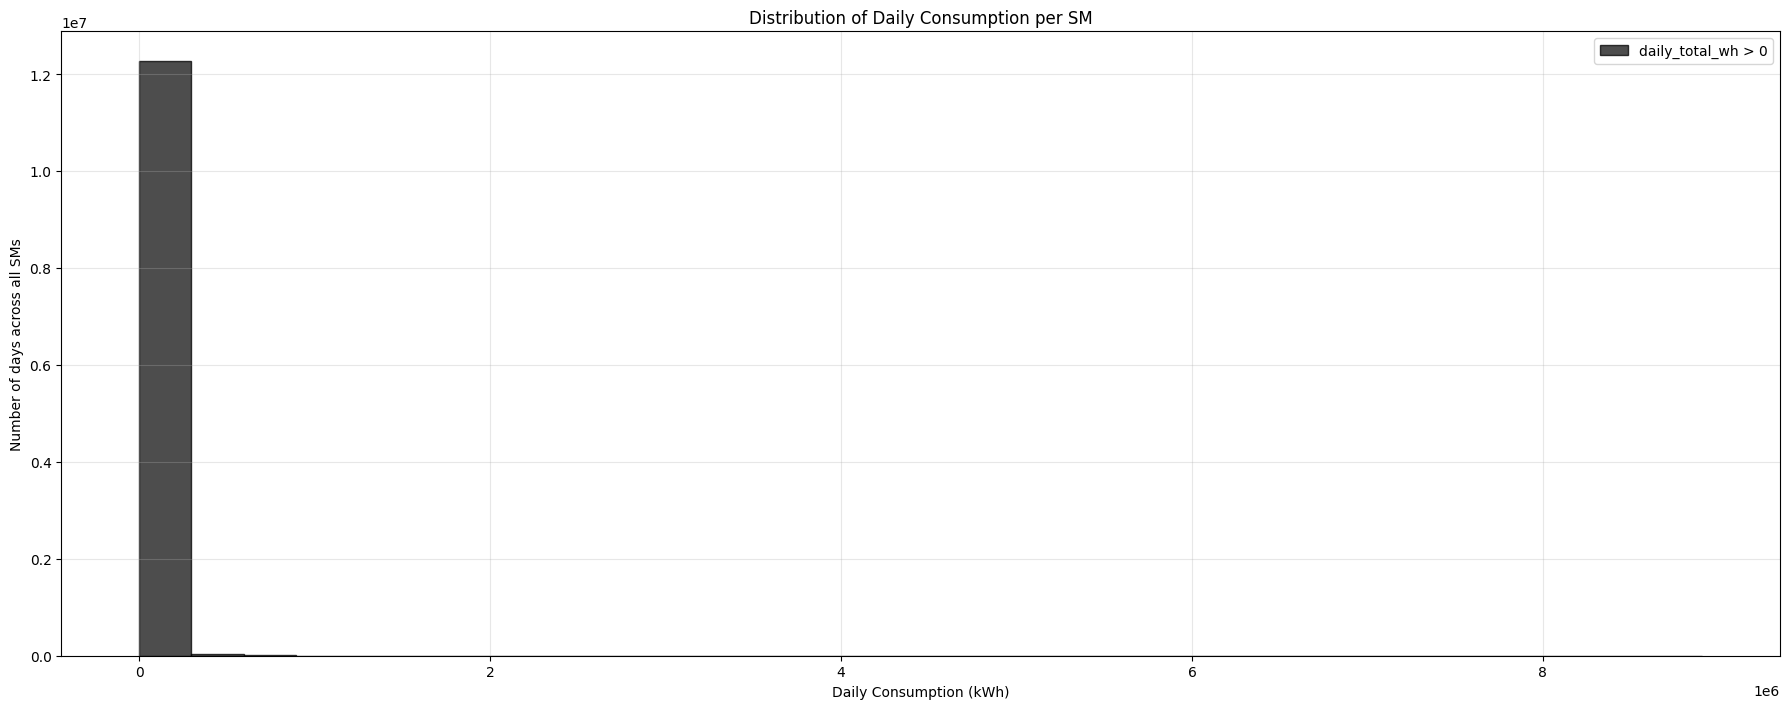

In [158]:
# plot the distribution of 'daily_total_wh' in daily_summary_df 
daily_kwh = all_daily_stats_df.loc[all_daily_stats_df['daily_total_wh'] > 0, 'daily_total_wh']

plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.2))
plt.hist(daily_kwh, bins=30, edgecolor='black', alpha=0.75, color=plot_style.get_color_original(), label='daily_total_wh > 0')
plt.title('Distribution of Daily Consumption per SM')
plt.xlabel('Daily Consumption (kWh)')
plt.ylabel('Number of days across all SMs')
plt.grid(True, alpha=0.3)
plt.tight_layout()
dist_plot_path = os.path.join(output_dir_data_analysis, f"daily_profile_avg_daily_consumption_distribution.png")
plt.legend()

##### 1-phase

In [8]:
# Daily profile stats

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run_daily = None
preferred_hourly_energy_col = globals().get("hourly_energy_col", "hourly_energy_consumption")

def _compute_daily_profile_from_hourly_df(df_raw: pd.DataFrame, source_name: str) -> pd.DataFrame:
    df = df_raw.copy()

    # Parquet hourly files can store meter and timestamp in a MultiIndex.
    if isinstance(df.index, pd.MultiIndex):
        if any(name in ["meter_number", "meter_id", "timestamp", "timestamp_dst", "timestamp_utc"] for name in df.index.names):
            df = df.reset_index()
    elif df.index.name in ["meter_number", "meter_id", "timestamp", "timestamp_dst", "timestamp_utc"]:
        df = df.reset_index()

    meter_col = next((c for c in ["meter_number", "meter_id", "smart_meter_id", "sm_id"] if c in df.columns), None)
    if meter_col is None:
        raise ValueError(f"No meter id column found in {source_name}. Expected one of: meter_number, meter_id, smart_meter_id, sm_id")

    time_col = next((c for c in ["timestamp_utc", "timestamp_dst", "timestamp", "datetime", "time"] if c in df.columns), None)
    if time_col is None:
        raise ValueError(f"No timestamp column found in {source_name}. Expected one of: timestamp_utc, timestamp_dst, timestamp, datetime, time")

    energy_col = preferred_hourly_energy_col if preferred_hourly_energy_col in df.columns else None
    if energy_col is None and "hourly_energy_consumption" in df.columns:
        energy_col = "hourly_energy_consumption"
    if energy_col is None:
        raise ValueError(f"No hourly energy column found in {source_name}. Expected: {preferred_hourly_energy_col}")

    work = pd.DataFrame({
        "meter_id": pd.to_numeric(df[meter_col], errors="coerce"),
        "timestamp": pd.to_datetime(df[time_col], utc=True, errors="coerce"),
        "energy_kwh": pd.to_numeric(df[energy_col], errors="coerce"),
    }).dropna(subset=["meter_id", "timestamp", "energy_kwh"])
    work["meter_id"] = work["meter_id"].astype(int)

    if meter_ids_to_run_daily is not None:
        target = set(int(m) for m in meter_ids_to_run_daily)
        work = work[work["meter_id"].isin(target)]

    if work.empty:
        return pd.DataFrame(columns=[
            "meter_id", "date_utc", "daily_total_wh", "peak_load_w_15min", "time_of_peak_utc"
        ])

    work = work.sort_values(["meter_id", "timestamp"]).reset_index(drop=True)
    work["date_utc"] = work["timestamp"].dt.floor("D")
    work["energy_wh"] = work["energy_kwh"] * 1000.0

    daily_total = (
        work.groupby(["meter_id", "date_utc"], as_index=False)["energy_wh"]
        .sum()
        .rename(columns={"energy_wh": "daily_total_wh"})
    )

    # Keep legacy output field name for compatibility with downstream cells.
    peak_idx = work.groupby(["meter_id", "date_utc"])["energy_wh"].idxmax()
    peak = work.loc[peak_idx, ["meter_id", "date_utc", "energy_wh", "timestamp"]].copy()
    peak = peak.rename(columns={"energy_wh": "peak_load_w_15min"})
    peak["time_of_peak_utc"] = peak["timestamp"].dt.strftime("%H:%M")
    peak = peak[["meter_id", "date_utc", "peak_load_w_15min", "time_of_peak_utc"]]

    out = daily_total.merge(peak, on=["meter_id", "date_utc"], how="left")
    return out.sort_values(["meter_id", "date_utc"]).reset_index(drop=True)

if analysis_data_mode == "hourly_csv" and os.path.isdir(hourly_csv_path):
    # Reuse discovered files from the load-data cell when available.
    if "hourly_data_files" in globals() and len(hourly_data_files) > 0:
        input_files = hourly_data_files
    else:
        hourly_parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "hourly_measurements_*.parquet")))
        if not hourly_parquet_files:
            hourly_parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "*.parquet")))
        if hourly_parquet_files:
            input_files = hourly_parquet_files
        else:
            hourly_csv_files = sorted(glob.glob(os.path.join(hourly_csv_path, "hourly_measurements_*.csv")))
            if not hourly_csv_files:
                hourly_csv_files = sorted(glob.glob(os.path.join(hourly_csv_path, "*.csv")))
            if not hourly_csv_files:
                raise FileNotFoundError(f"No parquet or CSV files found in directory: {hourly_csv_path}")
            input_files = hourly_csv_files

    print(f"Processing daily profile across all files in: {hourly_csv_path}")
    print(f"Found {len(input_files)} files")

    all_parts = []
    for i, file_path in enumerate(input_files, start=1):
        ext = os.path.splitext(file_path)[1].lower()
        print(f"\n[{i}/{len(input_files)}] Reading: {os.path.basename(file_path)}")

        if ext == ".parquet":
            df_file = pd.read_parquet(file_path)
        elif ext == ".csv":
            df_file = pd.read_csv(file_path)
        else:
            raise ValueError(f"Unsupported file type in hourly directory: {file_path}")

        part_df = _compute_daily_profile_from_hourly_df(df_file, source_name=os.path.basename(file_path))
        all_parts.append(part_df)
        print(f"Rows from file: {len(part_df):,}")

        del df_file, part_df
        gc.collect()

    if len(all_parts) == 0:
        all_daily_stats_df = pd.DataFrame(columns=["meter_id", "date_utc", "daily_total_wh", "peak_load_w_15min", "time_of_peak_utc"])
    else:
        all_daily_stats_df = pd.concat(all_parts, ignore_index=True)
        all_daily_stats_df = all_daily_stats_df.sort_values(["meter_id", "date_utc"]).reset_index(drop=True)

    daily_all_path = save_df(all_daily_stats_df, "daily_profile_all_meter_days.csv")

    print("\nDaily profile analysis completed across all hourly files.")
    print(f"Saved combined meter-day rows: {daily_all_path}")
    print(f"Total rows saved: {len(all_daily_stats_df):,}")
    print("\nPreview: combined meter-day rows")
    display(all_daily_stats_df.head(20))

else:
    # Fallback for phased mode or when hourly_csv_path points to one file.
    plotter = make_plotter(verbose=False)
    daily_profile_analyzer = DailyProfileAnalyzer(plotter=plotter, freq=analysis_freq)

    all_daily_stats_df = daily_profile_analyzer.report_all_meters(
        meter_ids=meter_ids_to_run_daily,
    )
    daily_all_path = save_df(all_daily_stats_df, "daily_profile_all_meter_days.csv")
    print("Daily profile analysis completed.")
    print(f"Saved all meter-day rows: {daily_all_path}")
    print("\nPreview: meter-day rows")
    display(all_daily_stats_df.head(20))

Processing daily profile across all files in: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/parq_hourly
Found 12 files

[1/12] Reading: hourly_measurements_2023_10.parquet
Rows from file: 663,179

[2/12] Reading: hourly_measurements_2023_11.parquet
Rows from file: 1,859,233

[3/12] Reading: hourly_measurements_2023_12.parquet
Rows from file: 1,922,117

[4/12] Reading: hourly_measurements_2023_9.parquet
Rows from file: 1,857,900

[5/12] Reading: hourly_measurements_2024_1.parquet
Rows from file: 1,923,465

[6/12] Reading: hourly_measurements_2024_2.parquet
Rows from file: 1,801,190

[7/12] Reading: hourly_measurements_2024_3.parquet
Rows from file: 1,926,303

[8/12] Reading: hourly_measurements_2024_4.parquet
Rows from file: 1,864,766

[9/12] Reading: hourly_measurements_2024_5.parquet
Rows from file: 1,927,915

[10/12] Reading: hourly_measurements_2024_6.parquet
Rows from file: 1,866,200

[11/12] Reading: hourly_measurements_2024_7.parquet
Rows from file: 1

,meter_id,date_utc,daily_total_wh,peak_load_w_15min,time_of_peak_utc
0,17,2023-09-01 00:00:00+00:00,8180.0,1680.0,17:00
1,17,2023-09-02 00:00:00+00:00,8760.0,2240.0,17:00
2,17,2023-09-03 00:00:00+00:00,8290.0,3250.0,18:00
3,17,2023-09-04 00:00:00+00:00,10270.0,2760.0,17:00
4,17,2023-09-05 00:00:00+00:00,6210.0,1820.0,16:00
5,17,2023-09-06 00:00:00+00:00,4930.0,1450.0,06:00
6,17,2023-09-07 00:00:00+00:00,7600.0,2180.0,18:00
7,17,2023-09-08 00:00:00+00:00,7050.0,1640.0,17:00
8,17,2023-09-09 00:00:00+00:00,13990.0,3860.0,18:00
9,17,2023-09-10 00:00:00+00:00,10560.0,1870.0,12:00


In [13]:
# Load daily profile artifacts

loaded_daily_all_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/daily_profile_all_meter_days_1phase.csv"
all_daily_stats_df = pd.read_csv(loaded_daily_all_path)

print(f"Loaded all meter-day rows file: {loaded_daily_all_path}")
print(f"all_daily_stats_df rows: {len(all_daily_stats_df)}")

print("\nMeter-day rows preview:")
display(all_daily_stats_df)

Loaded all meter-day rows file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/daily_profile_all_meter_days_1phase.csv
all_daily_stats_df rows: 21470841

Meter-day rows preview:


,meter_id,date_utc,daily_total_wh,peak_load_w_15min,time_of_peak_utc
0,17,2023-09-01 00:00:00+00:00,8180.0,1680.0,17:00
1,17,2023-09-02 00:00:00+00:00,8760.0,2240.0,17:00
2,17,2023-09-03 00:00:00+00:00,8290.0,3250.0,18:00
3,17,2023-09-04 00:00:00+00:00,10270.0,2760.0,17:00
4,17,2023-09-05 00:00:00+00:00,6210.0,1820.0,16:00
...,...,...,...,...,...
21470836,1999989,2023-10-27 00:00:00+00:00,9090.0,1100.0,15:00
21470837,1999989,2023-10-28 00:00:00+00:00,7790.0,990.0,09:00
21470838,1999989,2023-10-29 00:00:00+00:00,39410.0,11210.0,03:00
21470839,1999989,2023-10-30 00:00:00+00:00,7430.0,900.0,17:00


In [18]:
# Basic descriptive stats for daily smart-meter consumption

# 1) Remove zero/invalid days, 2) remove outliers above 200 kWh/day before stats

daily_wh = pd.to_numeric(all_daily_stats_df.get('daily_total_wh'), errors='coerce')
daily_kwh = daily_wh / 1000.0

daily_kwh_nonzero = daily_kwh[daily_kwh > 0].dropna()

if daily_kwh_nonzero.empty:
    print("No positive daily consumption values found.")
else:
    # Fixed high-end threshold
    high_cutoff_kwh = 200.0
    daily_kwh_trimmed = daily_kwh_nonzero[daily_kwh_nonzero <= high_cutoff_kwh]
    daily_kwh_excluded_high = daily_kwh_nonzero[daily_kwh_nonzero > high_cutoff_kwh]

    if daily_kwh_trimmed.empty:
        print("No values left after removing daily consumption above 200 kWh/day.")
    else:
        # Core distribution stats across filtered meter-days
        stats_payload = {
            "original_positive_meter_days": int(daily_kwh_nonzero.shape[0]),
            "trimmed_meter_days": int(daily_kwh_trimmed.shape[0]),
            "removed_above_200kwh_meter_days": int(daily_kwh_nonzero.shape[0] - daily_kwh_trimmed.shape[0]),
            "high_cutoff_kwh": high_cutoff_kwh,
            "mean_kwh_per_meter_day": float(daily_kwh_trimmed.mean()),
            "median_kwh_per_meter_day": float(daily_kwh_trimmed.median()),
            "std_kwh_per_meter_day": float(daily_kwh_trimmed.std()),
            "min_kwh_per_meter_day": float(daily_kwh_trimmed.min()),
            "p25_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.25)),
            "p75_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.75)),
            "p95_kwh_per_meter_day": float(daily_kwh_trimmed.quantile(0.95)),
            "max_kwh_per_meter_day": float(daily_kwh_trimmed.max()),
        }

        # Keep only rows surviving the filtering for any row-level/per-meter stats
        valid_idx = daily_kwh_trimmed.index
        filtered_df = all_daily_stats_df.loc[valid_idx].copy()
        filtered_df['_daily_kwh'] = daily_kwh_trimmed

        # Per-meter average daily consumption on filtered data
        if 'meter_id' in filtered_df.columns:
            per_meter_mean = (
                filtered_df
                .groupby('meter_id', as_index=False)['_daily_kwh']
                .mean()
                .rename(columns={'_daily_kwh': 'avg_daily_kwh'})
                .sort_values('avg_daily_kwh', ascending=False)
                .reset_index(drop=True)
            )

            highest_avg_meter = per_meter_mean.iloc[0]
            lowest_avg_meter = per_meter_mean.iloc[-1]

            stats_payload["highest_avg_meter_id"] = int(highest_avg_meter['meter_id'])
            stats_payload["highest_avg_meter_avg_kwh"] = float(highest_avg_meter['avg_daily_kwh'])
            stats_payload["lowest_avg_meter_id"] = int(lowest_avg_meter['meter_id'])
            stats_payload["lowest_avg_meter_avg_kwh"] = float(lowest_avg_meter['avg_daily_kwh'])
        else:
            per_meter_mean = pd.DataFrame()

        # Row with highest daily consumption after filtering
        max_idx = daily_kwh_trimmed.idxmax()
        max_row = all_daily_stats_df.loc[max_idx]
        peak_row_info = {
            'max_daily_kwh_after_filtering': float(daily_kwh_trimmed.max())
        }
        if 'meter_id' in all_daily_stats_df.columns:
            peak_row_info['meter_id'] = int(max_row['meter_id'])
        for date_col in ['date', 'day', 'day_utc', 'day_local', 'timestamp_utc']:
            if date_col in all_daily_stats_df.columns:
                peak_row_info[date_col] = str(max_row[date_col])
                break

        print("Daily consumption summary (zeros removed + outliers above 200 kWh/day removed):")
        display(pd.DataFrame([stats_payload]).round(3))

        if not daily_kwh_excluded_high.empty:
            print(
                f"Excluded >200 kWh/day group: n={len(daily_kwh_excluded_high)}, "
                f"mean={daily_kwh_excluded_high.mean():.3f} kWh/day, "
                f"min={daily_kwh_excluded_high.min():.3f}, max={daily_kwh_excluded_high.max():.3f}"
            )
        else:
            print("Excluded >200 kWh/day group: n=0")

        print("\nHighest daily consumption AFTER filtering:")
        display(pd.DataFrame([peak_row_info]))

        if not per_meter_mean.empty:
            print("\nTop 10 smart meters by average daily consumption (after filtering):")
            display(per_meter_mean.head(10).round(3))

Daily consumption summary (zeros removed + outliers above 200 kWh/day removed):


,original_positive_meter_days,trimmed_meter_days,removed_above_200kwh_meter_days,high_cutoff_kwh,mean_kwh_per_meter_day,median_kwh_per_meter_day,std_kwh_per_meter_day,min_kwh_per_meter_day,p25_kwh_per_meter_day,p75_kwh_per_meter_day,p95_kwh_per_meter_day,max_kwh_per_meter_day,highest_avg_meter_id,highest_avg_meter_avg_kwh,lowest_avg_meter_id,lowest_avg_meter_avg_kwh
0,20673201,20555093,118108,200.0,14.463,7.83,19.511,0.001,3.72,16.79,51.3,200.0,225098,199.25,435866,0.01


Excluded >200 kWh/day group: n=118108, mean=1374.836 kWh/day, min=200.010, max=335559.360

Highest daily consumption AFTER filtering:


,max_daily_kwh_after_filtering,meter_id
0,200.0,13454



Top 10 smart meters by average daily consumption (after filtering):


,meter_id,avg_daily_kwh
0,225098,199.250
1,1563211,198.450
2,389547,198.180
3,1903989,197.970
4,59210,197.512
5,545805,197.410
6,340272,196.745
7,385457,195.460
8,1979852,195.230
9,1624274,195.130


/var/folders/04/6kgcrr756y5_8bzn5gnryl_m0000gn/T/ipykernel_9068/721771598.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  peak_times = pd.to_datetime(all_daily_stats_df['time_of_peak_utc'], errors='coerce', utc=True).dropna()


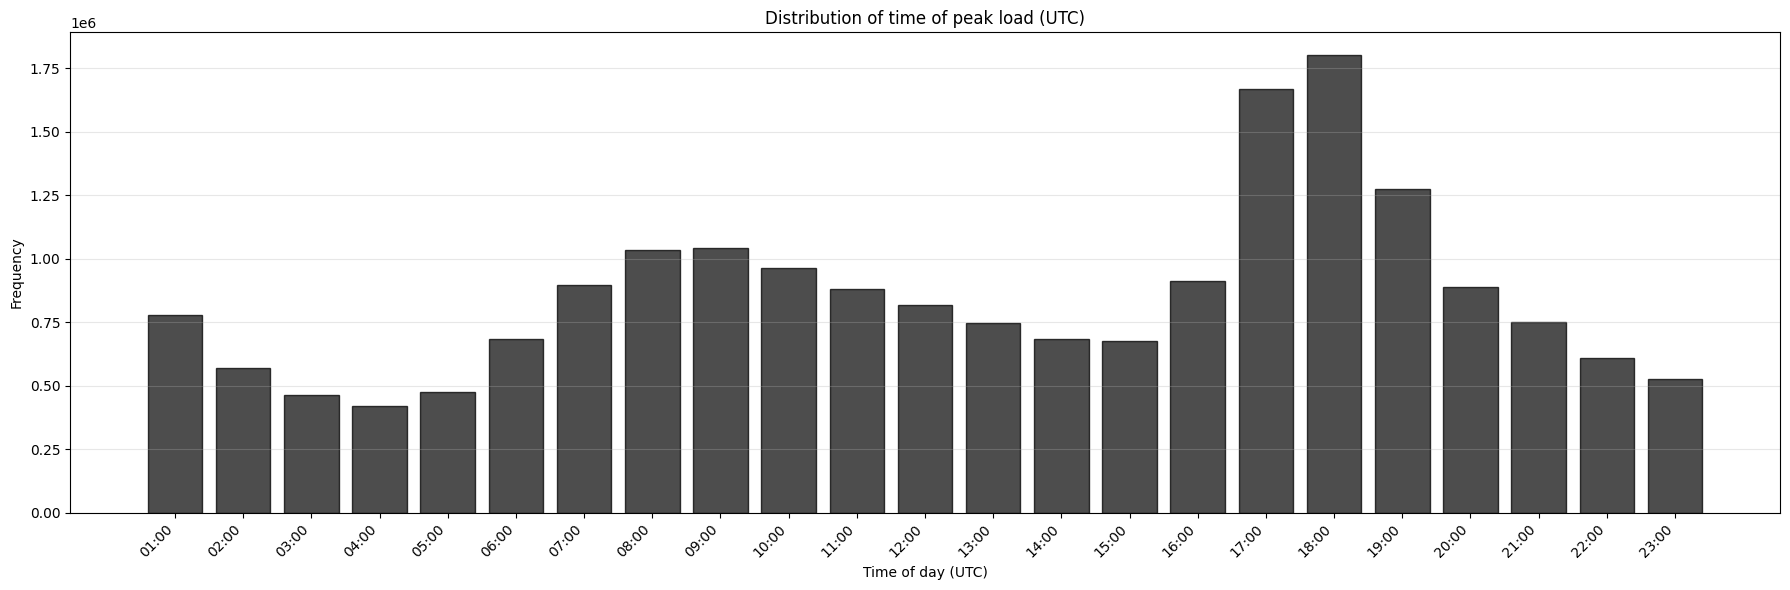

In [19]:
# ordered histogram of when time_of_peak_utc occurs across all meters and days (excluding 00:00)
peak_times = pd.to_datetime(all_daily_stats_df['time_of_peak_utc'], errors='coerce', utc=True).dropna()
peak_time_labels = peak_times.dt.strftime('%H:%M')
peak_time_labels = peak_time_labels[peak_time_labels != '00:00']
peak_counts = peak_time_labels.value_counts().sort_index()

plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
plt.bar(peak_counts.index, peak_counts.values, edgecolor='black', alpha=0.75, color=plot_style.get_color_original())
plt.title('Distribution of time of peak load (UTC)')
plt.xlabel('Time of day (UTC)')
plt.ylabel('Frequency')
tick_step = max(1, len(peak_counts) // 12)
plt.xticks(peak_counts.index[::tick_step], rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Phase Balance Metrics (Per Meter)

Analyzes 3-phase load balance across the entire dataset:
- per-phase contribution shares (L1%, L2%, L3%) and average Wh per interval
- phase dominance: which phase carries the most load on average
- imbalance index: measure of phase imbalance (0=perfect balance, 1=completely unbalanced)

In [6]:
class PhaseBalanceAnalyzer:
    def __init__(self, plotter: SmartMeterDayPlotter):
        self.plotter = plotter

    def compute_meter_phase_balance_stats(self, meter_id: int):
        """Compute phase balance metrics for all timesteps in a meter's data."""
        df = self.plotter._load_meter_dataframe(meter_id)

        # Avoid divide by zero
        agg_safe = df['Aggregated'].values.copy()
        agg_safe[agg_safe == 0] = 1.0

        # Per-phase contribution shares 
        l1_share = (df['L1'].values / agg_safe).astype(float)
        l2_share = (df['L2'].values / agg_safe).astype(float)
        l3_share = (df['L3'].values / agg_safe).astype(float)        

        # Phase dominance: which phase is dominant on average across nonzero intervals
        mask_nonzero = df['Aggregated'].values > 0
        if mask_nonzero.sum() > 0:
            dom_l1_avg_share = l1_share[mask_nonzero].mean()
            dom_l2_avg_share = l2_share[mask_nonzero].mean()
            dom_l3_avg_share = l3_share[mask_nonzero].mean()
            dominant_phase = ['L1', 'L2', 'L3'][np.argmax([dom_l1_avg_share, dom_l2_avg_share, dom_l3_avg_share])]
        else:
            dom_l1_avg_share = dom_l2_avg_share = dom_l3_avg_share = 0.0
            dominant_phase = 'N/A'

        # Imbalance index: standard deviation of phase shares on nonzero intervals
        if mask_nonzero.sum() > 0:
            phase_shares_nonzero = np.array([l1_share[mask_nonzero], l2_share[mask_nonzero], l3_share[mask_nonzero]])
            imbalance_index = phase_shares_nonzero.std() / (100.0 / np.sqrt(3))
        else:
            imbalance_index = 0.0

        return {
            'meter_id': int(meter_id),
            'avg_l1_share': float(dom_l1_avg_share),
            'avg_l2_share': float(dom_l2_avg_share),
            'avg_l3_share': float(dom_l3_avg_share),
            'dominant_phase': dominant_phase,
            'imbalance_index': float(imbalance_index),
        }

    def report_all_meters(self, meter_ids=None, progress_every=25):
        """Compute phase balance metrics for selected meters or all meters."""
        available = self.plotter.available_meters()
        if meter_ids is None:
            meters = available
        else:
            meter_ids = [int(m) for m in meter_ids]
            meters = [m for m in meter_ids if m in set(available)]

        rows = []
        iterator = tqdm(
            meters,
            desc='Phase balance analysis',
            unit='meter',
            miniters=max(1, int(progress_every)),
        )
        for meter_id in iterator:
            stats = self.compute_meter_phase_balance_stats(meter_id)
            rows.append(stats)

        if not rows:
            return pd.DataFrame()

        return pd.DataFrame(rows).sort_values('meter_id').reset_index(drop=True)

##### 3-phase

In [ ]:
# Phase balance analysis
plotter = make_plotter(verbose=False)
phase_balance_analyzer = PhaseBalanceAnalyzer(plotter=plotter)

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run_phase = None

phase_balance_df = phase_balance_analyzer.report_all_meters(
    meter_ids=meter_ids_to_run_phase
 )

phase_balance_path = save_df(phase_balance_df, "phase_balance_per_meter.csv")

if not phase_balance_df.empty:
    phase_balance_summary_path = save_json(
        {
            "average_imbalance_index": float(phase_balance_df['imbalance_index'].mean()),
            "dominant_phase_counts": phase_balance_df['dominant_phase'].value_counts().to_dict(),
        },
        "phase_balance_summary.json",
    )
else:
    phase_balance_summary_path = None

print("Phase balance analysis completed.")
print(f"Saved per-meter metrics: {phase_balance_path}")

print("\nPreview: phase balance per meter")
display(phase_balance_df.head(20))

Phase balance analysis:   0%|          | 0/6 [00:00<?, ?meter/s]

Phase balance analysis: 100%|██████████| 6/6 [00:00<00:00, 27.26meter/s]

Phase balance analysis completed.
Saved per-meter metrics: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/phase_balance_per_meter.csv

Preview: phase balance per meter


,meter_id,avg_l1_wh_15min,avg_l2_wh_15min,avg_l3_wh_15min,avg_agg_wh_15min,avg_l1_share_pct,avg_l2_share_pct,avg_l3_share_pct,dominant_phase,imbalance_index
0,17,257.285126,169.364944,0.153599,426.803650,69.748256,30.236567,0.015178,L1,0.569088
1,40,269.020142,380.181091,307.352722,956.553955,24.032385,36.730475,39.237141,L3,0.243756
2,87,141.386093,854.990662,148.631958,1145.008667,20.018346,64.775089,15.206565,L2,0.570244
3,116,6.549587,68.693939,9.705253,84.948784,0.691061,96.902342,2.406597,L2,0.801934
4,146,92.444321,16.420294,78.351715,187.216324,57.943406,1.901043,40.155552,L1,0.498022
5,170,119.373474,131.199814,24.087671,274.660950,47.647293,50.374136,1.978571,L2,0.507339


In [159]:
# Load phase balance artifacts saved in cell 29

loaded_phase_balance_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/phase_balance_per_meter.csv"
# loaded_phase_balance_summary_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/phase_balance_summary.json"

phase_balance_df = pd.read_csv(loaded_phase_balance_path)

# phase_balance_summary = None
# if os.path.exists(loaded_phase_balance_summary_path):
#     with open(loaded_phase_balance_summary_path, "r", encoding="utf-8") as f:
#         phase_balance_summary = json.load(f)

print(f"Loaded phase balance file: {loaded_phase_balance_path}")
print(f"phase_balance_df rows: {len(phase_balance_df)}")

# if phase_balance_summary is not None:
#     print(f"Loaded summary file: {loaded_phase_balance_summary_path}")
#     print("phase_balance_summary:", phase_balance_summary)
# else:
#     print(f"Summary file not found: {loaded_phase_balance_summary_path}")

print("\nPreview: phase balance per meter")
display(phase_balance_df.head(20))

Loaded phase balance file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/phase_balance_per_meter.csv
phase_balance_df rows: 61557

Preview: phase balance per meter


,meter_id,avg_l1_share,avg_l2_share,avg_l3_share,dominant_phase,imbalance_index
0,17,0.697483,0.302366,0.000152,L1,0.005691
1,40,0.240324,0.367305,0.392371,L3,0.002438
2,87,0.200183,0.647751,0.152066,L2,0.005702
3,116,0.006911,0.969023,0.024066,L2,0.008019
4,123,0.458472,0.323224,0.218304,L1,0.002793
5,146,0.579434,0.019010,0.401556,L1,0.004980
6,170,0.476473,0.503741,0.019786,L2,0.005073
7,175,0.273500,0.518225,0.208275,L2,0.004024
8,184,0.270296,0.292286,0.437418,L3,0.001630
9,219,0.507383,0.412964,0.079653,L1,0.005151


Phase-balance summary stats:


,n_meters,mean_imbalance_index,median_imbalance_index,max_imbalance_index,mean_l1_share,mean_l2_share,mean_l3_share,dominant_L1_count,dominant_L2_count,dominant_L3_count
0,61557,0.0054,0.0054,0.0082,0.3578,0.3072,0.329,23243,17598,20346



Meters with highest imbalance index:


,meter_id,dominant_phase,imbalance_index,avg_l1_share,avg_l2_share,avg_l3_share
2644,44766,L2,0.0082,0.0,1.0,0.0
25557,414759,L3,0.0082,0.0,0.0,1.0
60980,990828,L1,0.0082,1.0,0.0,0.0
12904,208983,L1,0.0082,1.0,0.0,0.0
9903,159795,L1,0.0082,1.0,0.0,0.0
4494,73753,L3,0.0082,0.0,0.0,1.0
1618,27822,L1,0.0082,1.0,0.0,0.0
53184,862424,L3,0.0082,0.0,0.0,1.0
29080,470411,L3,0.0082,0.0,0.0,1.0
12869,208427,L3,0.0082,0.0,0.0,1.0


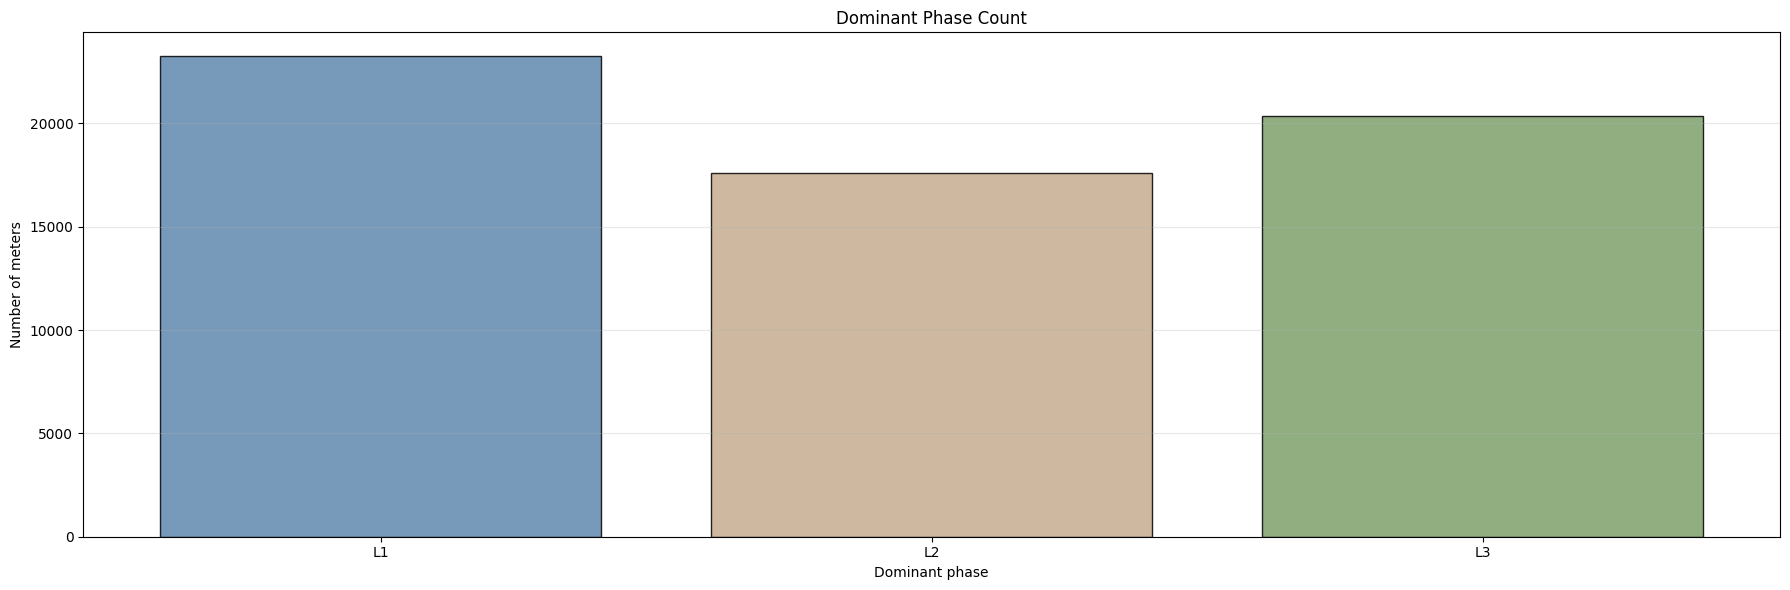

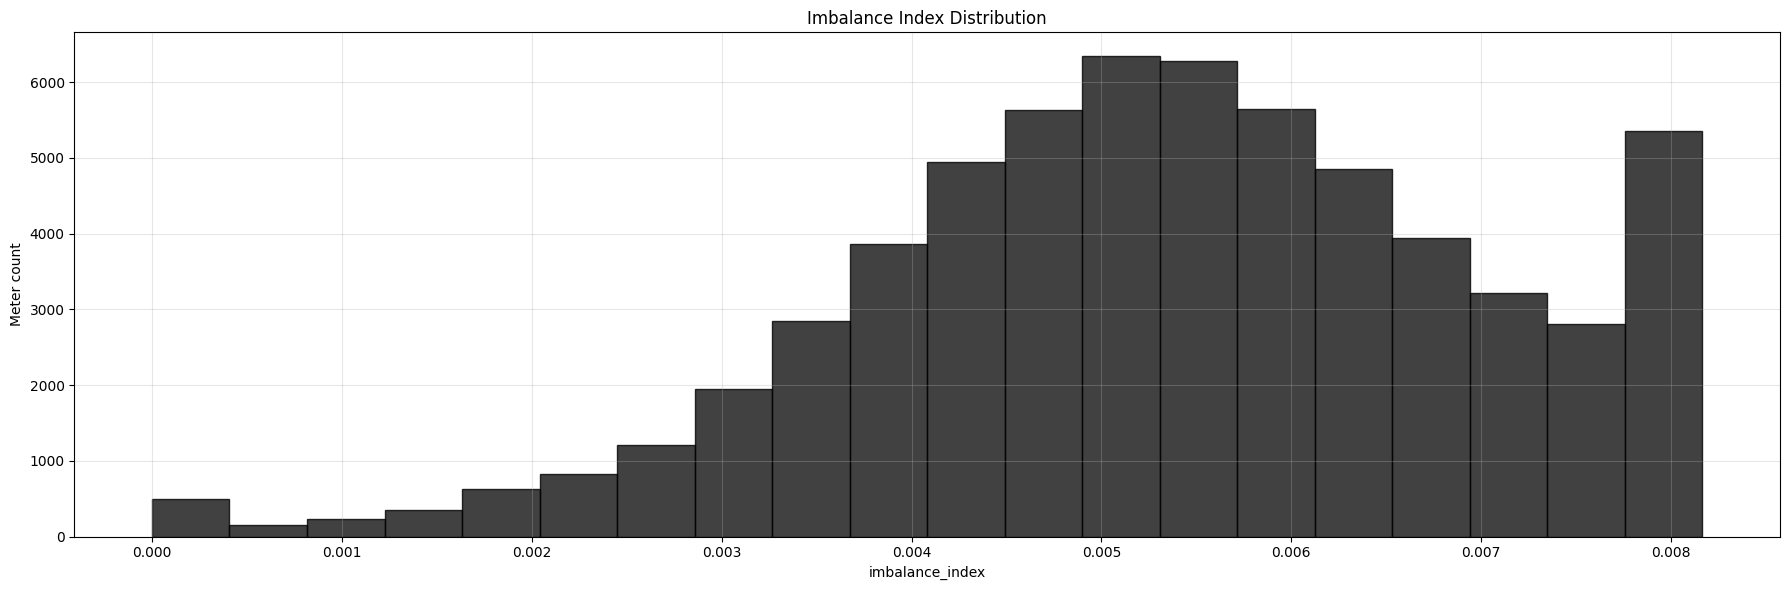

In [161]:
# Basic stats + informative plots for phase balance output

df_phase = phase_balance_df.copy()

share_cols = ['avg_l1_share', 'avg_l2_share', 'avg_l3_share']
for c in share_cols + ['imbalance_index']:
    df_phase[c] = pd.to_numeric(df_phase[c], errors='coerce')

# Useful summary numbers
dominant_counts = df_phase['dominant_phase'].value_counts().reindex(['L1', 'L2', 'L3'], fill_value=0)
summary_row = {
    'n_meters': int(len(df_phase)),
    'mean_imbalance_index': float(df_phase['imbalance_index'].mean()),
    'median_imbalance_index': float(df_phase['imbalance_index'].median()),
    # 'p90_imbalance_index': float(df_phase['imbalance_index'].quantile(0.90)),
    'max_imbalance_index': float(df_phase['imbalance_index'].max()),
    'mean_l1_share': float(df_phase['avg_l1_share'].mean()),
    'mean_l2_share': float(df_phase['avg_l2_share'].mean()),
    'mean_l3_share': float(df_phase['avg_l3_share'].mean()),
    'dominant_L1_count': int(dominant_counts['L1']),
    'dominant_L2_count': int(dominant_counts['L2']),
    'dominant_L3_count': int(dominant_counts['L3']),
}

print('Phase-balance summary stats:')
display(pd.DataFrame([summary_row]).round(4))

print('\nMeters with highest imbalance index:')
top_imbalance = df_phase.sort_values('imbalance_index', ascending=False)[
    ['meter_id', 'dominant_phase', 'imbalance_index', 'avg_l1_share', 'avg_l2_share', 'avg_l3_share']
].head(10)
display(top_imbalance.round(4))

# Plot 1: Dominant phase counts
plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
dom_colors = [plot_style.get_color(0), plot_style.get_color(1), plot_style.get_color(2)]
plt.bar(dominant_counts.index, dominant_counts.values, color=dom_colors, edgecolor='black', alpha=0.85)
plt.title('Dominant Phase Count')
plt.xlabel('Dominant phase')
plt.ylabel('Number of meters')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Plot 2: Distribution of imbalance index
plt.figure(figsize=plot_style.get_figsize(height_multiplier=1.0))
plt.hist(df_phase['imbalance_index'].dropna(), bins=20, color=plot_style.get_color_original(), edgecolor='black', alpha=0.8)
plt.title('Imbalance Index Distribution')
plt.xlabel('imbalance_index')
plt.ylabel('Meter count')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### 1-phase

---- does not make sense ----

### Plots distributions across all data

This plots the distributions using all available timesteps from all parquet files (L1, L2, L3, and Aggregated).

In [ ]:
class DistributionAnalyzer:
    def __init__(self, plotter, exclude_zeros: bool = True, verbose: bool = False):
        self.plotter = plotter
        self.exclude_zeros = exclude_zeros
        self.verbose = verbose

    def _log(self, msg: str):
        if self.verbose:
            print(msg)

    @staticmethod
    def _coerce_phases(df: pd.DataFrame):
        """
        Convert L1/L2/L3 to a float numpy array of shape (n, 3),
        coercing non-numeric values to 0.
        """
        arr = (
            df.loc[:, ["L1", "L2", "L3"]]
            .apply(pd.to_numeric, errors="coerce")
            .fillna(0.0)
            .to_numpy(dtype=np.float64, copy=False)
        )
        return arr

    def compute_and_save(self, meter_ids=None, progress_every=25, show_plot_inline=True):
        available = self.plotter.available_meters()

        if meter_ids is None:
            meters = available
        else:
            available_set = set(available)
            meters = [int(m) for m in meter_ids if int(m) in available_set]

        if not meters:
            raise ValueError("No valid meter IDs available for distribution analysis.")

        l1_parts = []
        l2_parts = []
        l3_parts = []
        agg_parts = []

        iterator = tqdm(
            meters,
            desc="Distribution analysis",
            unit="meter",
            miniters=max(1, int(progress_every)),
        )

        for meter_id in iterator:
            df_meter = self.plotter._load_meter_dataframe(meter_id)
            phase_arr = self._coerce_phases(df_meter)   # shape: (n, 3)

            l1 = phase_arr[:, 0]
            l2 = phase_arr[:, 1]
            l3 = phase_arr[:, 2]
            agg = phase_arr.sum(axis=1)

            l1_parts.append(l1)
            l2_parts.append(l2)
            l3_parts.append(l3)
            agg_parts.append(agg)

        L1_all = np.concatenate(l1_parts)
        L2_all = np.concatenate(l2_parts)
        L3_all = np.concatenate(l3_parts)
        Agg_all = np.concatenate(agg_parts)

        if self.plotter.data_mode == "hourly_csv":
            raw_series = {
                "Aggregated full-series distribution (all files)": Agg_all
            }
        else:
            raw_series = {
                "L1 full-series distribution (all files)": L1_all,
                "L2 full-series distribution (all files)": L2_all,
                "L3 full-series distribution (all files)": L3_all,
                "Aggregated full-series distribution (all files)": Agg_all,
            }

        kept_counts = {}
        plot_series = {}

        for title, series in raw_series.items():
            if self.exclude_zeros:
                filtered = series[series > 0]
                kept_counts[title] = {
                    "kept": int(filtered.size),
                    "total": int(series.size),
                }
                plot_series[title] = filtered
            else:
                kept_counts[title] = {
                    "kept": int(series.size),
                    "total": int(series.size),
                }
                plot_series[title] = series

        # ---- plotting ----
        suffix = " (zeros excluded)" if self.exclude_zeros else ""

        if self.plotter.data_mode == "hourly_csv":
            fig, ax = plt.subplots(
                1, 1, figsize=plot_style.get_figsize(height_multiplier=1.0)
            )
            title, data = next(iter(plot_series.items()))
            ax.hist(
                data,
                bins=120,
                edgecolor="black",
                alpha=0.75,
                color=plot_style.get_color_original(),
            )
            ax.set_title(f"{title}{suffix}")
            ax.set_xlabel("Energy (Wh)")
            ax.set_ylabel("Frequency")
            ax.grid(True, alpha=0.3)
        else:
            fig, axes = plt.subplots(
                2, 2, figsize=plot_style.get_figsize(height_multiplier=1.7)
            )
            colors = [
                plot_style.get_color(0),
                plot_style.get_color(1),
                plot_style.get_color(2),
                plot_style.get_color_original(),
            ]

            for ax, (title, data), color in zip(axes.flatten(), plot_series.items(), colors):
                ax.hist(
                    data,
                    bins=120,
                    edgecolor="black",
                    alpha=0.75,
                    color=color,
                )
                ax.set_title(f"{title}{suffix}")
                ax.set_xlabel("Energy (Wh)")
                ax.set_ylabel("Frequency")
                ax.grid(True, alpha=0.3)

        plt.tight_layout()
        full_dist_plot_path = os.path.join(
            output_dir_data_analysis,
            "full_series_phase_distributions.png",
        )
        fig.savefig(full_dist_plot_path, dpi=200, bbox_inches="tight")

        if show_plot_inline:
            plt.show()
        plt.close(fig)

        distribution_summary_path = save_json(
            {
                "processed_files": int(len(meters)),
                "total_samples_per_phase": int(L1_all.size),
                "non_zero_counts": {
                    "L1": int(np.count_nonzero(L1_all > 0)),
                    "L2": int(np.count_nonzero(L2_all > 0)),
                    "L3": int(np.count_nonzero(L3_all > 0)),
                    "Aggregated": int(np.count_nonzero(Agg_all > 0)),
                },
                "exclude_zeros": bool(self.exclude_zeros),
                "kept_counts": kept_counts,
            },
            "full_series_distribution_summary.json",
        )

        return full_dist_plot_path, distribution_summary_path

In [ ]:
# class DistributionAnalyzer:
#     def __init__(self, plotter: SmartMeterDayPlotter, exclude_zeros: bool = True, verbose: bool = False):
#         self.plotter = plotter
#         self.exclude_zeros = exclude_zeros
#         self.verbose = verbose

#     def _log(self, msg: str):
#         if self.verbose:
#             print(msg)

#     def compute_and_save(self, meter_ids=None, progress_every=25, show_plot_inline=True):
#         available = self.plotter.available_meters()
#         if meter_ids is None:
#             meters = available
#         else:
#             meter_ids = [int(m) for m in meter_ids]
#             meters = [m for m in meter_ids if m in set(available)]

#         all_l1, all_l2, all_l3 = [], [], []
#         processed = 0

#         iterator = tqdm(
#             meters,
#             desc='Distribution analysis',
#             unit='meter',
#             miniters=max(1, int(progress_every)),
#         )
#         for meter_id in iterator:
#             df_meter = self.plotter._load_meter_dataframe(meter_id)

#             all_l1.append(pd.to_numeric(df_meter["L1"], errors="coerce").fillna(0.0).to_numpy())
#             all_l2.append(pd.to_numeric(df_meter["L2"], errors="coerce").fillna(0.0).to_numpy())
#             all_l3.append(pd.to_numeric(df_meter["L3"], errors="coerce").fillna(0.0).to_numpy())
#             processed += 1

#         if processed == 0:
#             raise ValueError("No meter data was processed for distribution analysis.")

#         L1_all = np.concatenate(all_l1)
#         L2_all = np.concatenate(all_l2)
#         L3_all = np.concatenate(all_l3)
#         Agg_all = L1_all + L2_all + L3_all

#         if self.plotter.data_mode == "hourly_csv":
#             raw_series_list = [Agg_all]
#             titles = ["Aggregated full-series distribution (all files)"]
#         else:
#             raw_series_list = [L1_all, L2_all, L3_all, Agg_all]
#             titles = [
#                 "L1 full-series distribution (all files)",
#                 "L2 full-series distribution (all files)",
#                 "L3 full-series distribution (all files)",
#                 "Aggregated full-series distribution (all files)",
#             ]

#         series_list = []
#         kept_counts = {}
#         for series, title in zip(raw_series_list, titles):
#             if self.exclude_zeros:
#                 filtered = series[series > 0]
#                 kept_counts[title] = {"kept": int(len(filtered)), "total": int(len(series))}
#                 series_list.append(filtered)
#             else:
#                 kept_counts[title] = {"kept": int(len(series)), "total": int(len(series))}
#                 series_list.append(series)

#         if self.plotter.data_mode == "hourly_csv":
#             fig, ax = plt.subplots(1, 1, figsize=plot_style.get_figsize(height_multiplier=1.0))
#             data = series_list[0]
#             title = titles[0]
#             ax.hist(data, bins=120, edgecolor="black", alpha=0.75, color=plot_style.get_color_original())
#             suffix = " (zeros excluded)" if self.exclude_zeros else ""
#             ax.set_title(f"{title}{suffix}")
#             ax.set_xlabel("Energy (Wh)")
#             ax.set_ylabel("Frequency")
#             ax.grid(True, alpha=0.3)
#         else:
#             fig, axes = plt.subplots(2, 2, figsize=plot_style.get_figsize(height_multiplier=1.7))
#             dist_colors = [plot_style.get_color(0), plot_style.get_color(1), plot_style.get_color(2), plot_style.get_color_original()]
#             for idx, (ax, data, title) in enumerate(zip(axes.flatten(), series_list, titles)):
#                 ax.hist(data, bins=120, edgecolor="black", alpha=0.75, color=dist_colors[idx])
#                 suffix = " (zeros excluded)" if self.exclude_zeros else ""
#                 ax.set_title(f"{title}{suffix}")
#                 ax.set_xlabel("Energy (Wh)")
#                 ax.set_ylabel("Frequency")
#                 ax.grid(True, alpha=0.3)

#         plt.tight_layout()
#         full_dist_plot_path = os.path.join(output_dir_data_analysis, "full_series_phase_distributions.png")
#         fig.savefig(full_dist_plot_path, dpi=200, bbox_inches="tight")
#         if show_plot_inline:
#             plt.show()
#         plt.close(fig)

#         distribution_summary_path = save_json(
#             {
#                 "processed_files": int(processed),
#                 "total_samples_per_phase": int(len(L1_all)),
#                 "non_zero_counts": {
#                     "L1": int((L1_all > 0).sum()),
#                     "L2": int((L2_all > 0).sum()),
#                     "L3": int((L3_all > 0).sum()),
#                     "Aggregated": int((Agg_all > 0).sum()),
#                 },
#                 "exclude_zeros": bool(self.exclude_zeros),
#                 "kept_counts": kept_counts,
#             },
#             "full_series_distribution_summary.json",
#         )

#         return full_dist_plot_path, distribution_summary_path

In [ ]:
# Full-series distributions
distribution_analyzer = DistributionAnalyzer(
    plotter=plotter,
    exclude_zeros=True,
    verbose=False,
)

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run_distribution = None

full_dist_plot_path, distribution_summary_path = distribution_analyzer.compute_and_save(
    meter_ids=meter_ids_to_run_distribution,
    progress_every=25,
    show_plot_inline=True,
)

print("Distribution analysis completed.")
print(f"Saved distribution plot: {full_dist_plot_path}")
print(f"Saved summary json: {distribution_summary_path}")

with open(distribution_summary_path, "r", encoding="utf-8") as f:
    distribution_summary = json.load(f)

print("\nSummary preview:")
display(pd.DataFrame([distribution_summary]))

Distribution analysis:  91%|█████████ | 55989/61557 [1:28:50<08:50, 10.50meter/s]   

KeyboardInterrupt



### Seasonality 

Analyzes temporal patterns in aggregated load:
- Monthly distributions and average load by month
- Weekday vs weekend patterns (what it looks like)
- Statistical comparison of calendar effects (weekday load vs weekend load)


In [6]:
class SeasonalityAnalyzer:
    def __init__(self, plotter: SmartMeterDayPlotter):
        self.plotter = plotter

    @staticmethod
    def _safe_concat(arr_list):
        if not arr_list:
            return np.array([], dtype=np.float32)
        if len(arr_list) == 1:
            return arr_list[0]
        return np.concatenate(arr_list)

    @staticmethod
    def _stats_from_values(values: np.ndarray):
        if values.size == 0:
            return np.nan, np.nan, np.nan, 0
        return (
            float(np.mean(values)),
            float(np.median(values)),
            float(np.std(values, ddof=1)) if values.size > 1 else 0.0,
            int(values.size),
        )

    def compute_stats(self, meter_ids=None, progress_every=25):
        """Analyze calendar effects across aggregated load data (memory-optimized)."""
        available = self.plotter.available_meters()
        if meter_ids is None:
            meters = available
        else:
            meter_ids = [int(m) for m in meter_ids]
            meters = [m for m in meter_ids if m in set(available)]

        if len(meters) == 0:
            return None, None, None

        # Store only scalar arrays needed for grouped stats.
        month_buckets = {m: [] for m in range(1, 13)}
        wdwe_buckets = {False: [], True: []}  # False=weekday, True=weekend
        weekday_buckets = {d: [] for d in range(7)}

        iterator = tqdm(
            meters,
            desc='Seasonality analysis',
            unit='meter',
            miniters=max(1, int(progress_every)),
        )

        for meter_id in iterator:
            df_meter = self.plotter._load_meter_dataframe(meter_id)

            ts = pd.to_datetime(df_meter.index, errors='coerce', utc=True)
            agg = pd.to_numeric(df_meter['Aggregated'], errors='coerce').fillna(0.0).to_numpy(dtype=np.float32)

            valid_mask = ~pd.isna(ts)
            if not np.any(valid_mask):
                continue

            ts_valid = ts[valid_mask]
            agg_valid = agg[valid_mask]

            months = ts_valid.month.to_numpy(dtype=np.int8)
            weekdays = ts_valid.dayofweek.to_numpy(dtype=np.int8)
            is_weekend = weekdays >= 5

            # Bucket by month (1..12)
            for m in range(1, 13):
                mask = months == m
                if np.any(mask):
                    month_buckets[m].append(agg_valid[mask])

            # Bucket by weekday/weekend
            wd_mask = ~is_weekend
            we_mask = is_weekend
            if np.any(wd_mask):
                wdwe_buckets[False].append(agg_valid[wd_mask])
            if np.any(we_mask):
                wdwe_buckets[True].append(agg_valid[we_mask])

            # Bucket by weekday 0..6
            for d in range(7):
                mask = weekdays == d
                if np.any(mask):
                    weekday_buckets[d].append(agg_valid[mask])

            del df_meter, ts, agg, valid_mask, ts_valid, agg_valid, months, weekdays, is_weekend

        # Monthly statistics
        month_rows = []
        month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
        for m in range(1, 13):
            vals = self._safe_concat(month_buckets[m])
            mean_v, median_v, std_v, count_v = self._stats_from_values(vals)
            month_rows.append({
                'month': m,
                'mean_wh': round(mean_v, 4) if not np.isnan(mean_v) else np.nan,
                'median_wh': round(median_v, 4) if not np.isnan(median_v) else np.nan,
                'std_wh': round(std_v, 4) if not np.isnan(std_v) else np.nan,
                'count_intervals': count_v,
                'month_name': month_names[m - 1],
            })
        month_stats = pd.DataFrame(month_rows)

        # Weekday vs weekend statistics
        wdwe_rows = []
        for is_we, day_type in [(False, 'Weekday'), (True, 'Weekend')]:
            vals = self._safe_concat(wdwe_buckets[is_we])
            mean_v, median_v, std_v, count_v = self._stats_from_values(vals)
            wdwe_rows.append({
                'day_type': day_type,
                'mean_wh': round(mean_v, 4) if not np.isnan(mean_v) else np.nan,
                'median_wh': round(median_v, 4) if not np.isnan(median_v) else np.nan,
                'std_wh': round(std_v, 4) if not np.isnan(std_v) else np.nan,
                'count_intervals': count_v,
            })
        wd_we_stats = pd.DataFrame(wdwe_rows)

        # Detailed weekday breakdown
        weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
        weekday_rows = []
        for d in range(7):
            vals = self._safe_concat(weekday_buckets[d])
            mean_v, median_v, std_v, count_v = self._stats_from_values(vals)
            weekday_rows.append({
                'mean_wh': round(mean_v, 4) if not np.isnan(mean_v) else np.nan,
                'median_wh': round(median_v, 4) if not np.isnan(median_v) else np.nan,
                'std_wh': round(std_v, 4) if not np.isnan(std_v) else np.nan,
                'count_intervals': count_v,
                'weekday_name': weekday_names[d],
            })
        weekday_stats = pd.DataFrame(weekday_rows)

        return month_stats, wd_we_stats, weekday_stats

In [ ]:
# class SeasonalityAnalyzer:
#     def __init__(self, plotter: SmartMeterDayPlotter):
#         self.plotter = plotter

#     def compute_stats(self, meter_ids=None, progress_every=25):
#         """Analyze calendar effects across aggregated load data."""
#         available = self.plotter.available_meters()
#         if meter_ids is None:
#             meters = available
#         else:
#             meter_ids = [int(m) for m in meter_ids]
#             meters = [m for m in meter_ids if m in set(available)]

#         all_data = []
#         iterator = tqdm(
#             meters,
#             desc='Seasonality analysis',
#             unit='meter',
#             miniters=max(1, int(progress_every)),
#         )
#         for meter_id in iterator:
#             df_meter = self.plotter._load_meter_dataframe(meter_id)
#             df_temp = pd.DataFrame({
#                 'timestamp': df_meter.index,
#                 'agg_wh': pd.to_numeric(df_meter['Aggregated'], errors='coerce').fillna(0.0).values,
#             }).dropna(subset=['timestamp']).sort_values('timestamp')

#             df_temp['month'] = df_temp['timestamp'].dt.month
#             df_temp['weekday'] = df_temp['timestamp'].dt.dayofweek
#             df_temp['is_weekend'] = df_temp['weekday'].isin([5, 6])

#             all_data.append(df_temp)

#         if len(all_data) == 0:
#             return None, None, None

#         # Combine all data
#         combined_df = pd.concat(all_data, ignore_index=True)
#         combined_df = combined_df.sort_values('timestamp').reset_index(drop=True)

#         # Monthly statistics
#         month_stats = combined_df.groupby('month').agg({
#             'agg_wh': ['mean', 'median', 'std', 'count']
#         }).round(4)
#         month_stats.columns = ['mean_wh', 'median_wh', 'std_wh', 'count_intervals']
#         month_stats = month_stats.reset_index()
#         month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
#         month_stats['month_name'] = month_stats['month'].map(lambda m: month_names[m-1] if 1 <= m <= 12 else 'Unknown')

#         # Weekday vs Weekend statistics
#         wd_we_stats = combined_df.groupby('is_weekend').agg({
#             'agg_wh': ['mean', 'median', 'std', 'count']
#         }).round(4)
#         wd_we_stats.columns = ['mean_wh', 'median_wh', 'std_wh', 'count_intervals']
#         wd_we_stats.index = ['Weekday', 'Weekend']
#         wd_we_stats = wd_we_stats.reset_index().rename(columns={'index': 'day_type'})

#         # Detailed weekday breakdown
#         weekday_stats = combined_df.groupby('weekday').agg({
#             'agg_wh': ['mean', 'median', 'std', 'count']
#         }).round(4)
#         weekday_stats.columns = ['mean_wh', 'median_wh', 'std_wh', 'count_intervals']
#         weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
#         weekday_stats['weekday_name'] = [weekday_names[i] for i in weekday_stats.index]
#         weekday_stats = weekday_stats.reset_index(drop=True)

#         return month_stats, wd_we_stats, weekday_stats

##### 3-phase 

In [12]:
# Seasonality analysis in 4 batches to reduce memory pressure
plotter = make_plotter(verbose=False)
seasonality_analyzer = SeasonalityAnalyzer(plotter=plotter)

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run_seasonality = None

available_meters = plotter.available_meters()
if meter_ids_to_run_seasonality is None:
    meters_for_run = available_meters
else:
    selected = [int(m) for m in meter_ids_to_run_seasonality]
    meters_for_run = [m for m in selected if m in set(available_meters)]

if len(meters_for_run) == 0:
    raise ValueError("No meters available for seasonality analysis.")

batch_meter_lists = [list(arr) for arr in np.array_split(meters_for_run, 4) if len(arr) > 0]
print(f"Running seasonality in {len(batch_meter_lists)} batches.")

month_batch_frames = []
wdwe_batch_frames = []
weekday_batch_frames = []
summary_batch_rows = []
saved_batch_files = []

for i, batch_meters in enumerate(batch_meter_lists, start=1):
    batch_tag = f"batch_{i}"
    print(f"\n--- Processing {batch_tag} ({len(batch_meters)} meters) ---")

    month_stats, wd_we_stats, weekday_stats = seasonality_analyzer.compute_stats(
        meter_ids=batch_meters,
        progress_every=25,
    )

    if month_stats is not None:
        month_out = month_stats[['month_name', 'mean_wh', 'median_wh', 'std_wh', 'count_intervals']].copy()
        month_out['batch'] = batch_tag
        month_path = save_df(month_out, f"seasonality_monthly_stats_{batch_tag}.csv")
        month_batch_frames.append(month_out)
    else:
        month_path = None

    if wd_we_stats is not None:
        wdwe_out = wd_we_stats[['day_type', 'mean_wh', 'median_wh', 'std_wh', 'count_intervals']].copy()
        wdwe_out['batch'] = batch_tag
        wdwe_path = save_df(wdwe_out, f"seasonality_weekday_vs_weekend_{batch_tag}.csv")
        wdwe_batch_frames.append(wdwe_out)

        weekday_mean = wd_we_stats[wd_we_stats['day_type'] == 'Weekday']['mean_wh'].values[0]
        weekend_mean = wd_we_stats[wd_we_stats['day_type'] == 'Weekend']['mean_wh'].values[0]
        pct_diff = ((weekday_mean - weekend_mean) / weekend_mean * 100) if weekend_mean > 0 else 0
        summary_payload = {
            'batch': batch_tag,
            'weekday_mean_wh': float(weekday_mean),
            'weekend_mean_wh': float(weekend_mean),
            'weekday_vs_weekend_pct_diff': float(pct_diff),
        }
        summary_path = save_json(summary_payload, f"seasonality_summary_{batch_tag}.json")
        summary_batch_rows.append(summary_payload)
    else:
        wdwe_path = None
        summary_path = None

    if weekday_stats is not None:
        weekday_out = weekday_stats[['weekday_name', 'mean_wh', 'median_wh', 'std_wh', 'count_intervals']].copy()
        weekday_out['batch'] = batch_tag
        weekday_path = save_df(weekday_out, f"seasonality_weekday_detail_{batch_tag}.csv")
        weekday_batch_frames.append(weekday_out)
    else:
        weekday_path = None

    saved_batch_files.append({
        'batch': batch_tag,
        'month_stats_path': month_path,
        'weekday_weekend_path': wdwe_path,
        'weekday_detail_path': weekday_path,
        'summary_path': summary_path,
    })

# Optional combined in-memory views for quick preview (no heavy recomputation)
month_stats_out = pd.concat(month_batch_frames, ignore_index=True) if month_batch_frames else pd.DataFrame()
wd_we_out = pd.concat(wdwe_batch_frames, ignore_index=True) if wdwe_batch_frames else pd.DataFrame()
weekday_stats_out = pd.concat(weekday_batch_frames, ignore_index=True) if weekday_batch_frames else pd.DataFrame()
seasonality_summary_batches = pd.DataFrame(summary_batch_rows)

print("\nSeasonality analysis completed in batches.")
for row in saved_batch_files:
    print(
        f"{row['batch']}: monthly={row['month_stats_path']}, "
        f"wd/we={row['weekday_weekend_path']}, "
        f"weekday={row['weekday_detail_path']}, "
        f"summary={row['summary_path']}"
    )

print("\nPreview: monthly stats (all batches)")
display(month_stats_out.head(12))

print("\nPreview: weekday vs weekend stats (all batches)")
display(wd_we_out.head(10))

print("\nPreview: weekday detail stats (all batches)")
display(weekday_stats_out.head(10))

print("\nPreview: batch summaries")
display(seasonality_summary_batches.head(10))

Running seasonality in 4 batches.

--- Processing batch_1 (15390 meters) ---


Seasonality analysis: 100%|██████████| 15390/15390 [18:12<00:00, 14.08meter/s]



--- Processing batch_2 (15389 meters) ---


Seasonality analysis: 100%|██████████| 15389/15389 [18:27<00:00, 13.90meter/s]



--- Processing batch_3 (15389 meters) ---


...

,day_type,mean_wh,median_wh,std_wh,count_intervals,batch
0,Weekday,666.0141,152.0,3479.1973,282391110,batch_1
1,Weekend,669.9318,156.0,3305.7922,112285440,batch_1
2,Weekday,644.0989,152.0,3279.4146,282372761,batch_2
3,Weekend,636.1198,156.0,2469.1616,112278144,batch_2
4,Weekday,667.8259,152.0,3584.1189,282372761,batch_3
5,Weekend,665.2744,156.0,3305.4360,112278144,batch_3
6,Weekday,635.2761,147.0,3034.2190,282372761,batch_4
7,Weekend,638.3585,151.0,2809.2659,112278144,batch_4



Preview: weekday detail stats (all batches)


,weekday_name,mean_wh,median_wh,std_wh,count_intervals,batch
0,Mon,648.1935,148.0,3438.2388,57081510,batch_1
1,Tue,660.3968,151.0,3487.2600,56881440,batch_1
2,Wed,677.1557,157.0,3528.9316,56142720,batch_1
3,Thu,662.1956,148.0,3464.0090,56142720,batch_1
4,Fri,682.5009,155.0,3477.3718,56142720,batch_1
5,Sat,677.0881,159.0,3319.6980,56142720,batch_1
6,Sun,662.7754,152.0,3291.8123,56142720,batch_1
7,Mon,626.6537,148.0,3206.6091,57077801,batch_2
8,Tue,640.5182,151.0,3379.7163,56877744,batch_2
9,Wed,656.9807,157.0,3393.0681,56139072,batch_2



Preview: batch summaries


,batch,weekday_mean_wh,weekend_mean_wh,weekday_vs_weekend_pct_diff
0,batch_1,666.0141,669.9318,-0.584791
1,batch_2,644.0989,636.1198,1.254339
2,batch_3,667.8259,665.2744,0.383526
3,batch_4,635.2761,638.3585,-0.482863


In [17]:
# Load merged seasonality artifacts (single files)

loaded_month_stats_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_monthly_stats.csv"
loaded_wd_we_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_weekday_vs_weekend.csv"
loaded_weekday_stats_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_weekday_detail.csv"
loaded_seasonality_summary_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_summary.json"

month_stats_out = pd.read_csv(loaded_month_stats_path) if os.path.exists(loaded_month_stats_path) else pd.DataFrame()
wd_we_out = pd.read_csv(loaded_wd_we_path) if os.path.exists(loaded_wd_we_path) else pd.DataFrame()
weekday_stats_out = pd.read_csv(loaded_weekday_stats_path) if os.path.exists(loaded_weekday_stats_path) else pd.DataFrame()

if os.path.exists(loaded_seasonality_summary_path):
    with open(loaded_seasonality_summary_path, "r", encoding="utf-8") as f:
        summary_payload = json.load(f)
    seasonality_summary_df = pd.DataFrame(summary_payload) if isinstance(summary_payload, list) else pd.DataFrame([summary_payload])
else:
    seasonality_summary_df = pd.DataFrame()

print("Loaded merged seasonality artifacts.")
print(f"month_stats_out rows: {len(month_stats_out)}")
print(f"wd_we_out rows: {len(wd_we_out)}")
print(f"weekday_stats_out rows: {len(weekday_stats_out)}")
print(f"seasonality_summary_df rows: {len(seasonality_summary_df)}")

print("\nPreview: monthly stats")
display(month_stats_out.head(12))

print("\nPreview: weekday vs weekend stats")
display(wd_we_out.head(10))

print("\nPreview: weekday detail stats")
display(weekday_stats_out.head(10))

print("\nPreview: seasonality summary")
display(seasonality_summary_df.head(10))

Loaded merged seasonality artifacts.
month_stats_out rows: 48
wd_we_out rows: 8
weekday_stats_out rows: 28
seasonality_summary_df rows: 4

Preview: monthly stats


,month_name,mean_wh,median_wh,std_wh,count_intervals,batch
0,Jan,1113.4093,406.0,4379.0581,45800640,batch_1
1,Feb,923.7412,311.0,4217.0776,42845760,batch_1
2,Mar,862.8958,284.0,4052.9612,45800640,batch_1
3,Apr,721.3819,218.0,3804.2686,44323200,batch_1
4,May,321.6506,17.0,2791.1179,40629600,batch_1
5,Jun,NaN,NaN,NaN,0,batch_1
6,Jul,NaN,NaN,NaN,0,batch_1
7,Aug,NaN,NaN,NaN,0,batch_1
8,Sep,87.0107,0.0,716.0546,39352230,batch_1
9,Oct,261.3709,0.0,1276.9303,45800640,batch_1



Preview: weekday vs weekend stats


,day_type,mean_wh,median_wh,std_wh,count_intervals,batch
0,Weekday,666.0141,152.0,3479.1973,282391110,batch_1
1,Weekend,669.9318,156.0,3305.7922,112285440,batch_1
2,Weekday,644.0989,152.0,3279.4146,282372761,batch_2
3,Weekend,636.1198,156.0,2469.1616,112278144,batch_2
4,Weekday,667.8259,152.0,3584.1189,282372761,batch_3
5,Weekend,665.2744,156.0,3305.4360,112278144,batch_3
6,Weekday,635.2761,147.0,3034.2190,282372761,batch_4
7,Weekend,638.3585,151.0,2809.2659,112278144,batch_4



Preview: weekday detail stats


,weekday_name,mean_wh,median_wh,std_wh,count_intervals,batch
0,Mon,648.1935,148.0,3438.2388,57081510,batch_1
1,Tue,660.3968,151.0,3487.2600,56881440,batch_1
2,Wed,677.1557,157.0,3528.9316,56142720,batch_1
3,Thu,662.1956,148.0,3464.0090,56142720,batch_1
4,Fri,682.5009,155.0,3477.3718,56142720,batch_1
5,Sat,677.0881,159.0,3319.6980,56142720,batch_1
6,Sun,662.7754,152.0,3291.8123,56142720,batch_1
7,Mon,626.6537,148.0,3206.6091,57077801,batch_2
8,Tue,640.5182,151.0,3379.7163,56877744,batch_2
9,Wed,656.9807,157.0,3393.0681,56139072,batch_2



Preview: seasonality summary


,batch,weekday_mean_wh,weekend_mean_wh,weekday_vs_weekend_pct_diff
0,batch_1,666.0141,669.9318,-0.584791
1,batch_2,644.0989,636.1198,1.254339
2,batch_3,667.8259,665.2744,0.383526
3,batch_4,635.2761,638.3585,-0.482863


In [30]:
# Informative summary statistics from merged seasonality outputs (kWh + meter-hours)

if month_stats_out.empty or wd_we_out.empty or weekday_stats_out.empty:
    print("Seasonality tables are empty. Run the previous load cell first.")
else:
    month_df = month_stats_out.copy()
    wdwe_df = wd_we_out.copy()
    weekday_df = weekday_stats_out.copy()

    for c in ["mean_wh", "median_wh", "std_wh", "count_intervals"]:
        if c in month_df.columns:
            month_df[c] = pd.to_numeric(month_df[c], errors="coerce")
        if c in wdwe_df.columns:
            wdwe_df[c] = pd.to_numeric(wdwe_df[c], errors="coerce")
        if c in weekday_df.columns:
            weekday_df[c] = pd.to_numeric(weekday_df[c], errors="coerce")

    # Convert Wh -> kWh for thesis-friendly reporting
    for df in [month_df, wdwe_df, weekday_df]:
        df["mean_kwh"] = df["mean_wh"] / 1000.0
        df["median_kwh"] = df["median_wh"] / 1000.0
        df["std_kwh"] = df["std_wh"] / 1000.0
        df["meter_hours"] = df["count_intervals"]

    # Core monthly comparisons in kWh
    highest_month_row = month_df.loc[month_df["mean_kwh"].idxmax()]
    lowest_month_row = month_df.loc[month_df["mean_kwh"].idxmin()]

    # Weekday vs weekend comparison in kWh
    weekday_mean_kwh = float(wdwe_df.loc[wdwe_df["day_type"] == "Weekday", "mean_kwh"].iloc[0])
    weekend_mean_kwh = float(wdwe_df.loc[wdwe_df["day_type"] == "Weekend", "mean_kwh"].iloc[0])
    wd_we_pct_diff = ((weekday_mean_kwh - weekend_mean_kwh) / weekend_mean_kwh * 100.0) if weekend_mean_kwh > 0 else np.nan

    # Day-of-week extremes in kWh
    highest_dow_row = weekday_df.loc[weekday_df["mean_kwh"].idxmax()]
    lowest_dow_row = weekday_df.loc[weekday_df["mean_kwh"].idxmin()]

    summary_stats = {
        "n_month_rows": int(len(month_df)),
        "n_weekday_weekend_rows": int(len(wdwe_df)),
        "n_weekday_rows": int(len(weekday_df)),
        "overall_monthly_mean_of_mean_kwh": float(month_df["mean_kwh"].mean()),
        "highest_mean_month": str(highest_month_row["month_name"]),
        "highest_mean_month_kwh": float(highest_month_row["mean_kwh"]),
        "lowest_mean_month": str(lowest_month_row["month_name"]),
        "lowest_mean_month_kwh": float(lowest_month_row["mean_kwh"]),
        "weekday_mean_kwh": weekday_mean_kwh,
        "weekend_mean_kwh": weekend_mean_kwh,
        "weekday_vs_weekend_pct_diff": float(wd_we_pct_diff),
        "highest_weekday_name": str(highest_dow_row["weekday_name"]),
        "highest_weekday_mean_kwh": float(highest_dow_row["mean_kwh"]),
        "lowest_weekday_name": str(lowest_dow_row["weekday_name"]),
        "lowest_weekday_mean_kwh": float(lowest_dow_row["mean_kwh"]),
    }

    print("Seasonality summary statistics (kWh, meter-hours):")
    display(pd.DataFrame([summary_stats]).round(3))

    # Requested: average of mean over all rows with same month/day label
    month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    month_mean_agg = (
        month_df.groupby("month_name", as_index=False)
        .agg(
            avg_mean_kwh=("mean_kwh", "mean"),
            total_meter_hours=("meter_hours", "sum"),
            n_rows=("mean_kwh", "size"),
        )
    )
    month_mean_agg["month_name"] = pd.Categorical(month_mean_agg["month_name"], categories=month_order, ordered=True)
    month_mean_agg = month_mean_agg.sort_values("month_name").reset_index(drop=True)

    weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    weekday_mean_agg = (
        weekday_df.groupby("weekday_name", as_index=False)
        .agg(
            avg_mean_kwh=("mean_kwh", "mean"),
            total_meter_hours=("meter_hours", "sum"),
            n_rows=("mean_kwh", "size"),
        )
    )
    weekday_mean_agg["weekday_name"] = pd.Categorical(weekday_mean_agg["weekday_name"], categories=weekday_order, ordered=True)
    weekday_mean_agg = weekday_mean_agg.sort_values("weekday_name").reset_index(drop=True)

    print("\nAverage of mean_kwh across all rows per month:")
    display(month_mean_agg.round(3))

    print("\nAverage of mean_kwh across all rows per weekday:")
    display(weekday_mean_agg.round(3))

    if not seasonality_summary_df.empty:
        print("\nSaved seasonality summary payload:")
        display(seasonality_summary_df)

Seasonality summary statistics (kWh, meter-hours):


,n_month_rows,n_weekday_weekend_rows,n_weekday_rows,overall_monthly_mean_of_mean_kwh,highest_mean_month,highest_mean_month_kwh,lowest_mean_month,lowest_mean_month_kwh,weekday_mean_kwh,weekend_mean_kwh,weekday_vs_weekend_pct_diff,highest_weekday_name,highest_weekday_mean_kwh,lowest_weekday_name,lowest_weekday_mean_kwh
0,48,8,28,0.642,Jan,1.113,Sep,0.077,0.666,0.67,-0.585,Fri,0.683,Mon,0.618



Average of mean_kwh across all rows per month:


,month_name,avg_mean_kwh,total_meter_hours,n_rows
0,Jan,1.086,183193632,4
1,Feb,0.906,171374688,4
2,Mar,0.843,183193632,4
3,Apr,0.709,177284160,4
4,May,0.320,162510480,4
5,Jun,NaN,0,4
6,Jul,NaN,0,4
7,Aug,NaN,0,4
8,Sep,0.085,157401249,4
9,Oct,0.254,183193632,4



Average of mean_kwh across all rows per weekday:


,weekday_name,avg_mean_kwh,total_meter_hours,n_rows
0,Mon,0.635,228314913,4
1,Tue,0.649,227514672,4
2,Wed,0.665,224559936,4
3,Thu,0.649,224559936,4
4,Fri,0.668,224559936,4
5,Sat,0.660,224559936,4
6,Sun,0.645,224559936,4



Saved seasonality summary payload:


,batch,weekday_mean_wh,weekend_mean_wh,weekday_vs_weekend_pct_diff
0,batch_1,666.0141,669.9318,-0.584791
1,batch_2,644.0989,636.1198,1.254339
2,batch_3,667.8259,665.2744,0.383526
3,batch_4,635.2761,638.3585,-0.482863


##### 1-phase

In [7]:
# Seasonality analysis (1-phase, one parquet file at a time)
import gc
import glob
import os

# Choose which data to run for:
# - Set to None to run all available meters
# - Or set a list like [116, 225, 901] to run selected meters only
meter_ids_to_run_seasonality = None
preferred_hourly_energy_col = globals().get("hourly_energy_col", "hourly_energy_consumption")

# Optional safety knobs
seasonality_max_files = None   # e.g. 2 for quick/stable test
seasonality_progress_every_files = 1

if analysis_data_mode != "hourly_csv":
    raise ValueError("This cell is intended for 1-phase hourly parquet mode (analysis_data_mode='hourly_csv').")

if not os.path.isdir(hourly_csv_path):
    raise ValueError(f"Expected hourly_csv_path to be a directory of parquet files, got: {hourly_csv_path}")

# Discover input files
if "hourly_data_files" in globals() and len(hourly_data_files) > 0:
    input_files = list(hourly_data_files)
else:
    parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "hourly_measurements_*.parquet")))
    if not parquet_files:
        parquet_files = sorted(glob.glob(os.path.join(hourly_csv_path, "*.parquet")))
    input_files = parquet_files

if seasonality_max_files is not None:
    input_files = input_files[: int(seasonality_max_files)]

if len(input_files) == 0:
    raise FileNotFoundError(f"No parquet files found in directory: {hourly_csv_path}")

print(f"Running seasonality over {len(input_files)} parquet files (one file at a time).")

def _extract_timestamp_energy_meter(df_raw: pd.DataFrame, source_name: str) -> pd.DataFrame:
    df = df_raw.copy()

    # Handle parquet MultiIndex layouts
    if isinstance(df.index, pd.MultiIndex):
        if any(name in ["meter_number", "meter_id", "timestamp", "timestamp_dst", "timestamp_utc"] for name in df.index.names):
            df = df.reset_index()
    elif df.index.name in ["meter_number", "meter_id", "timestamp", "timestamp_dst", "timestamp_utc"]:
        df = df.reset_index()

    time_col = next((c for c in ["timestamp_utc", "timestamp_dst", "timestamp", "datetime", "time"] if c in df.columns), None)
    if time_col is None:
        raise ValueError(f"No timestamp column found in {source_name}")

    meter_col = next((c for c in ["meter_number", "meter_id", "smart_meter_id", "sm_id"] if c in df.columns), None)
    energy_col = None
    if preferred_hourly_energy_col in df.columns:
        energy_col = preferred_hourly_energy_col
    elif "hourly_energy_consumption" in df.columns:
        energy_col = "hourly_energy_consumption"
    elif "agg_wh" in df.columns:
        energy_col = "agg_wh"

    if energy_col is None:
        raise ValueError(f"No energy column found in {source_name}. Expected {preferred_hourly_energy_col} or hourly_energy_consumption or agg_wh")

    out = pd.DataFrame({
        "timestamp": pd.to_datetime(df[time_col], utc=True, errors="coerce"),
        "energy_raw": pd.to_numeric(df[energy_col], errors="coerce"),
    })

    # meter filter is optional
    if meter_col is not None:
        out["meter_id"] = pd.to_numeric(df[meter_col], errors="coerce")
    else:
        out["meter_id"] = np.nan

    out = out.dropna(subset=["timestamp", "energy_raw"]).copy()

    if meter_ids_to_run_seasonality is not None and "meter_id" in out.columns:
        target = set(int(m) for m in meter_ids_to_run_seasonality)
        out = out.dropna(subset=["meter_id"])
        out["meter_id"] = out["meter_id"].astype(int)
        out = out[out["meter_id"].isin(target)]

    # Convert to Wh for consistency with existing output naming
    if energy_col == "agg_wh":
        out["energy_wh"] = out["energy_raw"]
    else:
        out["energy_wh"] = out["energy_raw"] * 1000.0

    return out[["timestamp", "energy_wh"]]

def _stats_by_group(df: pd.DataFrame, group_col: str) -> pd.DataFrame:
    g = df.groupby(group_col)["energy_wh"]
    out = pd.DataFrame({
        group_col: g.mean().index,
        "mean_wh": g.mean().values,
        "median_wh": g.median().values,
        "std_wh": g.std().values,
        "count_intervals": g.count().values,
    })
    return out

month_batch_frames = []
wdwe_batch_frames = []
weekday_batch_frames = []

for i, file_path in enumerate(input_files, start=1):
    if i % seasonality_progress_every_files == 0:
        print(f"[{i}/{len(input_files)}] Processing {os.path.basename(file_path)}")

    df_file = pd.read_parquet(file_path)
    work = _extract_timestamp_energy_meter(df_file, source_name=os.path.basename(file_path))

    if work.empty:
        print(f"  Skipping empty/filtered file: {os.path.basename(file_path)}")
        del df_file, work
        gc.collect()
        continue

    work["month_name"] = work["timestamp"].dt.strftime("%b")
    work["weekday_idx"] = work["timestamp"].dt.weekday
    weekday_map = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
    work["weekday_name"] = work["weekday_idx"].map(weekday_map)
    work["day_type"] = np.where(work["weekday_idx"] < 5, "Weekday", "Weekend")

    month_out = _stats_by_group(work, "month_name")
    wdwe_out = _stats_by_group(work, "day_type")
    weekday_out = _stats_by_group(work, "weekday_name")

    month_out["file"] = os.path.basename(file_path)
    wdwe_out["file"] = os.path.basename(file_path)
    weekday_out["file"] = os.path.basename(file_path)

    month_batch_frames.append(month_out)
    wdwe_batch_frames.append(wdwe_out)
    weekday_batch_frames.append(weekday_out)

    del df_file, work, month_out, wdwe_out, weekday_out
    gc.collect()

def combine_weighted(batch_df: pd.DataFrame, group_col: str) -> pd.DataFrame:
    if batch_df.empty:
        return pd.DataFrame(columns=[group_col, "mean_wh", "median_wh", "std_wh", "count_intervals"])

    df = batch_df.copy()
    for c in ["mean_wh", "median_wh", "std_wh", "count_intervals"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=[group_col, "count_intervals"])

    def _wavg(series: pd.Series, weights: pd.Series) -> float:
        valid = (~series.isna()) & (~weights.isna()) & (weights > 0)
        if valid.sum() == 0:
            return np.nan
        return float(np.average(series[valid], weights=weights[valid]))

    rows = []
    for key, g in df.groupby(group_col, sort=False):
        w = g["count_intervals"]
        rows.append({
            group_col: key,
            "mean_wh": _wavg(g["mean_wh"], w),
            "median_wh": _wavg(g["median_wh"], w),
            "std_wh": _wavg(g["std_wh"], w),
            "count_intervals": float(w.sum()),
        })
    return pd.DataFrame(rows)

month_stats_out = combine_weighted(
    pd.concat(month_batch_frames, ignore_index=True) if month_batch_frames else pd.DataFrame(),
    "month_name",
)
wd_we_out = combine_weighted(
    pd.concat(wdwe_batch_frames, ignore_index=True) if wdwe_batch_frames else pd.DataFrame(),
    "day_type",
)
weekday_stats_out = combine_weighted(
    pd.concat(weekday_batch_frames, ignore_index=True) if weekday_batch_frames else pd.DataFrame(),
    "weekday_name",
)

month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
if not month_stats_out.empty:
    month_stats_out["month_name"] = pd.Categorical(month_stats_out["month_name"], categories=month_order, ordered=True)
    month_stats_out = month_stats_out.sort_values("month_name").reset_index(drop=True)

weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
if not weekday_stats_out.empty:
    weekday_stats_out["weekday_name"] = pd.Categorical(weekday_stats_out["weekday_name"], categories=weekday_order, ordered=True)
    weekday_stats_out = weekday_stats_out.sort_values("weekday_name").reset_index(drop=True)

month_stats_path = save_df(month_stats_out, "seasonality_monthly_stats.csv") if not month_stats_out.empty else None
wd_we_path = save_df(wd_we_out, "seasonality_weekday_vs_weekend.csv") if not wd_we_out.empty else None
weekday_stats_path = save_df(weekday_stats_out, "seasonality_weekday_detail.csv") if not weekday_stats_out.empty else None

if not wd_we_out.empty and {"Weekday", "Weekend"}.issubset(set(wd_we_out["day_type"])):
    weekday_mean = float(wd_we_out.loc[wd_we_out["day_type"] == "Weekday", "mean_wh"].iloc[0])
    weekend_mean = float(wd_we_out.loc[wd_we_out["day_type"] == "Weekend", "mean_wh"].iloc[0])
    pct_diff = ((weekday_mean - weekend_mean) / weekend_mean * 100) if weekend_mean > 0 else 0.0
    seasonality_summary_path = save_json(
        {
            "weekday_mean_wh": weekday_mean,
            "weekend_mean_wh": weekend_mean,
            "weekday_vs_weekend_pct_diff": float(pct_diff),
            "n_files": int(len(input_files)),
        },
        "seasonality_summary_1phase.json",
    )
else:
    seasonality_summary_path = None

print("Seasonality analysis completed (file-by-file mode).")
print(f"Saved monthly stats: {month_stats_path}")
print(f"Saved weekday/weekend stats: {wd_we_path}")
print(f"Saved weekday detail stats: {weekday_stats_path}")
print(f"Saved seasonality summary json: {seasonality_summary_path}")

print("\nPreview: monthly stats")
display(month_stats_out.head(12))

print("\nPreview: weekday vs weekend stats")
display(wd_we_out.head(10))

print("\nPreview: weekday detail stats")
display(weekday_stats_out.head(10))

Running seasonality over 12 parquet files (one file at a time).
[1/12] Processing hourly_measurements_2023_10.parquet
[2/12] Processing hourly_measurements_2023_11.parquet
[3/12] Processing hourly_measurements_2023_12.parquet
[4/12] Processing hourly_measurements_2023_9.parquet
[5/12] Processing hourly_measurements_2024_1.parquet
[6/12] Processing hourly_measurements_2024_2.parquet
[7/12] Processing hourly_measurements_2024_3.parquet
[8/12] Processing hourly_measurements_2024_4.parquet
[9/12] Processing hourly_measurements_2024_5.parquet
[10/12] Processing hourly_measurements_2024_6.parquet
[11/12] Processing hourly_measurements_2024_7.parquet
[12/12] Processing hourly_measurements_2024_8.parquet
Seasonality analysis completed (file-by-file mode).
Saved monthly stats: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_monthly_stats.csv
Saved weekday/weekend stats: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/o

,month_name,mean_wh,median_wh,std_wh,count_intervals
0,Jan,1296.570190,450.0,51020.127954,46163160.0
1,Feb,1099.721436,350.0,47148.007812,43228560.0
2,Mar,1018.306274,320.0,44240.529225,46169124.0
3,Apr,878.478577,240.0,42533.214844,44754384.0
4,May,679.278259,170.0,38228.921875,46269960.0
5,Jun,668.278625,160.0,38108.723191,44788800.0
6,Jul,654.040344,170.0,33548.876756,46295064.0
7,Aug,670.777344,160.0,39459.299445,46310687.0
8,Sep,651.126282,150.0,39490.105469,44589600.0
9,Oct,803.811462,160.0,4410.416504,15937696.0



Preview: weekday vs weekend stats


,day_type,mean_wh,median_wh,std_wh,count_intervals
0,Weekday,893.804092,255.263108,42298.882932,367575287.0
1,Weekend,887.819394,273.091421,39910.625140,147684148.0



Preview: weekday detail stats


,weekday_name,mean_wh,median_wh,std_wh,count_intervals
0,Mon,879.396059,252.281376,41648.937164,72630600.0
1,Tue,884.561698,251.606153,41450.423841,72632088.0
2,Wed,900.137450,254.488091,42926.697826,73607328.0
3,Thu,897.713941,254.697253,43072.239051,73608815.0
4,Fri,906.637936,264.407503,42304.579233,75096456.0
5,Sat,888.444804,272.265247,39893.779774,75096336.0
6,Sun,887.172397,273.120772,39920.934500,72587812.0


In [8]:
# Load seasonality artifacts 

loaded_month_stats_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_monthly_stats_1phase.csv"
loaded_wd_we_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_weekday_vs_weekend_1phase.csv"
loaded_weekday_stats_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_weekday_detail_1phase.csv"
# loaded_seasonality_summary_path = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_summary_1phase.json"

month_stats_out = pd.read_csv(loaded_month_stats_path)
wd_we_out = pd.read_csv(loaded_wd_we_path)
weekday_stats_out = pd.read_csv(loaded_weekday_stats_path)

# seasonality_summary = None
# if os.path.exists(loaded_seasonality_summary_path):
#     with open(loaded_seasonality_summary_path, "r", encoding="utf-8") as f:
#         seasonality_summary = json.load(f)

print(f"Loaded monthly stats file: {loaded_month_stats_path}")
print(f"Loaded weekday/weekend stats file: {loaded_wd_we_path}")
print(f"Loaded weekday detail stats file: {loaded_weekday_stats_path}")
print(f"month_stats_out rows: {len(month_stats_out)}")
print(f"wd_we_out rows: {len(wd_we_out)}")
print(f"weekday_stats_out rows: {len(weekday_stats_out)}")

# if seasonality_summary is not None:
#     print(f"Loaded summary file: {loaded_seasonality_summary_path}")
#     print("seasonality_summary:", seasonality_summary)
# else:
#     print(f"Summary file not found: {loaded_seasonality_summary_path}")

print("\nPreview: monthly stats")
display(month_stats_out.head(12))

print("\nPreview: weekday vs weekend stats")
display(wd_we_out.head(10))

print("\nPreview: weekday detail stats")
display(weekday_stats_out.head(10))

Loaded monthly stats file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_monthly_stats_1phase.csv
Loaded weekday/weekend stats file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_weekday_vs_weekend_1phase.csv
Loaded weekday detail stats file: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/output/data_analysis/seasonality_weekday_detail_1phase.csv
month_stats_out rows: 12
wd_we_out rows: 2
weekday_stats_out rows: 7

Preview: monthly stats


,month_name,mean_wh,median_wh,std_wh,count_intervals
0,Jan,1296.570190,450.0,51020.127954,46163160.0
1,Feb,1099.721436,350.0,47148.007812,43228560.0
2,Mar,1018.306274,320.0,44240.529225,46169124.0
3,Apr,878.478577,240.0,42533.214844,44754384.0
4,May,679.278259,170.0,38228.921875,46269960.0
5,Jun,668.278625,160.0,38108.723191,44788800.0
6,Jul,654.040344,170.0,33548.876756,46295064.0
7,Aug,670.777344,160.0,39459.299445,46310687.0
8,Sep,651.126282,150.0,39490.105469,44589600.0
9,Oct,803.811462,160.0,4410.416504,15937696.0



Preview: weekday vs weekend stats


,day_type,mean_wh,median_wh,std_wh,count_intervals
0,Weekday,893.804092,255.263108,42298.882932,367575287.0
1,Weekend,887.819394,273.091421,39910.625140,147684148.0



Preview: weekday detail stats


,weekday_name,mean_wh,median_wh,std_wh,count_intervals
0,Mon,879.396059,252.281376,41648.937164,72630600.0
1,Tue,884.561698,251.606153,41450.423841,72632088.0
2,Wed,900.137450,254.488091,42926.697826,73607328.0
3,Thu,897.713941,254.697253,43072.239051,73608815.0
4,Fri,906.637936,264.407503,42304.579233,75096456.0
5,Sat,888.444804,272.265247,39893.779774,75096336.0
6,Sun,887.172397,273.120772,39920.934500,72587812.0


## Advanced data analysis

### Active windows

In [64]:
# Worker function
def process_single_file(file_path: str, window_len: int = 24, stride: int = 1, 
                        variance_epsilon: float = 1e-5, zero_epsilon: float = 1e-5, 
                        hourly_aggregation: bool = True, aggregation_divisor: float = 1.0):
    try:
        feature_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
        time_col_candidates = ['timestamp_dst', 'timestamp', 'timestamp_utc']
        
        # read Parquet data
        parquet_file = pq.ParquetFile(file_path)
        file_cols = parquet_file.schema.names
        cols_to_load = []
        rename_map = {}
        for base_feat in feature_cols:
            matched_col = next((c for c in file_cols if c.startswith(base_feat)), None)
            if matched_col:
                cols_to_load.append(matched_col)
                rename_map[matched_col] = base_feat
        
        time_col_name = next((c for c in file_cols if c.lower() in time_col_candidates), None)
        if time_col_name and time_col_name not in cols_to_load:
            cols_to_load.append(time_col_name)
            
        if not cols_to_load:
            return 0, 0, 0, 0, 0
            
        df = pq.read_table(file_path, columns=cols_to_load).to_pandas()
        df = df.rename(columns=rename_map)
        
        # time index prep
        time_values = df[time_col_name] if time_col_name in df.columns else df.index
        df.index = pd.to_datetime(time_values, errors='coerce', utc=True)
        df = df[~df.index.isna() & ~df.index.duplicated(keep='last')].sort_index()
        if df.empty:
            return 0, 0, 0, 0, 0

        # calculate missing days 
        expected_days = (df.index.max() - df.index.min()).days + 1
        actual_days = len(np.unique(df.index.normalize()))
        missing_days = max(0, expected_days - actual_days)
        
        # imputation 
        base_frequency = '1h' if hourly_aggregation else '15min'
        if hourly_aggregation:
            df = df.resample(base_frequency).sum(min_count=1)
            if aggregation_divisor != 1.0:
                df = df / aggregation_divisor
        if df.empty:
            return 0, 0, 0, 0, missing_days
            
        full_index = pd.date_range(start=df.index.min(), end=df.index.max(), freq=base_frequency, tz=df.index.tz)
        df = df.reindex(full_index)
        
        for feat in feature_cols:
            if feat not in df.columns:
                df[feat] = np.nan
        
        values = df[feature_cols].apply(pd.to_numeric, errors='coerce').fillna(0.0).to_numpy(dtype=np.float32)
        
        T = values.shape[0]
        if T < window_len:
            return 0, 0, 0, 0, missing_days
            
        # instant vectorized sliding windows 
        # creates a view of shape (T - window_len + 1, 3, window_len) 
        windows = np.lib.stride_tricks.sliding_window_view(values, window_shape=window_len, axis=0)
        windows = np.transpose(windows, (0, 2, 1)) # Reshape to (Num_Windows, window_len, 3)
        
        if stride > 1:
            windows = windows[::stride]
            
        total_windows = windows.shape[0]
        if total_windows == 0:
            return 0, 0, 0, 0, missing_days
            
        # stats calculation
        seq_agg = windows.sum(axis=-1) # Shape: [Num_Windows, 24]
        window_sum = np.abs(seq_agg).sum(axis=-1) 
        is_zero = window_sum <= zero_epsilon
        window_var = np.var(seq_agg, axis=-1)
        is_flat = (window_var <= variance_epsilon) & (~is_zero)
        phase_sums = np.abs(windows).sum(axis=1) # Shape: [Num_Windows, 3]
        active_phases = (phase_sums > zero_epsilon).sum(axis=-1)
        is_partial = (active_phases > 0) & (active_phases < 3)
        
        return total_windows, int(is_zero.sum()), int(is_flat.sum()), int(is_partial.sum()), missing_days
        
    except Exception:
        # If a single file is completely corrupted, skip it so the whole run doesn't crash
        return 0, 0, 0, 0, 0


def _run_parallel(sm_files, num_workers, executor_cls):
    t_windows = t_zeros = t_flats = t_partials = t_missing = 0
    with executor_cls(max_workers=num_workers) as executor:
        futures = {executor.submit(process_single_file, f): f for f in sm_files}
        with tqdm(total=len(sm_files), desc="Scanning", unit="file") as pbar:
            for future in as_completed(futures):
                file_path = futures[future]
                try:
                    w, z, f, p, m = future.result()
                except Exception as exc:
                    print(f"Worker failed for {os.path.basename(file_path)}: {exc}")
                    w, z, f, p, m = 0, 0, 0, 0, 0
                t_windows += w
                t_zeros += z
                t_flats += f
                t_partials += p
                t_missing += m
                pbar.set_postfix({
                    'Win': f"{t_windows/1000000:.1f}M",
                    'Zero': t_zeros,
                    'Flat': t_flats,
                    'Part': t_partials
                })
                pbar.update(1)
    return t_windows, t_zeros, t_flats, t_partials, t_missing


def _run_sequential(sm_files):
    t_windows = t_zeros = t_flats = t_partials = t_missing = 0
    with tqdm(total=len(sm_files), desc="Scanning", unit="file") as pbar:
        for file_path in sm_files:
            w, z, f, p, m = process_single_file(file_path)
            t_windows += w
            t_zeros += z
            t_flats += f
            t_partials += p
            t_missing += m
            pbar.set_postfix({
                'Win': f"{t_windows/1000000:.1f}M",
                'Zero': t_zeros,
                'Flat': t_flats,
                'Part': t_partials
            })
            pbar.update(1)
    return t_windows, t_zeros, t_flats, t_partials, t_missing


def _print_report(t_windows, t_zeros, t_flats, t_partials, t_missing):
    if t_windows == 0:
        print("\nError: No valid data found.")
        return
    z_pct = (t_zeros / t_windows) * 100
    f_pct = (t_flats / t_windows) * 100
    p_pct = (t_partials / t_windows) * 100
    h_pct = 100.0 - z_pct - f_pct

    print("\n" + "=" * 70)
    print("PHASED PARQUET INTEGRITY REPORT (VECTORIZED)")
    print(f"Window len: 24h, Stride: 1h")
    print("=" * 70)
    print(f"Total windows scanned: {t_windows:,}")
    print(f"Total missing days:    {t_missing:,} (Meter completely offline)")
    print("-" * 70)
    print(f"Zero-Sum windows:      {t_zeros:,} ({z_pct:.2f}%) - Fully disconnected")
    print(f"Flatline windows:      {t_flats:,} ({f_pct:.2f}%) - Imputation artifacts")
    print(f"Partial dead phases:   {t_partials:,} ({p_pct:.2f}%) - 1 or 2 phases are 0.0")
    print("-" * 70)
    print(f"Fully active windows:  {t_windows - t_zeros - t_flats - t_partials:,} ({h_pct - p_pct:.2f}%)")
    print("=" * 70 + "\n")
    

def run_diagnostics(data_dir: str, num_workers: int = None, use_processes: bool = False):
    sm_files = glob.glob(os.path.join(data_dir, "*.parquet"))
    if not sm_files:
        print(f"No parquet files found in {data_dir}.")
        return

    if num_workers is None:
        num_workers = min(32, (os.cpu_count() or 1))

    mode = "processes" if use_processes else "threads"
    print(f"Launching diagnostics across {len(sm_files)} files using {num_workers} workers ({mode})...")

    try:
        if use_processes:
            totals = _run_parallel(sm_files, num_workers, ProcessPoolExecutor)
        else:
            totals = _run_parallel(sm_files, num_workers, ThreadPoolExecutor)
    except BrokenProcessPool:
        print("Process pool broke; retrying with threads...")
        totals = _run_parallel(sm_files, num_workers, ThreadPoolExecutor)
    except Exception as exc:
        print(f"Parallel execution failed ({exc}); retrying sequentially...")
        totals = _run_sequential(sm_files)

    _print_report(*totals)


run_diagnostics(
    # data_dir="F:/Data/processed_data/second_batch/individual_sm_datasets/raw_profiles"
    # data_dir="/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles",
    data_dir="/Volumes/USB/raw_profiles",
    use_processes=False
)

Launching diagnostics across 61557 files using 8 workers (threads)...


Scanning: 100%|██████████| 61557/61557 [1:51:43<00:00,  9.18file/s, Win=393.3M, Zero=9.76e+7, Flat=2211825, Part=6.33e+7]  



PHASED PARQUET INTEGRITY REPORT (VECTORIZED)
Window len: 24h, Stride: 1h
Total windows scanned: 393,287,673
Total missing days:    0 (Meter completely offline)
----------------------------------------------------------------------
Zero-Sum windows:      97,643,171 (24.83%) - Fully disconnected
Flatline windows:      2,211,825 (0.56%) - Imputation artifacts
Partial dead phases:   63,289,973 (16.09%) - 1 or 2 phases are 0.0
----------------------------------------------------------------------
Fully active windows:  230,142,704 (58.52%)



Launching diagnostics across 61557 files using 8 workers (threads)...

Scanning: 100%|██████████| 61557/61557 [1:51:43<00:00,  9.18file/s, Win=393.3M, Zero=9.76e+7, Flat=2211825, Part=6.33e+7]  

======================================================================

PHASED PARQUET INTEGRITY REPORT (VECTORIZED)

Window len: 24h, Stride: 1h

======================================================================

Total windows scanned: 393,287,673

Total missing days:    0 (Meter completely offline)

----------------------------------------------------------------------

Zero-Sum windows:      97,643,171 (24.83%) - Fully disconnected

Flatline windows:      2,211,825 (0.56%) - Imputation artifacts

Partial dead phases:   63,289,973 (16.09%) - 1 or 2 phases are 0.0

----------------------------------------------------------------------

Fully active windows:  230,142,704 (58.52%)

======================================================================

### Where does nan happen


Does NaN occur in the data itself, dataloading, aggregation, re-indexing, fill-na

In [67]:
def debug_dataloader_pipeline(file_path: str, verbose: bool = True):
    feature_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    meter_name = os.path.basename(file_path)

    if verbose:
        print(f"\n{'='*50}")
        print(f"NAN OCCURENCE ANALYSIS FOR METER: {meter_name}")
        print(f"{'='*50}")

    # Read Parquet data
    parquet_file = pq.ParquetFile(file_path)
    file_cols = parquet_file.schema.names

    cols_to_load = [c for c in file_cols if any(c.startswith(f) for f in feature_cols)]
    time_col = next((c for c in file_cols if c.lower() in ['timestamp_dst', 'timestamp', 'timestamp_utc']), None)
    if time_col:
        cols_to_load.append(time_col)

    df = pq.read_table(file_path, columns=cols_to_load).to_pandas()

    # Standardize column names for ease of debugging
    for col in df.columns:
        for base_feat in feature_cols:
            if col.startswith(base_feat):
                df = df.rename(columns={col: base_feat})
                break

    time_values = df[time_col] if time_col in df.columns else df.index
    df.index = pd.to_datetime(time_values, errors='coerce', utc=True)
    df = df[~df.index.isna() & ~df.index.duplicated(keep='last')].sort_index()

    total_rows_raw = len(df)
    raw_zeros = (df[feature_cols] == 0.0).all(axis=1).sum()
    raw_nans = df[feature_cols].isna().any(axis=1).sum()

    if verbose:
        print("\n--- TEST 1: RAW DATA (From Parquet) ---")
        print(f"Total Rows: {total_rows_raw}")
        if total_rows_raw > 0:
            print(f"Rows with actual 0.0 on all phases: {raw_zeros} ({raw_zeros/total_rows_raw*100:.2f}%)")
            print(f"Rows with NaN values:               {raw_nans} ({raw_nans/total_rows_raw*100:.2f}%)")
        else:
            print("Rows with actual 0.0 on all phases: 0 (0.00%)")
            print("Rows with NaN values:               0 (0.00%)")

    # --- TEST --- Resampling (Hourly Aggregation)
    df_resampled = df.resample('1h').sum(min_count=1)
    total_rows_res = len(df_resampled)
    res_zeros = (df_resampled[feature_cols] == 0.0).all(axis=1).sum()
    res_nans = df_resampled[feature_cols].isna().any(axis=1).sum()

    if verbose:
        print("\n--- TEST 2: AFTER RESAMPLING ('1h') ---")
        print(f"Total Rows: {total_rows_res}")
        if total_rows_res > 0:
            print(f"Rows with actual 0.0 on all phases: {res_zeros} ({res_zeros/total_rows_res*100:.2f}%)")
            print(f"Rows with NaN values:               {res_nans} ({res_nans/total_rows_res*100:.2f}%)")
        else:
            print("Rows with actual 0.0 on all phases: 0 (0.00%)")
            print("Rows with NaN values:               0 (0.00%)")

    # --- TEST --- Reindexing (Forcing Continuous Timeline)
    start = df_resampled.index.min()
    end = df_resampled.index.max()
    if pd.isna(start) or pd.isna(end):
        df_reindexed = df_resampled.copy()
    else:
        full_index = pd.date_range(start=start, end=end, freq='1h', tz=df_resampled.index.tz)
        df_reindexed = df_resampled.reindex(full_index)

    total_rows_re = len(df_reindexed)
    re_zeros = (df_reindexed[feature_cols] == 0.0).all(axis=1).sum() if total_rows_re > 0 else 0
    re_nans = df_reindexed[feature_cols].isna().any(axis=1).sum() if total_rows_re > 0 else 0

    if verbose:
        print("\n--- TEST 3: AFTER REINDEXING (Padding Gaps) ---")
        print(f"Total Rows: {total_rows_re}")
        if total_rows_re > 0:
            print(f"Rows with actual 0.0 on all phases: {re_zeros} ({re_zeros/total_rows_re*100:.2f}%)")
            print(f"Rows with NaN values:               {re_nans} ({re_nans/total_rows_re*100:.2f}%)")
        else:
            print("Rows with actual 0.0 on all phases: 0 (0.00%)")
            print("Rows with NaN values:               0 (0.00%)")

    # --- TEST --- The fillna effect
    df_filled = df_reindexed.fillna(0.0)
    total_rows_fill = len(df_filled)
    fill_zeros = (df_filled[feature_cols] == 0.0).all(axis=1).sum() if total_rows_fill > 0 else 0
    inflation = int(fill_zeros - raw_zeros)

    if verbose:
        print("\n--- TEST 4: AFTER FILLNA(0.0) ---")
        print(f"Total Rows: {total_rows_fill}")
        print(f"Rows with 0.0 on all phases (dead windows): {fill_zeros}")
        print(f"\nCONCLUSION: fillna(0.0) artificially created {inflation} zero-hours.")

        if re_nans > 0 and total_rows_re > 0:
            print("\n--- VISUAL SLICE OF IMPUTATION ---")
            first_nan_idx = np.where(df_reindexed[feature_cols].isna().any(axis=1))[0][0]
            start_idx = max(0, first_nan_idx - 2)
            end_idx = min(len(df_reindexed), first_nan_idx + 3)
            print("Before FillNA (actual missing data):")
            print(df_reindexed.iloc[start_idx:end_idx][feature_cols])
            print("\nAfter FillNA (what model sees):")
            print(df_filled.iloc[start_idx:end_idx][feature_cols])

    return {
        'file': meter_name,
        'raw_rows': int(total_rows_raw),
        'raw_zeros': int(raw_zeros),
        'raw_nans': int(raw_nans),
        'resampled_rows': int(total_rows_res),
        'resampled_zeros': int(res_zeros),
        'resampled_nans': int(res_nans),
        'reindexed_rows': int(total_rows_re),
        'reindexed_zeros': int(re_zeros),
        'reindexed_nans': int(re_nans),
        'filled_rows': int(total_rows_fill),
        'filled_zeros': int(fill_zeros),
        'inflation_zero_hours': int(inflation)
    }


def run_debug_dataloader_pipeline_all(data_dir: str, verbose_each_file: bool = True):
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f"No parquet files found in {data_dir}")
        return pd.DataFrame()

    results = []
    iterator = tqdm(parquet_files, desc='Debug pipeline scan', unit='file')
    for file_path in iterator:
        try:
            results.append(debug_dataloader_pipeline(file_path, verbose=verbose_each_file))
        except Exception as exc:
            print(f"Failed for {os.path.basename(file_path)}: {exc}")

    summary_df = pd.DataFrame(results)
    if summary_df.empty:
        print("No valid results to summarize.")
        return summary_df

    print("\n" + "=" * 70)
    print("COLLECTIVE PIPELINE SUMMARY ACROSS ALL FILES")
    print("=" * 70)
    print(f"Files analyzed: {len(summary_df)}")
    print(f"Raw rows total: {int(summary_df['raw_rows'].sum()):,}")
    print(f"Raw NaN rows total: {int(summary_df['raw_nans'].sum()):,}")
    print(f"Raw all-zero rows total: {int(summary_df['raw_zeros'].sum()):,}")
    print(f"Reindexed NaN rows total: {int(summary_df['reindexed_nans'].sum()):,}")
    print(f"Filled all-zero rows total: {int(summary_df['filled_zeros'].sum()):,}")
    print(f"Total artificial zero-hours from fillna(0.0): {int(summary_df['inflation_zero_hours'].sum()):,}")

    raw_rows_total = int(summary_df['raw_rows'].sum())
    re_rows_total = int(summary_df['reindexed_rows'].sum())
    if raw_rows_total > 0:
        print(f"Raw NaN row rate: {summary_df['raw_nans'].sum()/raw_rows_total*100:.2f}%")
        print(f"Raw all-zero row rate: {summary_df['raw_zeros'].sum()/raw_rows_total*100:.2f}%")
    if re_rows_total > 0:
        print(f"Reindexed NaN row rate: {summary_df['reindexed_nans'].sum()/re_rows_total*100:.2f}%")
        print(f"Filled all-zero row rate: {summary_df['filled_zeros'].sum()/re_rows_total*100:.2f}%")

    print("Top 5 files by artificial zero-hours:")
    display(summary_df[['file', 'inflation_zero_hours', 'raw_nans', 'reindexed_nans', 'filled_zeros']].sort_values('inflation_zero_hours', ascending=False).head(5))
    print("=" * 70)

    return summary_df

# data_dir = "F:/Data/processed_data/second_batch/individual_sm_datasets/raw_profiles"
# data_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
data_dir = "/Volumes/USB/raw_profiles"
pipeline_summary = run_debug_dataloader_pipeline_all(data_dir, verbose_each_file=False)

Debug pipeline scan: 100%|██████████| 61557/61557 [41:09<00:00, 24.92file/s]  



COLLECTIVE PIPELINE SUMMARY ACROSS ALL FILES
Files analyzed: 61557
Raw rows total: 1,578,629,265
Raw NaN rows total: 359,591,890
Raw all-zero rows total: 426,280,519
Reindexed NaN rows total: 89,798,434
Filled all-zero rows total: 104,986,622
Total artificial zero-hours from fillna(0.0): -321,293,897
Raw NaN row rate: 22.78%
Raw all-zero row rate: 27.00%
Reindexed NaN row rate: 22.75%
Filled all-zero row rate: 26.60%
Top 5 files by artificial zero-hours:


,file,inflation_zero_hours,raw_nans,reindexed_nans,filled_zeros
60127,sm_978776.parquet,-742,988,246,246
53286,sm_877373.parquet,-744,991,247,247
16577,sm_34241.parquet,-744,989,245,245
53768,sm_884668.parquet,-759,1011,252,252
14210,sm_306533.parquet,-761,1013,252,252


Debug pipeline scan: 100%|██████████| 61557/61557 [41:09<00:00, 24.92file/s]  

======================================================================

COLLECTIVE PIPELINE SUMMARY ACROSS ALL FILES

======================================================================

Files analyzed: 61557

Raw rows total: 1,578,629,265

Raw NaN rows total: 359,591,890

Raw all-zero rows total: 426,280,519

Reindexed NaN rows total: 89,798,434

Filled all-zero rows total: 104,986,622

Total artificial zero-hours from fillna(0.0): -321,293,897

Raw NaN row rate: 22.78%

Raw all-zero row rate: 27.00%

Reindexed NaN row rate: 22.75%

Filled all-zero row rate: 26.60%

Top 5 files by artificial zero-hours:

file	inflation_zero_hours	raw_nans	reindexed_nans	filled_zeros

60127	sm_978776.parquet	-742	988	246	246

53286	sm_877373.parquet	-744	991	247	247

16577	sm_34241.parquet	-744	989	245	245

53768	sm_884668.parquet	-759	1011	252	252

14210	sm_306533.parquet	-761	1013	252	252

======================================================================

### Find all nan-blocks and how long they are


Choose meter, find all nan-blocks and how long they are. 

Analyzing NaN blocks: 100%|██████████| 61557/61557 [37:17<00:00, 27.51file/s, ok=61557, fail=0]  



COLLECTIVE SUMMARY ACROSS ALL PARQUET FILES
Files analyzed: 61557
Files failed: 0
Total rows scanned: 1,578,629,265
Total NaN rows: 359,591,890, (22.78%)
Total missing periods (NaN blocks): 336,605, (0.02%)
Total tiny gaps (<=1h): 53,624 (15.93%)
Total medium gaps (1h-1d): 130,654 (38.82%)
Total massive gaps (>1d): 152,327 (45.25%)
Files with any NaNs: 61,557, (100.00%)
----------------------------------------------------------------------
Gap duration stats (hours) — mean: 267.07, median: 23.75, p95: 1851.75, max: 6411.25


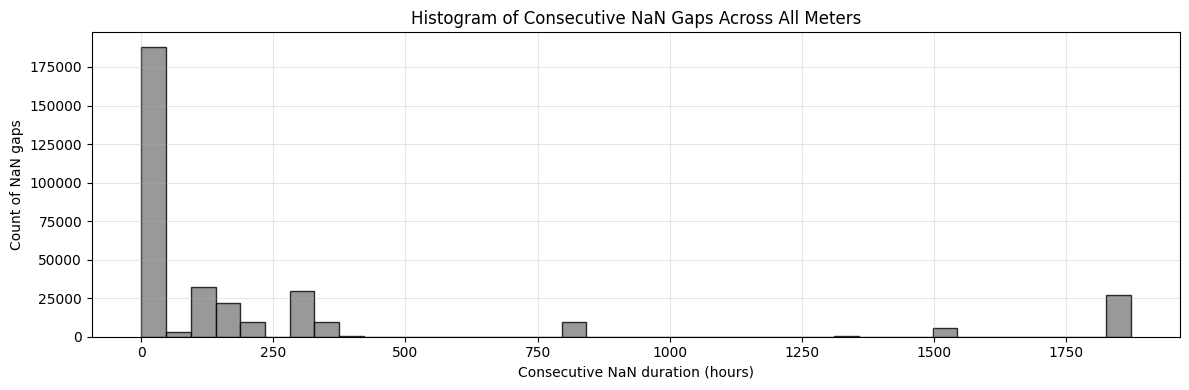

Total NaN gaps plotted: 336605
Median gap length: 23.750000 hours
95th percentile gap length: 1851.75 hours
Max gap length: 6411.25 hours


In [72]:
def analyze_nan_blocks(file_path: str, verbose: bool = True):

    feature_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']

    # Read raw parquet
    df = pq.read_table(file_path).to_pandas()

    # Standardize names
    for col in df.columns:
        for base_feat in feature_cols:
            if col.startswith(base_feat):
                df.rename(columns={col: base_feat}, inplace=True)
                break

    # Validate feature columns explicitly so failures are informative
    missing_features = [c for c in feature_cols if c not in df.columns]
    if missing_features:
        raise ValueError(f"missing_phase_columns: {missing_features}")

    time_col = next((c for c in df.columns if c.lower() in ['timestamp_dst', 'timestamp', 'timestamp_utc']), None)
    if time_col is not None:
        parsed_time = pd.to_datetime(df[time_col], errors='coerce', utc=True)
    else:
        parsed_time = pd.to_datetime(df.index, errors='coerce', utc=True)

    if pd.isna(parsed_time).all():
        raise ValueError("invalid_or_missing_timestamp")

    df.index = parsed_time
    df = df[~df.index.isna()].sort_index()
    if df.empty:
        raise ValueError("empty_after_timestamp_parsing")

    # Create a boolean mask of rows where ANY phase is NaN
    is_nan = df[feature_cols].isna().any(axis=1)

    # Groups consecutive True values together and assigns a unique ID to each continuous block of NaNs
    nan_blocks = is_nan != is_nan.shift()
    block_ids = nan_blocks.cumsum()

    # Filter to only look at the blocks that are actually NaNs
    nan_only_blocks = block_ids[is_nan]
    meter_name = os.path.basename(file_path)

    if nan_only_blocks.empty:
        result = {
            'file': meter_name,
            'total_rows': len(df),
            'total_nan_rows': 0,
            'num_missing_periods': 0,
            'tiny_gaps': 0,
            'medium_gaps': 0,
            'large_gaps': 0,
            'max_gap_ticks': 0,
            'gap_lengths_ticks': []
        }

        if verbose:
            print(f"\nNAN GAP ANALYSIS FOR: {meter_name}")
            print("=" * 50)
            print("No NaNs found in this file.")
        return result

    # Count the size of each continuous NaN block
    block_sizes = nan_only_blocks.value_counts()
    gap_lengths_ticks = block_sizes.tolist()

    # Categorize the gaps
    tiny_gaps = block_sizes[block_sizes <= 4].count()      # <= 1 hour
    medium_gaps = block_sizes[(block_sizes > 4) & (block_sizes <= 96)].count() # 1 hour to 1 day
    large_gaps = block_sizes[block_sizes > 96].count()     # > 1 day

    result = {
        'file': meter_name,
        'total_rows': len(df),
        'total_nan_rows': int(len(nan_only_blocks)),
        'num_missing_periods': int(len(block_sizes)),
        'tiny_gaps': int(tiny_gaps),
        'medium_gaps': int(medium_gaps),
        'large_gaps': int(large_gaps),
        'max_gap_ticks': int(block_sizes.max()),
        'gap_lengths_ticks': gap_lengths_ticks
    }

    if verbose:
        print(f"\n")
        print(f"=" * 50)
        print(f"NAN GAP ANALYSIS FOR: {meter_name}")
        print("=" * 50)
        print(f"Total NaN rows: {result['total_nan_rows']}")
        print(f"Number of distinct missing periods: {result['num_missing_periods']} ({result['num_missing_periods']/len(df)*100:.2f}% of total rows)\n")
        print("Distribution of Gap Sizes (in 15-minute raw ticks):")
        print(f"  Tiny gaps (<= 1 hour):     {tiny_gaps} occurrences")
        print(f"  Medium gaps (1h to 1 day): {medium_gaps} occurrences")
        print(f"  Massive gaps (> 1 day):    {large_gaps} occurrences\n")

        if large_gaps > 0:
            print("Details of the Massive Gaps (> 1 day):")
            # Get the actual start and end dates for the massive gaps
            for block_id in block_sizes[block_sizes > 96].index:
                block_data = df[block_ids == block_id]
                start_time = block_data.index.min()
                end_time = block_data.index.max()
                duration = end_time - start_time
                print(f"  -> Offline from {start_time.strftime('%Y-%m-%d')} to {end_time.strftime('%Y-%m-%d')} (Duration: {duration})")

    return result


def analyze_nan_blocks_all(data_dir: str, verbose_each_file: bool = True):
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f"No parquet files found in {data_dir}")
        return pd.DataFrame(), [], pd.DataFrame()

    results = []
    all_gap_lengths_ticks = []
    failed_records = []
    success_count = 0
    fail_count = 0

    iterator = tqdm(parquet_files, desc='Analyzing NaN blocks', unit='file')

    for file_path in iterator:
        try:
            result = analyze_nan_blocks(file_path, verbose=verbose_each_file)
            results.append(result)
            all_gap_lengths_ticks.extend(result.get('gap_lengths_ticks', []))
            success_count += 1

        except Exception as exc:
            fail_count += 1
            reason = f"{type(exc).__name__}: {str(exc).strip()}"
            failed_records.append({
                'file': os.path.basename(file_path),
                'error_type': type(exc).__name__,
                'error_message': str(exc).strip(),
                'reason': reason,
            })

            if verbose_each_file:
                print(f"Failed for {os.path.basename(file_path)} -> {reason}")

        iterator.set_postfix({'ok': success_count, 'fail': fail_count})

    summary_df = pd.DataFrame(results)
    failed_df = pd.DataFrame(failed_records)

    if summary_df.empty:
        print("No valid analysis results produced.")
        if not failed_df.empty:
            print(f"Total failed files: {len(failed_df)}")
        return summary_df, all_gap_lengths_ticks, failed_df

    gap_hours = np.array(all_gap_lengths_ticks, dtype=float) * (15.0 / 60.0) if all_gap_lengths_ticks else np.array([])
    total_rows_sum = summary_df['total_rows'].sum()
    missing_periods_sum = summary_df['num_missing_periods'].sum()
    files_with_nans = int((summary_df['total_nan_rows'] > 0).sum())

    print("\n" + "=" * 70)
    print("COLLECTIVE SUMMARY ACROSS ALL PARQUET FILES")
    print("=" * 70)
    print(f"Files analyzed: {len(summary_df)}")
    print(f"Files failed: {len(failed_df)}")
    print(f"Total rows scanned: {int(total_rows_sum):,}")
    print(f"Total NaN rows: {int(summary_df['total_nan_rows'].sum()):,}, ({(summary_df['total_nan_rows'].sum()/total_rows_sum*100) if total_rows_sum > 0 else 0.0:.2f}%)")
    print(f"Total missing periods (NaN blocks): {int(missing_periods_sum):,}, ({(missing_periods_sum/total_rows_sum*100) if total_rows_sum > 0 else 0.0:.2f}%)")
    print(f"Total tiny gaps (<=1h): {int(summary_df['tiny_gaps'].sum()):,} ({(summary_df['tiny_gaps'].sum()/missing_periods_sum*100) if missing_periods_sum > 0 else 0.0:.2f}%)")
    print(f"Total medium gaps (1h-1d): {int(summary_df['medium_gaps'].sum()):,} ({(summary_df['medium_gaps'].sum()/missing_periods_sum*100) if missing_periods_sum > 0 else 0.0:.2f}%)")
    print(f"Total massive gaps (>1d): {int(summary_df['large_gaps'].sum()):,} ({(summary_df['large_gaps'].sum()/missing_periods_sum*100) if missing_periods_sum > 0 else 0.0:.2f}%)")
    print(f"Files with any NaNs: {files_with_nans:,}, ({(files_with_nans/len(summary_df)*100) if len(summary_df) > 0 else 0.0:.2f}%)")

    if gap_hours.size > 0:
        print("-" * 70)
        print(f"Gap duration stats (hours) — mean: {gap_hours.mean():.2f}, median: {np.median(gap_hours):.2f}, p95: {np.percentile(gap_hours, 95):.2f}, max: {gap_hours.max():.2f}")

    if not failed_df.empty:
        print("-" * 70)
        print("TOP FAILURE REASONS")
        print(failed_df['reason'].value_counts().head(10).to_string())
    print("=" * 70)

    return summary_df, all_gap_lengths_ticks, failed_df


def plot_nan_gap_histogram_hours(gap_lengths_ticks, tick_minutes: int = 15, max_hours: float = None):

    import matplotlib.pyplot as plt
    if not gap_lengths_ticks:
        print("No NaN gaps found across meters, histogram skipped.")
        return

    gap_hours = np.array(gap_lengths_ticks, dtype=float) * (tick_minutes / 60.0)

    if max_hours is None:
        max_hours = float(np.percentile(gap_hours, 99)) if len(gap_hours) > 1 else float(gap_hours.max())
        max_hours = max(max_hours, 1.0)

    clipped = np.clip(gap_hours, 0, max_hours)
    bins = 40

    plt.figure(figsize=(12, 4))
    plt.hist(clipped, bins=bins, edgecolor='black', alpha=0.8, color='gray')
    plt.title('Histogram of Consecutive NaN Gaps Across All Meters')
    plt.xlabel('Consecutive NaN duration (hours)')
    plt.ylabel('Count of NaN gaps')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Total NaN gaps plotted: {len(gap_hours)}")
    print(f"Median gap length: {np.median(gap_hours):2f} hours")
    print(f"95th percentile gap length: {np.percentile(gap_hours, 95):.2f} hours")
    print(f"Max gap length: {np.max(gap_hours):.2f} hours")


# data_dir = "F:/Data/processed_data/second_batch/individual_sm_datasets/raw_profiles"
# data_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
data_dir = "/Volumes/USB/raw_profiles"
nan_summary, all_gap_lengths_ticks, nan_failures = analyze_nan_blocks_all(data_dir, verbose_each_file=False)
plot_nan_gap_histogram_hours(all_gap_lengths_ticks, tick_minutes=15)
if not nan_failures.empty:
    display(nan_failures.head(20))

Analyzing NaN blocks: 100%|██████████| 61557/61557 [37:17<00:00, 27.51file/s, ok=61557, fail=0]  

======================================================================

COLLECTIVE SUMMARY ACROSS ALL PARQUET FILES

======================================================================

Files analyzed: 61557

Files failed: 0

Total rows scanned: 1,578,629,265

Total NaN rows: 359,591,890, (22.78%)

Total missing periods (NaN blocks): 336,605, (0.02%)

Total tiny gaps (<=1h): 53,624 (15.93%)

Total medium gaps (1h-1d): 130,654 (38.82%)

Total massive gaps (>1d): 152,327 (45.25%)

Files with any NaNs: 61,557, (100.00%)

----------------------------------------------------------------------

Gap duration stats (hours) — mean: 267.07, median: 23.75, p95: 1851.75, max: 6411.25

======================================================================

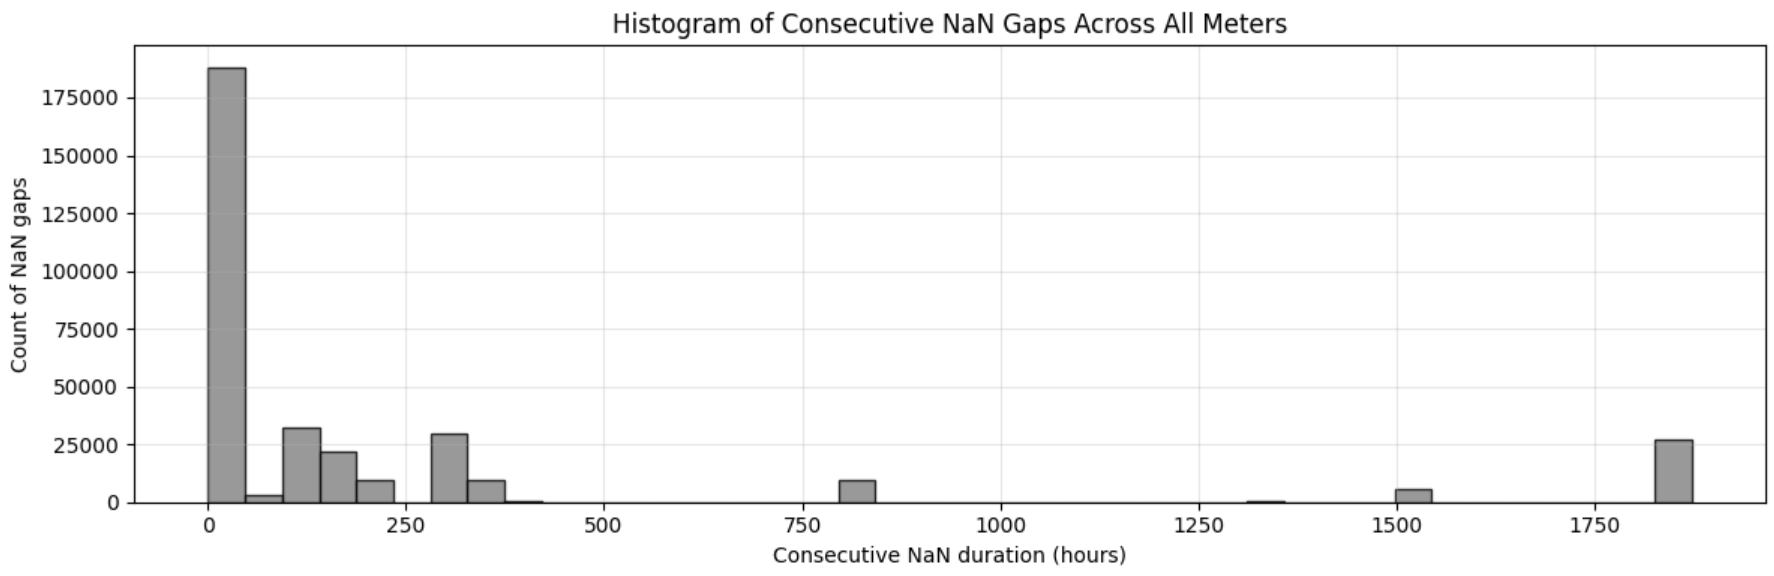

### Does NaNs on Parquet data correspond to NaNs on csv 
<span style="color:red"> cannot do this without csv data </span>

In [24]:
import time

def _pick_col(existing_cols, candidates):
    for c in candidates:
        if c in existing_cols:
            return c
    return None

def _largest_gap_for_raw_profile(parquet_path: str, meter_id: int):
    result = {
        "meter_id": int(meter_id),
        "file": os.path.basename(parquet_path),
        "status": "unknown",
        "largest_gap_hours": np.nan,
        "gap_start": pd.NaT,
        "gap_end": pd.NaT,
    }
    try:
        df_p = pd.read_parquet(parquet_path)

        tcol = next((c for c in df_p.columns if "time" in c.lower() or "date" in c.lower()), None)
        df_p.index = pd.to_datetime(df_p[tcol] if tcol else df_p.index, errors="coerce", utc=True)
        df_p = df_p.sort_index()

        phase_cols = [c for c in df_p.columns if c.startswith("active_power_p14_l")]
        if not phase_cols:
            result["status"] = "error_missing_phase_cols"
            return result

        is_missing = df_p[phase_cols].isna().all(axis=1)
        if not is_missing.any():
            result["status"] = "no_missing_gap"
            return result

        gap_blocks = (is_missing != is_missing.shift()).cumsum()
        missing_blocks = gap_blocks[is_missing]
        largest_block_id = missing_blocks.value_counts().idxmax()
        largest_gap_data = df_p[gap_blocks == largest_block_id]

        gap_start = largest_gap_data.index.min()
        gap_end = largest_gap_data.index.max()
        gap_duration_h = (gap_end - gap_start).total_seconds() / 3600.0

        result["largest_gap_hours"] = float(gap_duration_h)
        result["gap_start"] = gap_start
        result["gap_end"] = gap_end
        result["status"] = "gap_found"
        return result
    except Exception:
        result["status"] = "error_exception"
        return result

def _collect_gap_queries(parquet_dir: str):
    parquet_files = sorted(glob.glob(os.path.join(parquet_dir, "*.parquet")))
    if not parquet_files:
        return pd.DataFrame()

    rows = []
    iterator = tqdm(parquet_files, desc="1/2 Build gap queries", unit="file")
    for file_path in iterator:
        basename = os.path.basename(file_path)
        meter_id = None
        if basename.startswith("sm_") and basename.endswith(".parquet"):
            try:
                meter_id = int(basename.split("_")[1].split(".")[0])
            except Exception:
                meter_id = None
        if meter_id is None:
            continue

        rows.append(_largest_gap_for_raw_profile(file_path, meter_id))

    out = pd.DataFrame(rows)
    return out

def _scan_hourly_once_against_queries(hourly_parquet_dir: str, queries_df: pd.DataFrame, batch_size: int = 300_000, mismatch_energy_epsilon_kwh: float = 0.01):
    """Single-pass scan across hourly parquet files for all meter gap windows."""
    if queries_df.empty:
        return {}

    hourly_files = sorted(glob.glob(os.path.join(hourly_parquet_dir, "*.parquet")))
    if not hourly_files:
        return {}

    meter_candidates = ["meter_number", "meter_id", "smart_meter_id", "sm_id"]
    time_candidates = ["timestamp_utc", "timestamp_dst", "timestamp", "datetime", "time"]
    energy_candidates = ["hourly_energy_consumption", "energy_kwh", "kwh", "agg_wh"]

    active = queries_df[queries_df["status"] == "gap_found"].copy()
    if active.empty:
        return {}

    # One gap window per meter in this dataset
    meter_to_window = {}
    for _, r in active.iterrows():
        meter_to_window[int(r["meter_id"])] = (pd.Timestamp(r["gap_start"]), pd.Timestamp(r["gap_end"]))

    meter_set = set(meter_to_window.keys())
    acc = {m: {"rows": 0, "sum_kwh": 0.0, "nonzero_rows": 0, "nonzero_sum_kwh": 0.0} for m in meter_set}

    file_iter = tqdm(hourly_files, desc="2/2 Scan hourly parquet once", unit="file")
    for fpath in file_iter:
        pf = pq.ParquetFile(fpath)
        schema_cols = pf.schema.names

        req_cols = []
        for c in meter_candidates + time_candidates + energy_candidates:
            if c in schema_cols and c not in req_cols:
                req_cols.append(c)
        if not req_cols:
            continue

        for batch in pf.iter_batches(columns=req_cols, batch_size=batch_size):
            b = batch.to_pandas()
            cols = list(b.columns)

            meter_col = _pick_col(cols, meter_candidates)
            time_col = _pick_col(cols, time_candidates)
            energy_col = _pick_col(cols, energy_candidates)

            if meter_col is None or time_col is None:
                b = b.reset_index()
                cols = list(b.columns)
                meter_col = _pick_col(cols, meter_candidates)
                time_col = _pick_col(cols, time_candidates)
                if energy_col is None:
                    energy_col = _pick_col(cols, energy_candidates)

            if meter_col is None or time_col is None or energy_col is None:
                continue

            w = pd.DataFrame({
                "meter_id": pd.to_numeric(b[meter_col], errors="coerce"),
                "timestamp": pd.to_datetime(b[time_col], errors="coerce", utc=True),
                "energy": pd.to_numeric(b[energy_col], errors="coerce"),
            }).dropna(subset=["meter_id", "timestamp", "energy"])
            if w.empty:
                continue

            w["meter_id"] = w["meter_id"].astype(int)
            w = w[w["meter_id"].isin(meter_set)]
            if w.empty:
                continue

            if energy_col == "agg_wh":
                w["energy_kwh"] = w["energy"] / 1000.0
            else:
                w["energy_kwh"] = w["energy"]

            # Check each meter's rows only against its own window
            for m, g in w.groupby("meter_id"):
                gs, ge = meter_to_window.get(int(m), (None, None))
                if gs is None:
                    continue
                in_gap = g[(g["timestamp"] >= gs) & (g["timestamp"] <= ge)]
                if in_gap.empty:
                    continue
                acc[int(m)]["rows"] += int(len(in_gap))
                acc[int(m)]["sum_kwh"] += float(in_gap["energy_kwh"].sum())
                # Treat tiny values as effectively zero to avoid false mismatches
                in_gap_nz = in_gap[in_gap["energy_kwh"].abs() > mismatch_energy_epsilon_kwh]
                if not in_gap_nz.empty:
                    acc[int(m)]["nonzero_rows"] += int(len(in_gap_nz))
                    acc[int(m)]["nonzero_sum_kwh"] += float(in_gap_nz["energy_kwh"].sum())

    return acc

def verify_gap_consistency_all(hourly_parquet_dir: str, parquet_dir: str, batch_size: int = 300_000, mismatch_energy_epsilon_kwh: float = 0.01, gap_alignment_tolerance_hours: float = 1.0):
    t0 = time.time()
    queries_df = _collect_gap_queries(parquet_dir)
    if queries_df.empty:
        print(f"No raw-profile parquet files found in {parquet_dir}")
        return pd.DataFrame()

    acc = _scan_hourly_once_against_queries(
        hourly_parquet_dir,
        queries_df,
        batch_size=batch_size,
        mismatch_energy_epsilon_kwh=mismatch_energy_epsilon_kwh,
    )

    summary_df = queries_df.copy()
    summary_df["hourly_rows_in_gap"] = 0
    summary_df["hourly_mean_in_gap"] = np.nan
    summary_df["hourly_nonzero_rows_in_gap"] = 0
    summary_df["hourly_nonzero_mean_in_gap"] = np.nan
    summary_df["gap_alignment_diff_hours"] = np.nan
    summary_df["gap_row_aligned"] = False

    for i, row in summary_df.iterrows():
        if row["status"] != "gap_found":
            continue
        m = int(row["meter_id"])
        rec = acc.get(m, {"rows": 0, "sum_kwh": 0.0, "nonzero_rows": 0, "nonzero_sum_kwh": 0.0})
        n = int(rec["rows"])
        s = float(rec["sum_kwh"])
        nnz = int(rec["nonzero_rows"])
        snz = float(rec["nonzero_sum_kwh"])
        summary_df.at[i, "hourly_rows_in_gap"] = n
        summary_df.at[i, "hourly_mean_in_gap"] = (s / n) if n > 0 else np.nan
        summary_df.at[i, "hourly_nonzero_rows_in_gap"] = nnz
        summary_df.at[i, "hourly_nonzero_mean_in_gap"] = (snz / nnz) if nnz > 0 else np.nan
        if pd.notna(row.get("largest_gap_hours", np.nan)):
            align_diff = abs(float(row["largest_gap_hours"]) - float(n))
            aligned = align_diff <= float(gap_alignment_tolerance_hours)
        else:
            align_diff = np.nan
            aligned = False
        summary_df.at[i, "gap_alignment_diff_hours"] = align_diff
        summary_df.at[i, "gap_row_aligned"] = bool(aligned)
        if n == 0:
            summary_df.at[i, "status"] = "consistent_offline"
        elif nnz == 0:
            summary_df.at[i, "status"] = "consistent_zero_only_aligned" if aligned else "consistent_zero_only"
        else:
            summary_df.at[i, "status"] = "mismatch_data_exists"

    print("\n" + "=" * 70)
    print("COLLECTIVE 1-PHASE HOURLY PARQUET vs RAW-PROFILE GAP CONSISTENCY SUMMARY")
    print("=" * 70)
    print(f"Files analyzed: {len(summary_df)}")
    print(f"Consistent offline gaps: {(summary_df['status'] == 'consistent_offline').sum()}")
    print(f"Consistent zero-only aligned gaps (|kWh| <= {mismatch_energy_epsilon_kwh}, |gap_hours - rows| <= {gap_alignment_tolerance_hours}h): {(summary_df['status'] == 'consistent_zero_only_aligned').sum()}")
    print(f"Consistent zero-only non-aligned gaps: {(summary_df['status'] == 'consistent_zero_only').sum()}")
    print(f"Mismatches (data exists in hourly parquet during raw-profile gap): {(summary_df['status'] == 'mismatch_data_exists').sum()}")
    print(f"No missing gap in raw-profile parquet: {(summary_df['status'] == 'no_missing_gap').sum()}")
    print(f"Errors: {(summary_df['status'].astype(str).str.startswith('error')).sum()}")

    valid_gap = summary_df['largest_gap_hours'].dropna()
    if not valid_gap.empty:
        print("-" * 70)
        print(f"Largest-gap stats (hours) — mean: {valid_gap.mean():.2f}, median: {valid_gap.median():.2f}, max: {valid_gap.max():.2f}")

    mismatch_df = summary_df[summary_df['status'] == 'mismatch_data_exists']
    if not mismatch_df.empty:
        print("-" * 70)
        print("Meters with detected mismatch:")
        display(
            mismatch_df[['meter_id', 'file', 'largest_gap_hours', 'hourly_rows_in_gap', 'hourly_nonzero_rows_in_gap', 'hourly_nonzero_mean_in_gap', 'hourly_mean_in_gap']]
            .sort_values('hourly_rows_in_gap', ascending=False)
        )

    return summary_df

# Compare 3-phase raw-profile parquet gaps against ALL 1-phase hourly parquet files (efficient single-pass hourly scan)
hourly_parquet_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/parq_hourly"
parquet_dir = "/Volumes/USB/raw_profiles"
gap_consistency_summary = verify_gap_consistency_all(hourly_parquet_dir, parquet_dir, batch_size=300_000, mismatch_energy_epsilon_kwh=0.01, gap_alignment_tolerance_hours=1.0)

2/2 Scan hourly parquet once: 100%|██████████| 12/12 [05:52<00:00, 29.34s/file]



COLLECTIVE 1-PHASE HOURLY PARQUET vs RAW-PROFILE GAP CONSISTENCY SUMMARY
Files analyzed: 61557
Consistent offline gaps: 4
Consistent zero-only aligned gaps (|kWh| <= 0.01, |gap_hours - rows| <= 1.0h): 463
Consistent zero-only non-aligned gaps: 593
Mismatches (data exists in hourly parquet during raw-profile gap): 60497
No missing gap in raw-profile parquet: 0
Errors: 0
----------------------------------------------------------------------
Largest-gap stats (hours) — mean: 1178.65, median: 1513.00, max: 5699.75
----------------------------------------------------------------------
Meters with detected mismatch:


,meter_id,file,largest_gap_hours,hourly_rows_in_gap,hourly_nonzero_rows_in_gap,hourly_nonzero_mean_in_gap,hourly_mean_in_gap
14146,305656,sm_305656.parquet,5699.75,4547,9,0.100000,0.000198
29790,534300,sm_534300.parquet,5699.75,4379,4377,0.729758,0.729425
24274,45484,sm_45484.parquet,5699.75,4163,4,0.130000,0.000127
31096,552863,sm_552863.parquet,5699.75,4163,4163,4.873259,4.873259
18535,370923,sm_370923.parquet,5699.75,3179,3144,0.754329,0.746134
...,...,...,...,...,...,...,...
12183,277205,sm_277205.parquet,143.75,144,144,0.082778,0.082778
42819,724570,sm_724570.parquet,143.75,144,144,1.110972,1.110972
29509,530392,sm_530392.parquet,143.75,144,144,0.082361,0.082361
41367,703900,sm_703900.parquet,143.75,144,80,0.245375,0.139583


### Compare csv and parquet data 

In [ ]:
def investigate_single_meter(csv_path: str, parquet_path: str, meter_id: int, out_path: str = None, verbose: bool = True, make_plot: bool = True):
    if verbose:
        print(f"\n")
        print(f"{'='*50}\nCOMPARING FILE CONSISTENCY FOR METER {meter_id}\n{'='*50}")

    result = {
        'meter_id': int(meter_id),
        'file': os.path.basename(parquet_path),
        'status': 'unknown',
        'parquet_valid_rows': 0,
        'csv_valid_rows': 0,
        'overlap_hours': np.nan,
        'parquet_max_kwh': np.nan,
        'csv_max_kwh': np.nan,
        'mean_abs_diff_kwh': np.nan
    }

    try:
        # ==========================================
        # 1. LOAD PARQUET
        # ==========================================
        if verbose:
            print(f"Loading Parquet: {parquet_path}")
        df_p = pd.read_parquet(parquet_path)
        
        tcol = next((c for c in df_p.columns if "time" in c.lower() or "date" in c.lower()), None)
        if tcol:
            df_p.index = pd.to_datetime(df_p[tcol], errors="coerce", utc=True)
        else:
            df_p.index = pd.to_datetime(df_p.index, errors="coerce", utc=True)
        
        phase_cols = [c for c in df_p.columns if c.startswith('active_power_p14_l')]
        if len(phase_cols) >= 1:
            df_phases = df_p[phase_cols].apply(pd.to_numeric, errors="coerce")
            df_p["Aggregated"] = df_phases.sum(axis=1, min_count=1)
        else:
            df_p["Aggregated"] = np.nan
    
        df_p_valid = df_p.dropna(subset=["Aggregated"]).sort_index()
        result['parquet_valid_rows'] = int(len(df_p_valid))
        
        if verbose:
            print(f"  -> Raw Parquet Rows:   {len(df_p)}")
            print(f"  -> Valid Parquet Rows: {len(df_p_valid)} (Non-NaN)")
            if not df_p_valid.empty:
                print(f"  -> Parquet Date Range: {df_p_valid.index.min().date()} to {df_p_valid.index.max().date()}")

        # ==========================================
        # 2. LOAD CSV
        # ==========================================
        if verbose:
            print(f"\nScanning CSV for Meter {meter_id}...")
        csv_chunks = []
        
        sample = pd.read_csv(csv_path, nrows=5)
        meter_col = next(c for c in sample.columns if 'meter' in c.lower() or 'id' in c.lower())
        time_col = next(c for c in sample.columns if 'time' in c.lower() or 'date' in c.lower())
        energy_col = next(c for c in sample.columns if 'energy' in c.lower() or 'kwh' in c.lower())
        
        for chunk in pd.read_csv(csv_path, chunksize=500_000, low_memory=False):
            chunk[meter_col] = pd.to_numeric(chunk[meter_col], errors="coerce")
            match = chunk[chunk[meter_col] == meter_id]
            if not match.empty:
                csv_chunks.append(match[[time_col, energy_col]])

        if not csv_chunks:
            if verbose:
                print(f"\nERROR: Meter {meter_id} not found in CSV!")
            result['status'] = 'error_meter_not_in_csv'
            return result

        df_c = pd.concat(csv_chunks, ignore_index=True)
        df_c.index = pd.to_datetime(df_c[time_col], errors="coerce", utc=True)
        df_c = df_c.dropna(subset=[energy_col]).sort_index()
        result['csv_valid_rows'] = int(len(df_c))
        
        if verbose:
            print(f"  -> Valid CSV Rows:     {len(df_c)}")
            print(f"  -> CSV Date Range:     {df_c.index.min().date()} to {df_c.index.max().date()}")

        # ==========================================
        # 3. ALIGN AND COMPARE
        # ==========================================
        if df_p_valid.empty:
            if verbose:
                print("\nERROR: Parquet data has 0 valid rows. The columns are entirely NaN or empty. Cannot compare.")
            result['status'] = 'error_no_valid_parquet'
            return result

        start_date = max(df_p_valid.index.min(), df_c.index.min())
        end_date = min(df_p_valid.index.max(), df_c.index.max())
        
        if start_date >= end_date:
            if verbose:
                print(f"\nERROR: Time ranges do not overlap!\nParquet: {df_p_valid.index.min().date()}->{df_p_valid.index.max().date()}\nCSV: {df_c.index.min().date()}->{df_c.index.max().date()}")
            result['status'] = 'error_no_overlap'
            return result
        
        overlap_hours = (end_date - start_date).total_seconds() / 3600.0
        result['overlap_hours'] = float(overlap_hours)
        
        if verbose:
            print(f"\nPlotting overlapping window: {start_date.date()} to {end_date.date()}")
        
        p_plot = df_p_valid[(df_p_valid.index >= start_date) & (df_p_valid.index <= end_date)]
        c_plot = df_c[(df_c.index >= start_date) & (df_c.index <= end_date)]
        
        p_hourly = p_plot.resample('1h').mean().dropna(subset=["Aggregated"])
        p_vals = p_hourly["Aggregated"].values / 1000.0
        c_vals = c_plot[energy_col].values
        
        if len(p_vals) == 0 or len(c_vals) == 0:
            result['status'] = 'error_empty_aligned_values'
            return result

        result['parquet_max_kwh'] = float(np.nanmax(p_vals))
        result['csv_max_kwh'] = float(np.nanmax(c_vals))
        
        # Simple aligned diff by timestamp intersection
        p_series = pd.Series(p_vals, index=p_hourly.index).sort_index()
        c_series = pd.Series(c_vals, index=c_plot.index).sort_index()
        joined = pd.concat([p_series.rename('p'), c_series.rename('c')], axis=1, join='inner').dropna()
        if not joined.empty:
            result['mean_abs_diff_kwh'] = float((joined['p'] - joined['c']).abs().mean())

        if verbose:
            print(f"  -> Max Parquet value (scaled): {result['parquet_max_kwh']:.4f} kWh")
            print(f"  -> Max CSV value: {result['csv_max_kwh']:.4f} kWh")
            if not np.isnan(result['mean_abs_diff_kwh']):
                print(f"  -> Mean absolute diff on overlap: {result['mean_abs_diff_kwh']:.4f} kWh")

        if make_plot:
            fig, ax = plt.subplots(figsize=(16, 6))
            ax.plot(p_hourly.index, p_vals, label="Parquet 3-Phase (Hourly Avg)", linewidth=2, marker='o', markersize=3, alpha=0.8)
            ax.plot(c_plot.index, c_vals, label="CSV Hourly", linestyle='--', linewidth=2, marker='x', markersize=4, alpha=0.8)

            ax.set_xlim([start_date, end_date])
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
            plt.xticks(rotation=45)
            plt.title(f"Meter {meter_id} - Full Overlap Range")
            plt.ylabel("Energy (kWh)")
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.tight_layout()

            if out_path:
                plt.savefig(out_path, dpi=150)
                if verbose:
                    print(f"Plot saved to: {out_path}")
            plt.show()

        result['status'] = 'ok'
        return result

    except Exception as exc:
        if verbose:
            print(f"ERROR while processing meter {meter_id}: {exc}")
        result['status'] = 'error_exception'
        return result


def investigate_all_meters(csv_path: str, parquet_dir: str, make_plot_each: bool = True, verbose_each_file: bool = True):
    parquet_files = sorted(glob.glob(os.path.join(parquet_dir, '*.parquet')))
    if not parquet_files:
        print(f"No parquet files found in {parquet_dir}")
        return pd.DataFrame()

    results = []
    success_count = 0
    fail_count = 0
    iterator = tqdm(parquet_files, desc='CSV-parquet comparison', unit='file')
    for file_path in iterator:
        meter_id = int(os.path.basename(file_path).split('_')[1].split('.')[0])
        result = investigate_single_meter(
                csv_path=csv_path,
                parquet_path=file_path,
                meter_id=meter_id,
                out_path=None,
                verbose=verbose_each_file,
                make_plot=make_plot_each
            )
        results.append(result)
        if result.get('status') == 'ok':
            success_count += 1
        else:
            fail_count += 1
        iterator.set_postfix({'ok': success_count, 'fail': fail_count})

    summary_df = pd.DataFrame(results)
    if summary_df.empty:
        print("No results to summarize.")
        return summary_df

    print("\n" + "=" * 70)
    print("COLLECTIVE CSV vs PARQUET COMPARISON SUMMARY")
    print("=" * 70)
    print(f"Files analyzed: {len(summary_df)}")
    print(f"Successful comparisons: {(summary_df['status'] == 'ok').sum()}")
    print(f"Errors/no-overlap: {(summary_df['status'] != 'ok').sum()}")

    ok_df = summary_df[summary_df['status'] == 'ok']
    if not ok_df.empty:
        print("-" * 70)
        print(f"Avg overlap length (hours): {ok_df['overlap_hours'].mean():.2f}")
        print(f"Avg parquet max (kWh): {ok_df['parquet_max_kwh'].mean():.4f}")
        print(f"Avg csv max (kWh): {ok_df['csv_max_kwh'].mean():.4f}")
        mad = ok_df['mean_abs_diff_kwh'].dropna()
        if not mad.empty:
            print(f"Mean absolute difference (kWh) — mean: {mad.mean():.4f}, median: {mad.median():.4f}, max: {mad.max():.4f}")

    error_df = summary_df[summary_df['status'] != 'ok']
    if not error_df.empty:
        print("-" * 70)
        print("Files with errors:")
        display(error_df[['meter_id', 'file', 'status']])
    print("=" * 70)

    return summary_df


# METER_ID = 393221
# CSV_FILE = "data/hourly_measurements_2023_11.csv"
# PARQUET_FILE = f"F:/Data/processed_data/second_batch/individual_sm_datasets/raw_profiles/sm_{METER_ID}.parquet"
# investigate_single_meter(CSV_FILE, PARQUET_FILE, METER_ID, f"output/debug_meter_{METER_ID}.png")

csv_file = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/hourly_measurements_2023_10.csv"
# parquet_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
parquet_dir = "/Volumes/USB/raw_profiles"
comparison_summary = investigate_all_meters(csv_file, parquet_dir, make_plot_each=True, verbose_each_file=False)



COMPARING FILE CONSISTENCY FOR METER 116
Loading Parquet: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles/sm_116.parquet
  -> Raw Parquet Rows:   25645
  -> Valid Parquet Rows: 18392 (Non-NaN)
  -> Parquet Date Range: 2023-11-06 to 2024-05-15

Scanning CSV for Meter 116...

ERROR: Meter 116 not found in CSV!


COMPARING FILE CONSISTENCY FOR METER 146
Loading Parquet: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles/sm_146.parquet
  -> Raw Parquet Rows:   25645
  -> Valid Parquet Rows: 21435 (Non-NaN)
  -> Parquet Date Range: 2023-09-18 to 2024-05-15

Scanning CSV for Meter 146...

ERROR: Meter 146 not found in CSV!


COMPARING FILE CONSISTENCY FOR METER 17
Loading Parquet: /Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles/sm_17.parquet
  -> Raw Parquet Rows:   25645
  -> Valid Parquet Rows: 18392 (Non-NaN)
  -> Parquet Date Range: 2023-11-06 to 2024-05-15

Scanning CSV

,meter_id,file,status
0,116,sm_116.parquet,error_meter_not_in_csv
1,146,sm_146.parquet,error_meter_not_in_csv
2,17,sm_17.parquet,error_meter_not_in_csv
3,170,sm_170.parquet,error_meter_not_in_csv
4,40,sm_40.parquet,error_meter_not_in_csv
5,87,sm_87.parquet,error_meter_not_in_csv


## Conditions analysis 

### Load data

In [12]:
def load_data(file_path: str):
    
    # columns 
    feature_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    time_col_candidates = ['timestamp_dst', 'timestamp', 'timestamp_utc']
        
    # read Parquet data
    parquet_file = pq.ParquetFile(file_path)
    file_cols = parquet_file.schema.names
    cols_to_load = []
    rename_map = {}
    for base_feat in feature_cols:
        matched_col = next((c for c in file_cols if c.startswith(base_feat)), None)
        if matched_col:
            cols_to_load.append(matched_col)
            rename_map[matched_col] = base_feat
    
    time_col_name = next((c for c in file_cols if c.lower() in time_col_candidates), None)
    if time_col_name and time_col_name not in cols_to_load:
        cols_to_load.append(time_col_name)
        
    if not cols_to_load:
        return 0, 0, 0, 0, 0
        
    df = pq.read_table(file_path, columns=cols_to_load).to_pandas()
    df = df.rename(columns=rename_map)

    # time index prep
    time_values = df[time_col_name] if time_col_name in df.columns else df.index
    df.index = pd.to_datetime(time_values, errors='coerce', utc=True)
    df = df[~df.index.isna() & ~df.index.duplicated(keep='last')].sort_index()
    if df.empty:
        return 0, 0, 0, 0, 0

    return df

# data_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
data_dir = "/Volumes/USB/raw_profiles"
df = load_data(os.path.join(data_dir, "sm_17.parquet"))
print(df.head())

                           active_power_p14_l1  active_power_p14_l2  \
timestamp_dst                                                         
2023-09-04 08:45:00+00:00                 <NA>                 <NA>   
2023-09-04 09:00:00+00:00                 <NA>                 <NA>   
2023-09-04 09:15:00+00:00                 <NA>                 <NA>   
2023-09-04 09:30:00+00:00                 <NA>                 <NA>   
2023-09-04 09:45:00+00:00                 <NA>                 <NA>   

                           active_power_p14_l3  
timestamp_dst                                   
2023-09-04 08:45:00+00:00                 <NA>  
2023-09-04 09:00:00+00:00                 <NA>  
2023-09-04 09:15:00+00:00                 <NA>  
2023-09-04 09:30:00+00:00                 <NA>  
2023-09-04 09:45:00+00:00                 <NA>  


### How many meters have 1, 2, or 3 phased EV? 

In [13]:
evs = pd.read_csv("/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/EV/EV_detection_reduced_60000_SM.csv")

phase_labels = {
    "No EV": "No EV",
    "1ph": "EV on 1 phase",
    "2ph": "EV on 2 phases",
    "3ph": "EV on 3 phases",
}

phase_share = (
    evs["Type"]
    .fillna("No EV")
    .map(phase_labels)
    .value_counts(normalize=True)
    .reindex(["No EV", "EV on 1 phase", "EV on 2 phases", "EV on 3 phases"], fill_value=0)
    .mul(100)
)

print(phase_share.round(2).to_string())

Type
No EV             70.46
EV on 1 phase     19.39
EV on 2 phases     1.51
EV on 3 phases     8.64


### How many meters have 1, 2, or 3 phased HP? 

In [16]:
hp_predictions = pd.read_csv("/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/HP/label_propagation_predictions.csv")

hp_predictions["meter_id"] = hp_predictions.iloc[:, 0].str.split("_").str[1]
hp_predictions["phase"] = hp_predictions.iloc[:, 0].str.split("_").str[0]

phase_counts = (
    hp_predictions.assign(active=hp_predictions["predicted_hp"].astype(bool))
    .groupby("meter_id")["active"]
    .sum()
    .astype(int)
)

hp_share = (
    phase_counts.map({
        0: "No HP",
        1: "HP on 1 phase",
        2: "HP on 2 phases",
        3: "HP on 3 phases"
    })
    .value_counts(normalize=True)
    .reindex(["No HP", "HP on 1 phase", "HP on 2 phases", "HP on 3 phases"], fill_value=0)
    .mul(100)
)

print(hp_share.round(2).to_string())

active
No HP             45.32
HP on 1 phase     28.02
HP on 2 phases    15.18
HP on 3 phases    11.47


use hp conditioner 

In [ ]:
from conditioner import HeatpumpConditioner

def count_active_phases_in_meter(df: pd.DataFrame) -> int:
    phase_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    active_count = 0
    for col in phase_cols:
        if col in df.columns and df[col].notna().any() and (df[col].fillna(0.0) != 0.0).any():
            active_count += 1
    return active_count

def _to_binary_hp(series: pd.Series) -> pd.Series:
    lowered = series.astype(str).str.strip().str.lower()
    return lowered.isin({'true', '1', 'yes', 'y', 't'}).astype(float)


def build_hp_lookup_from_label_file(hp_label_path: str) -> dict[int, float]:

    label_df = pd.read_csv(hp_label_path)
    lower_map = {c.lower(): c for c in label_df.columns}
    meter_col = None
    hp_col = None

    for candidate in ['meter_number', 'meter_id', 'meter', 'id']:
        if candidate in lower_map:
            meter_col = lower_map[candidate]
            break

    for candidate in ['has_heat_pump', 'predicted_hp', 'heat_pump', 'is_hp', 'hp']:
        if candidate in lower_map:
            hp_col = lower_map[candidate]
            break

    if hp_col is None:
        raise ValueError('Could not find HP label column in hp_label_path file.')

    # If no explicit meter column exists, parse trailing digits from first/unnamed column (e.g. l1_100025)
    if meter_col is None:
        unnamed_cols = [c for c in label_df.columns if str(c).lower().startswith('unnamed')]
        source_col = unnamed_cols[0] if unnamed_cols else label_df.columns[0]
        meter_vals = pd.to_numeric(label_df[source_col].astype(str).str.extract(r'(\d+)$')[0], errors='coerce')
    else:
        meter_vals = pd.to_numeric(label_df[meter_col], errors='coerce')

    hp_vals = _to_binary_hp(label_df[hp_col])
    tmp = pd.DataFrame({'meter_id': meter_vals, 'hp': hp_vals}).dropna(subset=['meter_id'])
    tmp['meter_id'] = tmp['meter_id'].astype(int)

    # Aggregate by meter (if any phase says True => meter is HP)
    grouped = tmp.groupby('meter_id', as_index=False)['hp'].max()
    return {int(r['meter_id']): float(r['hp']) for _, r in grouped.iterrows()}


def count_hp_meters_by_phase(
    data_dir: str,
    hp_label_path: str,
):

    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))

    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame()

    # Try HeatpumpConditioner first; if schema mismatches, fallback to local parser
    hp_lookup = None
    try:
        hp_conditioner = HeatpumpConditioner(topology_path=hp_label_path)
    except Exception:
        hp_conditioner = None
        hp_lookup = build_hp_lookup_from_label_file(hp_label_path)

    phase_counts = {1: 0, 2: 0, 3: 0}
    analyzed_hp_meters = 0
    skipped_non_hp = 0
    skipped_invalid = 0

    for file_path in tqdm(parquet_files, desc='Counting phased HP meters', unit='file'):
        file_name = os.path.basename(file_path)
        try:
            meter_id = int(file_name.split('_')[1].split('.')[0])
        except Exception:
            skipped_invalid += 1
            continue

        try:
            if hp_conditioner is not None:
                hp_flag = hp_conditioner.get_conditions(
                    x=None,
                    meter_id=np.array([meter_id]),
                    timestamps=None,
                ).squeeze().item()
            else:
                hp_flag = hp_lookup.get(meter_id, 0.0)

        except Exception:
            # If conditioner fails due schema mismatch, fallback to parsed lookup
            if hp_lookup is None:
                hp_lookup = build_hp_lookup_from_label_file(hp_label_path)
            hp_flag = hp_lookup.get(meter_id, 0.0)

        if hp_flag < 0.5:
            skipped_non_hp += 1
            continue

        df = load_data(file_path)

        if isinstance(df, int) or df is None or df.empty:
            skipped_invalid += 1
            continue

        n_active = count_active_phases_in_meter(df)
        if n_active in phase_counts:
            phase_counts[n_active] += 1
            analyzed_hp_meters += 1
        else:
            skipped_invalid += 1

    summary_df = pd.DataFrame({
        'active_phases': [1, 2, 3],
        'hp_meter_count': [phase_counts[1], phase_counts[2], phase_counts[3]],
    })

    total_hp = int(summary_df['hp_meter_count'].sum())
    summary_df['pct_of_hp_meters'] = (
        summary_df['hp_meter_count'] / total_hp * 100.0 if total_hp > 0 else 0.0
    )

    print('\n' + '=' * 70)
    print('PHASED HEATPUMP METER SUMMARY')
    print('=' * 70)
    print(f'Total parquet files: {len(parquet_files)}')
    print(f'HP meters analyzed: {analyzed_hp_meters}')
    print(f'Non-HP meters skipped: {skipped_non_hp}')
    print(f'Invalid/empty/skipped files: {skipped_invalid}')
    print('=' * 70)
    display(summary_df)
    return summary_df

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
hp_label_path = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/label_propagation_predictions.csv'
data_dir = '/Volumes/USB/raw_profiles'
hp_phase_summary = count_hp_meters_by_phase(
    data_dir=data_dir,
    hp_label_path=hp_label_path,
)

Counting phased HP meters: 100%|██████████| 61557/61557 [14:40<00:00, 69.91file/s]  

======================================================================

PHASED HEATPUMP METER SUMMARY

======================================================================

Total parquet files: 61557

HP meters analyzed: 33452

Non-HP meters skipped: 28105

Invalid/empty/skipped files: 0

======================================================================

active_phases	hp_meter_count	pct_of_hp_meters

0	1	158	0.472319

1	2	1019	3.046156

2	3	32275	96.481526

### How many meters have 1, 2, or 3 active phases?

In [ ]:
def count_active_phases(df):
    phase_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    
    active_count = 0
    for col in phase_cols:
        if col in df.columns:
            # active if at least one valid non-zero value exists
            if df[col].notna().any() and (df[col].fillna(0) != 0).any():
                active_count += 1
                
    return active_count


# data_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
data_dir = "/Volumes/USB/raw_profiles"

phase_counts = {1: 0, 2: 0, 3: 0}
total_meters = 0

for file in os.listdir(data_dir):
    if not file.endswith(".parquet"):
        continue
        
    df = load_data(os.path.join(data_dir, file))
    
    if isinstance(df, int) or df.empty:
        continue
    
    n_active = count_active_phases(df)
    
    if n_active in phase_counts:
        phase_counts[n_active] += 1
    
    total_meters += 1

print("Total meters:", total_meters)

for k in [1, 2, 3]:
    count = phase_counts[k]
    pct = (count / total_meters) * 100 if total_meters > 0 else 0
    print(f"{k} phase(s): {count} meters ({pct:.2f}%)")

Total meters: 61557
1 phase(s): 1046 meters (1.70%)
2 phase(s): 2899 meters (4.71%)
3 phase(s): 57242 meters (92.99%)

### How many meters have PVs? 

use topology data

In [ ]:

def _to_binary_flag(series: pd.Series) -> pd.Series:
    lowered = series.astype(str).str.strip().str.lower()
    return lowered.isin({'true', '1', 'yes', 'y', 't'}).astype(int)

def count_pv_meters(topology_dir: str, data_dir: str | None = None):

    topology_path = os.path.join(topology_dir, 'MeterAndCabinet.csv')

    if not os.path.exists(topology_path):
        print(f'Missing topology file: {topology_path}')
        return pd.DataFrame()

    topo = pd.read_csv(topology_path)
    required = {'meter_number', 'has_solar_panel'}
    if not required.issubset(set(topo.columns)):
        print(f'Topology file must contain columns: {sorted(required)}')
        return pd.DataFrame()

    topo = topo[['meter_number', 'has_solar_panel']].copy()
    topo['meter_number'] = pd.to_numeric(topo['meter_number'], errors='coerce')
    topo = topo.dropna(subset=['meter_number'])
    topo['meter_number'] = topo['meter_number'].astype(int)
    topo['has_solar_panel_bin'] = _to_binary_flag(topo['has_solar_panel'])

    # Aggregate per meter in case of duplicates: any True => PV meter
    meter_pv = topo.groupby('meter_number', as_index=False)['has_solar_panel_bin'].max()
    total_topology_meters = int(len(meter_pv))
    pv_topology = int(meter_pv['has_solar_panel_bin'].sum())
    no_pv_topology = total_topology_meters - pv_topology

    print('\n' + '=' * 70)
    print('PV METER SUMMARY (TOPOLOGY)')
    print('=' * 70)
    print(f'Total meters in topology: {total_topology_meters:,}')
    print(f'Meters with PV: {pv_topology:,}')
    print(f'Meters without PV: {no_pv_topology:,}')
    print(f'PV share: {(pv_topology / total_topology_meters * 100.0) if total_topology_meters > 0 else 0.0:.2f}%')

    # Optional: overlap with parquet dataset meters

    if data_dir is not None:

        parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
        dataset_ids = []
        for fp in parquet_files:
            name = os.path.basename(fp)
            m = re.search(r'sm_(\d+)\.parquet$', name)
            if m:
                dataset_ids.append(int(m.group(1)))
        dataset_ids = sorted(set(dataset_ids))
        dataset_df = meter_pv[meter_pv['meter_number'].isin(dataset_ids)].copy()
        total_dataset_meters = int(len(dataset_df))
        pv_dataset = int(dataset_df['has_solar_panel_bin'].sum())
        no_pv_dataset = total_dataset_meters - pv_dataset

        print('-' * 70)
        print('PV SUMMARY FOR METERS PRESENT IN PARQUET DATASET')
        print('-' * 70)
        print(f'Meters matched to parquet set: {total_dataset_meters:,}')
        print(f'PV meters in parquet set: {pv_dataset:,}')
        print(f'Non-PV meters in parquet set: {no_pv_dataset:,}')
        print(f'PV share in parquet set: {(pv_dataset / total_dataset_meters * 100.0) if total_dataset_meters > 0 else 0.0:.2f}%')
        print('=' * 70)

        summary_df = pd.DataFrame([
            {'scope': 'topology_all', 'total_meters': total_topology_meters, 'pv_meters': pv_topology, 'non_pv_meters': no_pv_topology},
            {'scope': 'parquet_overlap', 'total_meters': total_dataset_meters, 'pv_meters': pv_dataset, 'non_pv_meters': no_pv_dataset},
        ])
    else:
        print('=' * 70)
        summary_df = pd.DataFrame([
            {'scope': 'topology_all', 'total_meters': total_topology_meters, 'pv_meters': pv_topology, 'non_pv_meters': no_pv_topology},
        ])

    summary_df['pv_pct'] = summary_df.apply(
        lambda r: (r['pv_meters'] / r['total_meters'] * 100.0) if r['total_meters'] > 0 else 0.0,
        axis=1,
    )
    display(summary_df)
    return summary_df


pv_data = '/Volumes/USB/topology/cleaned_and_corrected'
# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
pv_summary = count_pv_meters(topology_dir=pv_data, data_dir=data_dir)

=====================================================================

PV METER SUMMARY (TOPOLOGY)

======================================================================

Total meters in topology: 62,312

Meters with PV: 3,771

Meters without PV: 58,541


PV share: 6.05%

----------------------------------------------------------------------

PV SUMMARY FOR METERS PRESENT IN PARQUET DATASET

----------------------------------------------------------------------

Meters matched to parquet set: 61,557

PV meters in parquet set: 3,740

Non-PV meters in parquet set: 57,817

PV share in parquet set: 6.08%

======================================================================

scope	total_meters	pv_meters	non_pv_meters	pv_pct

0	topology_all	62312	3771	58541	6.051804

1	parquet_overlap	61557	3740	57817	6.075670

### How many windows are flagged as holiday? 

window = 24h 
use the holiday conditioner

In [57]:
from conditioner import HolidayConditioner

def count_holiday_flagged_windows(
    data_dir: str,
    holiday_path: str = 'data/holidays/denmark_holidays.json',
    window_hours: int = 24,
    stride_steps: int = 1,
    verbose: bool = False,
):
    holiday_conditioner = HolidayConditioner(holiday_path=holiday_path)
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame()

    rows = []
    for file_path in tqdm(parquet_files, desc='Counting holiday-flagged windows', unit='file'):
        try:
            df = load_data(file_path)

            if isinstance(df, int) or df is None or df.empty:
                continue

            if len(df.index) < 2:
                continue

            # Infer base time step from median delta between timestamps
            deltas = pd.Series(df.index).diff().dropna().dt.total_seconds().to_numpy()

            if deltas.size == 0:
                continue
            step_seconds = int(np.median(deltas))
            if step_seconds <= 0:
                continue

            window_len_steps = max(1, int(round((window_hours * 3600) / step_seconds)))
            if len(df) < window_len_steps:
                rows.append({
                    'file': os.path.basename(file_path),
                    'total_windows': 0,
                    'holiday_windows': 0,
                    'holiday_pct': 0.0,
                    'step_seconds': step_seconds,
                    'window_len_steps': window_len_steps,
                })
                continue

            starts = np.arange(0, len(df) - window_len_steps + 1, stride_steps, dtype=int)
            start_timestamps = [df.index[s] for s in starts]

            # Matches training logic: holiday flag is computed from window START timestamp
            flags = holiday_conditioner.get_conditions(
                x=None,
                meter_id=None,
                timestamps=start_timestamps,
            ).squeeze(1).cpu().numpy()

            total_windows = int(len(starts))
            holiday_windows = int((flags > 0.5).sum())
            holiday_pct = (holiday_windows / total_windows * 100.0) if total_windows > 0 else 0.0

            rows.append({
                'file': os.path.basename(file_path),
                'total_windows': total_windows,
                'holiday_windows': holiday_windows,
                'holiday_pct': holiday_pct,
                'step_seconds': step_seconds,
                'window_len_steps': window_len_steps,
            })

            if verbose:
                print(f"{os.path.basename(file_path)} -> holiday windows: {holiday_windows}/{total_windows} ({holiday_pct:.2f}%)")
        except Exception as exc:
            if verbose:
                print(f"Failed for {os.path.basename(file_path)}: {exc}")
    summary_df = pd.DataFrame(rows)

    if summary_df.empty:
        print('No valid windows found to summarize.')
        return summary_df
    
    total_windows_all = int(summary_df['total_windows'].sum())
    holiday_windows_all = int(summary_df['holiday_windows'].sum())
    holiday_pct_all = (holiday_windows_all / total_windows_all * 100.0) if total_windows_all > 0 else 0.0
    print('\n' + '=' * 70)
    print('HOLIDAY FLAGGED WINDOWS SUMMARY (24H WINDOWS)')
    print('=' * 70)
    print(f"Files analyzed: {len(summary_df)}")
    print(f"Total windows: {total_windows_all:,}")
    print(f"Holiday-flagged windows: {holiday_windows_all:,}")
    print(f"Holiday-flagged share: {holiday_pct_all:.2f}%")
    print('=' * 70)
    return summary_df.sort_values('holiday_windows', ascending=False).reset_index(drop=True)

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
holiday_windows_summary = count_holiday_flagged_windows(
    data_dir=data_dir,
    holiday_path='/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/denmark_holidays.json',
    window_hours=24,
    stride_steps=1,
    verbose=False,
)
display(holiday_windows_summary.head(10))

KeyboardInterrupt: 

Counting holiday-flagged windows: 100%|██████████| 61557/61557 [2:29:11<00:00,  6.88file/s]  

======================================================================

HOLIDAY FLAGGED WINDOWS SUMMARY (24H WINDOWS)

======================================================================

Files analyzed: 61557

Total windows: 1,572,781,350

Holiday-flagged windows: 76,823,136

Holiday-flagged share: 4.88%

======================================================================

file	total_windows	holiday_windows	holiday_pct	step_seconds	window_len_steps

0	sm_100025.parquet	25550	1248	4.88454	900	96

1	sm_696996.parquet	25550	1248	4.88454	900	96

2	sm_699044.parquet	25550	1248	4.88454	900	96

3	sm_699053.parquet	25550	1248	4.88454	900	96

4	sm_699055.parquet	25550	1248	4.88454	900	96

5	sm_699059.parquet	25550	1248	4.88454	900	96

6	sm_699066.parquet	25550	1248	4.88454	900	96

7	sm_699074.parquet	25550	1248	4.88454	900	96

8	sm_699078.parquet	25550	1248	4.88454	900	96

9	sm_699090.parquet	25550	1248	4.88454	900	96


### How many meters are categorized as each of the profiles? <span style="color:red"> doesnt make sense before we have the final user_profiler </span>

use the user profiler

In [ ]:
# Calculator: how many meters are categorized into each UserProfiler profile/topic

from conditioner import UserProfiler

def count_meters_per_profile(
    data_dir: str,
    profiler_path: str = 'models/UserProfiles/user_profiles.pkl',
    use_cached_only: bool = True,
):
    profiler = UserProfiler(path=profiler_path, verbose=False)
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame(), pd.DataFrame()

    meter_ids = []
    for file_path in parquet_files:
        name = os.path.basename(file_path)
        match = re.search(r'sm_(\d+)\.parquet$', name)
        if match:
            meter_ids.append(int(match.group(1)))

    meter_ids = sorted(set(meter_ids))
    if not meter_ids:
        print('No meter IDs could be parsed from parquet filenames.')
        return pd.DataFrame(), pd.DataFrame()

    cached_ids = set(int(m) for m in profiler.user_profiles_cache.keys())
    available_ids = [m for m in meter_ids if m in cached_ids]
    missing_ids = [m for m in meter_ids if m not in cached_ids]

    if not available_ids:
        print('No requested meters were found in UserProfiler cache.')
        print('fit/load the profiler first so user_profiles_cache contains these meters.')
        return pd.DataFrame(), pd.DataFrame()

    if (not use_cached_only) and missing_ids:
        # For unseen meters, get_conditions with x=None falls back to uniform profile.
        # Kept optional because that can blur profile distribution.
        extra = profiler.get_conditions(x=None, meter_id=np.array(missing_ids), timestamps=None).numpy()
        for meter_id, vec in zip(missing_ids, extra):
            profiler.user_profiles_cache[meter_id] = vec
        available_ids = sorted(set(available_ids + missing_ids))
        missing_ids = []

    rows = []
    for meter_id in available_ids:
        vec = np.asarray(profiler.user_profiles_cache[meter_id], dtype=float)
        dominant_profile = int(np.argmax(vec) + 1)  # 1..n_topics
        confidence = float(np.max(vec))
        rows.append({
            'meter_id': int(meter_id),
            'dominant_profile': dominant_profile,
            'confidence': confidence,
        })

    meter_profile_df = pd.DataFrame(rows)
    summary = (
        meter_profile_df
        .groupby('dominant_profile', as_index=False)
        .agg(meter_count=('meter_id', 'count'), mean_confidence=('confidence', 'mean'))
        .sort_values('meter_count', ascending=False)
    )
    summary['pct_of_categorized'] = 100.0 * summary['meter_count'] / summary['meter_count'].sum()

    print('\n' + '=' * 70)
    print('USER PROFILER CATEGORY SUMMARY')
    print('=' * 70)
    print(f'Total meters found in directory: {len(meter_ids)}')
    print(f'Meters categorized (in profiler cache): {len(available_ids)}')
    print(f'Meters skipped (not in profiler cache): {len(missing_ids)}')
    print(f'Number of profiles/topics: {profiler.n_topics}')
    print('=' * 70)
    display(summary)
    return summary, meter_profile_df

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
profiler_path = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/models/UserProfiles/user_profiles.pkl'
# data_dir = '/Volumes/USB/raw_profiles'
profile_summary, meter_profile_assignments = count_meters_per_profile(
    data_dir=data_dir,
    profiler_path=profiler_path,
    use_cached_only=True,
)

display(meter_profile_assignments.head(10))

======================================================================

USER PROFILER CATEGORY SUMMARY

======================================================================

Total meters found in directory: 6

Meters categorized (in profiler cache): 6

Meters skipped (not in profiler cache): 0

Number of profiles/topics: 20

======================================================================

dominant_profile	meter_count	mean_confidence	pct_of_categorized

1	10	3	0.994232	50.000000

0	5	1	0.981441	16.666667

2	11	1	0.999049	16.666667

3	19	1	0.999982	16.666667

meter_id	dominant_profile	confidence

0	17	10	0.999976

1	40	5	0.981441

2	87	11	0.999049

3	116	10	0.999958

4	146	19	0.999982

5	170	10	0.982762

### How many examples of each days are included in the dataset? 

Count and make a histogram of the distribution of days included, i.e., how many Mondays, how many Tuesdays, etc. 

In [ ]:
def count_examples_per_weekday(data_dir: str, aggregate: str = 'rows'):
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame()

    weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    weekday_counts = pd.Series(0, index=weekday_order, dtype='int64')

    for file_path in tqdm(parquet_files, desc='Counting weekday examples', unit='file'):
        try:
            df = load_data(file_path)
            if isinstance(df, int) or df is None or df.empty:
                continue

            # Use unique calendar days so each day contributes once per meter
            if aggregate == 'days':
                day_index = pd.DatetimeIndex(df.index.date)
                day_weekdays = pd.to_datetime(pd.Series(day_index.unique())).dt.day_name()
                counts = day_weekdays.value_counts()
            else:
                # Count every timestamp row as an example
                counts = pd.Series(df.index.day_name()).value_counts()
            weekday_counts = weekday_counts.add(counts.reindex(weekday_order, fill_value=0), fill_value=0).astype('int64')
        except Exception:
            continue

    summary_df = pd.DataFrame({
        'weekday': weekday_order,
        'count': weekday_counts.values
    })

    total = int(summary_df['count'].sum())
    summary_df['pct'] = (round(summary_df['count'] / total * 100.0, 2)) if total > 0 else 0.0

    print('\n' + '=' * 70)
    print('WEEKDAY DISTRIBUTION SUMMARY')
    print('=' * 70)
    print(f'Files analyzed: {len(parquet_files)}')
    print(f'Aggregation mode: {aggregate}')
    print(f'Total examples counted: {total:,}')
    print('=' * 70)
    display(summary_df)

    plt.figure(figsize=(10, 4))
    plt.bar(summary_df['weekday'], summary_df['count'], color='gray', edgecolor='black', alpha=0.85)
    plt.title(f'Distribution of Examples by Weekday ({aggregate})')
    plt.xlabel('Weekday')
    plt.ylabel('Number of days')
    plt.xticks(rotation=20)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    return summary_df

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
# aggregate='rows' counts every timestamp row; aggregate='days' counts unique calendar days per meter
weekday_distribution = count_examples_per_weekday(data_dir=data_dir, aggregate='rows')

Counting weekday examples: 100%|██████████| 61557/61557 [38:19<00:00, 26.77file/s] 

======================================================================

WEEKDAY DISTRIBUTION SUMMARY

======================================================================

Files analyzed: 61557

Aggregation mode: rows

Total examples counted: 1,578,629,265

======================================================================


weekday	count	pct

0	Monday	228314913	14.46

1	Tuesday	227514672	14.41

2	Wednesday	224559936	14.22

3	Thursday	224559936	14.22

4	Friday	224559936	14.22

5	Saturday	224559936	14.22

6	Sunday	224559936	14.22

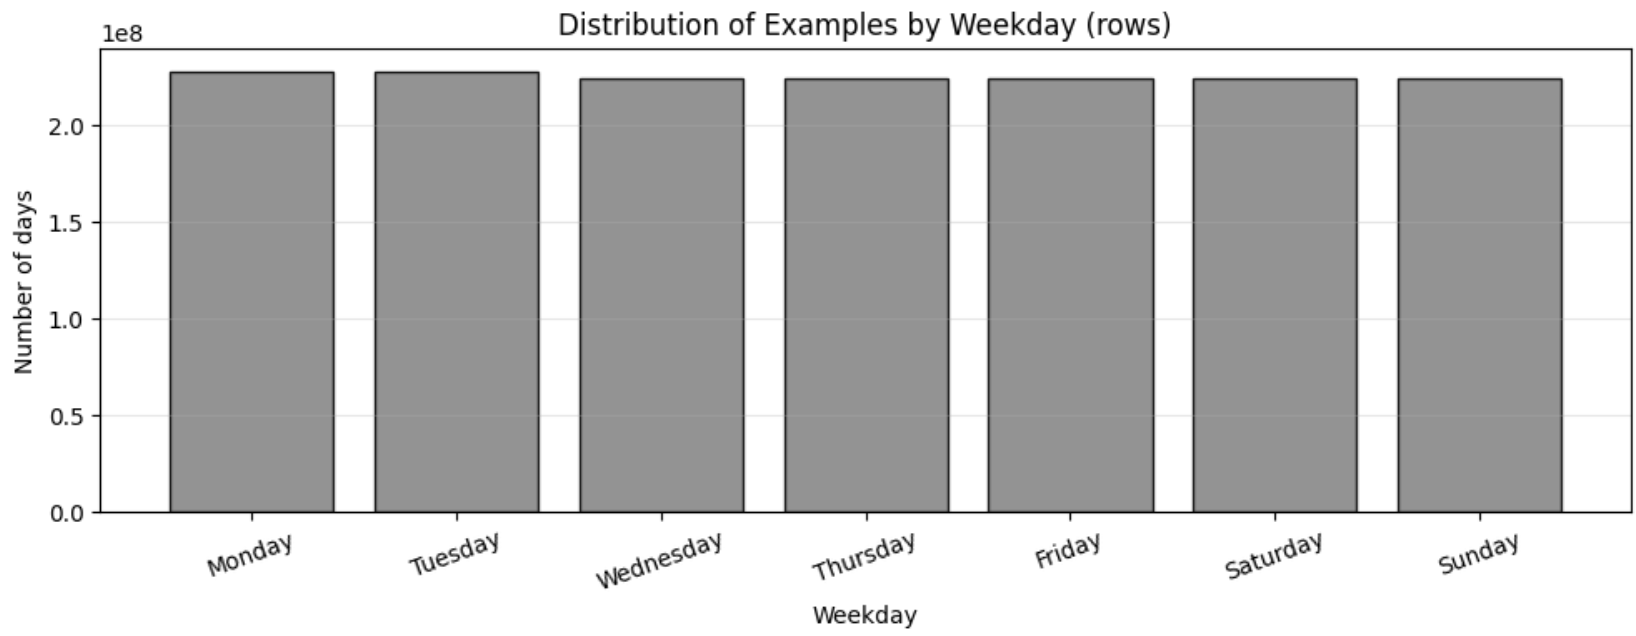